# 経済の中で経済が育つ
## ── 2011年の外作用モデルと「埋め込み」の遷移

## 第 0 章 このノートについて

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
解析・執筆の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

この文書は、「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(以下、ノート 1)の続編である。ノート 1 では、2018〜2020 年に作られた経済シミュレーション `micro_economy_*.py` を解剖した。この文書は、そのさらに前、2011 年に同じ作者が Perl で作った小さな経済シミュレーションから出発する。

2011 年のモデルは、記事の題を「外作用的簡易経済シミュレーションのアイデアと Perl による実装」という。発想は、二つあった。

1. **ルールと戦術を分ける。** 市場のルール(作者の言葉で「外作用」)は、簡易で厳格にする。プレイヤーがルールの中で取れる行動(「内作用」、戦術)は、自由に書けるようにする。そうすれば、少ない数のプレイヤーで、ミクロとマクロのつながりを表す経済モデルが作れるのではないか。
2. **経済の中で経済が育つ。** 経済の一部としてバーチャルに動いている経済が、あるとき突然、全体に「格上げ」される。そういう遷移がありうる。そのとき、それまでの全体の資産は、新しい枠組みで一挙に評価し直される。資産の目減り(減耗)は、少しずつではなく、枠組みの交代として起こる。埋め込まれた経済の中に、さらに元の経済が埋め込まれている(入れ子)こともある。

二つ目の発想を、作者は「埋め込み」と呼んだ。のちに作者は、信用創造のモデルについて、「大小の国のモデルをつないだ経済を、一つの国のモデルとして描けるか」(縮約)という問いを立てて、定理として答えた(「信用の世界経済は一つか」)。その関心は、この 2011 年の「埋め込み」から始まっていた。ただし、二つは同じではない。縮約は、**枠組みが固定されたまま**、全体を粗く描く話である。埋め込みは、**枠組みそのものが入れ替わる**話である。

この文書で考える問いは、次のとおりである。

- 2011 年のモデルは、何をしていたのか。今の目で見て、どこが筋が良く、どこが足りなかったのか。
- 「埋め込み」の中で、まったく違う経済が育つとは、どういうことか。そんなものをモデル化できるのか。
- そのために要る**最低限の経済原理**とは何か。それを書く**抽象的な理論**はあるか。
- それは「縮約」と、どういう関係にあるのか。

あわせて、2011 年のモデルの出発点になった問い、「ペニーオークションは無尽講ではないか」にも答える。

### このシリーズ

同じ作者(JRF)の、AI 以前の経済の模型と構想を、今の目で読み直すシリーズである。書かれた順に並べる(読む順の勧めも同じ)。ノート O の O は Origin(始まり)で、作者の経済のシミュレーションの始まりにあたる 2011 年の模型を扱う。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(`micro_economy_anatomy.ipynb`)
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(`embedded_economy.ipynb`) ← **この文書**
- ノート 2「土地と知財と借金 ── 2019年の資産市場シミュレーションの解剖」(`asset_market.ipynb`)
- ノート P「ポイントと年金と信用 ── ネットの小さな通貨の設計(2006〜2018)」(`points_pension.ipynb`)
- ノート I「必需品と贅沢品の宇宙的独立関係 ── 絶滅の確率、0 × ∞、ナイト的不確実性、そして学習」(`cosmic_independence.ipynb`)
- ノート 3「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」(`simbd_economy.ipynb`)
- ノート M「雑多なモデルの再検討 ── 必需品と贅沢品、縁故主義、投票、AI と弾圧」(`misc_models.ipynb`)
- ノート 4「2026年の経済モデル統合 ── 価格と信用と土地と災害、そして一人の暮らし」(`integrated_model.ipynb`)

### 答えの見通し

1. 2011 年のモデルは、お金を「マイナスの負債」として書いた。だから、お金の総量は自動的に保存される。この点は、ノート 1 で見た 2018 年のモデル(会計に三つの誤りがあった)より筋が良かった。文化(資産)が積み上がっていくことも、作者の意図どおり表されていた。一方で、積み上がった資産を買値のまま評価し、それが次の値付けを押し上げる回り方のために、資産は際限なく増えた。また、負債の相手方がモデルの中におらず、戦術を比べる「良さ」の基準がなかった。さらに、戦術を市場に反映する部分に誤りがあり、戦術は実際には何の効果も持っていなかった。直して試すと、得をする戦術は、安い競争相手に供給を減らさせて値をつり上げる、カルテルの戦術だった。
2. ペニーオークションは、入札料を払って競る仕組みで、理論の上では、売り手の期待収入がちょうど品物の価値に等しくなる均衡を持つ。ただし均衡はたくさんあり、学習するプレイヤーがどの均衡に行くかは、学び方で決まる。無尽講(参加者のあいだでお金が回る)とは、胴元の有無が違う。作者が 2010 年に思い描いていたのは、競りで払った「利息」が仲間に回り、競り落とした者が工作機械を導入できる、入札型の無尽講だった。ペニーオークションは、その利息が胴元に入り、競り落とす物が生産につながらない形である。仮想通貨の採掘は、利息が誰にも入らず燃えてしまう形である。
3. どの経済モデルも、**保存・評価・実現可能性・行動**の四つで書ける。「埋め込み」の遷移とは、このうちの「評価」(価値の物差しと、どれが根の経済か)が入れ替わる出来事である。保存は遷移をまたいで守られるが、評価は不連続に変わる。
4. 経済を対象、集計を射とする「圏」を考えると、縮約は物差しが固定されているあいだの理論で、格上げはその物差しが跳ぶ出来事である。二つは補い合う。
5. 入れ子の経済の小さな模型で、格上げの遷移、資産の一挙の再評価、行きと帰りで道筋が違う履歴現象を起こしてみせられる。現実の例としては、IT 革命のような技術と経済の枠組みの転換、通貨改革、覇権の交代が近い。

### 読み方

- 上から順に、コードのセルを実行すれば全部動く。使うのは numpy, scipy, matplotlib と、Perl(2011 年のコードをそのまま走らせるため。Linux や Google Colab には最初から入っている)。
- 2011 年のコードは、GitHub から決まった版を取ってきて、中身が同じことを sha256 で確かめてから走らせる。
- 2011 年のモデルを Python に移した版(`sm0.py`)も作る。Perl 版と**ぴったり同じ計算**をすることを確かめてから使う(第 1 章)。

### 目次

- 第 0 章 このノートについて
- 第 1 章 2011 年の外作用モデルを動かす
- 第 2 章 解剖: 2011 年のモデルは何をしていたか
- 第 3 章 ペニーオークションと無尽講
- 第 4 章 最低限の経済原理
- 第 5 章 抽象的な理論: 経済の圏
- 第 6 章 入れ子の経済の模型
- 第 7 章 事例
- 第 8 章 縮約との関係
- 第 9 章 まとめと、続くノートへ
- 付録 A: 再現のために
- 付録 B: 用語集
- 付録 C: 過去の議論
- 参考文献

### Lean による証明

v0.1 では Lean を使わず、第 9.5 節の残る問いに「必要になれば、集計が保存を守ること、一物一価の命題、区間ごとの縮約を Lean で証明する」と書いた。v0.2 で、前の二つと、ペニーオークションの混合均衡の条件を、v0.2.1 で区間ごとの縮約を、**Lean 4**(と Mathlib)で証明した。章ごとに `%%writefile -a embedded_economy.lean` で書き足し、第 9 章の最後で一括して確かめる。

| 章 | 定理 | 中身 |
|---|---|---|
| 3 | `penny_indifference`、`penny_prob_le_one` | 続かない確率が c / (v − p) なら、入札の得の期待値は 0(無差別)。その確率が 1 以下なのは、費用が残りの値打ち以下のとき |
| 5 | `internal_trade_vanishes`、`aggregate_in_stages`、`one_price_iff`、`constant_composition` | 組の中の受け払いは、まとめると消える(バーチャルになる)。段階的にまとめても総和は同じ。まとめても評価が自然なのは、組の中の値段が等しいとき、そのときに限る(一物一価)。構成が一定なら指数で評価はずれない |
| 8 | `contraction_iterate`、`contraction_hybrid`、`jump_depends_on_share`、`one_point_reset_not_commuting`、`two_point_reset_commutes` | 区間ごとの縮約: モードの中で 1 期が可換なら何期でも可換、流れとリセットが可換なら道全体が可換。一点へのまとめは評価の跳び(リセット)と可換にならず、根の候補ごとの二点なら可換 |

In [1]:
%%writefile embedded_economy.lean
/-
  「経済の中で経済が育つ」(ノート O)の Lean による定式化
  文責: JRF / 定式化・証明: Claude Opus 5.5
  Lean 4 v4.34.1 + Mathlib
-/
import Mathlib

open Finset

namespace EmbeddedEconomy

Overwriting embedded_economy.lean


### 準備

In [2]:
import os, time, importlib, shutil, multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt

FAST = False                       # True にすると回数を減らして速く回す
N_JOBS = int(os.environ.get('NB_JOBS', max(1, (os.cpu_count() or 2) - 1)))   # 並列の数(環境変数 NB_JOBS で減らせる)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})


def pmap(f, jobs):
    """jobs を並列に f で計算する。f は %%writefile で書いたモジュールの関数にする。"""
    with mp.get_context('fork').Pool(min(N_JOBS, len(jobs))) as pool:
        return pool.map(f, jobs)


import scipy, matplotlib, subprocess
perl_v = subprocess.run(['perl', '-e', 'print $^V'], capture_output=True, text=True).stdout
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__, '/ perl', perl_v, '/ CPU', os.cpu_count())

numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2 / perl v5.40.1 / CPU 28


## 第 1 章 2011 年の外作用モデルを動かす

### 1.1 モデルの部品

2011 年のモデル(`simple_market_0.pl`)の登場するものを、コードに従って書く。

**プレイヤー**(既定は 5 人)は、それぞれ次のものを持つ。

- **asset**(資産): 嗜好品を買うと増える。作者は「文化資本」と呼んでいる。初期値は 5。
- **liability**(負債): 物を買うと増え、売ると減る。**現金は「マイナスの負債」**として表す。負債が −3 なら、3 だけ現金を持っている、という意味である。初期値は 10。
- **possession**(持分権): 必需品を作る権利。「持分(quota)」と「残りの期間(term)」の組で、期間が切れると、別のプレイヤーにランダムに割り当て直される。耕作地の所有権のようなイメージである。

**財**は二種類ある。

- **必需品**(既定は 3 種類): 持分権を持つプレイヤーが、毎期ランダムな量を作る。全員が、毎期、決まった量(必要量 = 人数 × 0.7)を消費する。
- **嗜好品**(既定は 2 種類): 毎期、各プレイヤーが一定の確率で一個ずつ作る。作った人が希望価格をつけ、欲しい人が買う。

**一期の流れ**は次の順である。

1. **生産**: 持分権に応じて必需品を作る。嗜好品は、確率 $1 - 1/\text{人数}$ で「作れず」、作れたら希望価格をつける(asset が大きいほど高い値をつけやすい)。
2. **必需品の売りたさ(greed)**: 作った量が持分に比べて少ないほど、また負債が大きいほど、高く売りたがる。
   $$\text{greed} = \exp\!\Big(1 - \big(\tfrac{\text{生産量}}{\text{持分}}\big)^2\Big)\cdot\sqrt{\text{負債}}\quad(\text{負債が小さいときは } \log(1 + e^{\text{負債}}) \text{ でなめらかに})$$
3. **必需品の取引**: 売り手を greed の低い順に並べ、必要量に達するまで集める。集めた分の「greed × 量」の合計を、**全員で等分して払い**、**売り手には生産量に比例して配る**。
4. **嗜好品の欲しさ(desire)**: 各プレイヤーは、各嗜好品について、正規分布の乱数で desire を決める。平均は「その嗜好品の希望価格の平均 × 0.7 × 景気」、ばらつきは $\sqrt{\text{asset}}$。景気は、必需品の消費額が前の期より増えたかどうかで決まる($\frac{4}{\pi}\arctan$ の形)。
5. **嗜好品の取引**: desire の高い順に買い手を、希望価格の安い順に売り手を並べ、競りのように組み合わせる(詳しくは第 2 章)。買い手は asset と負債が同時に増え、売り手は負債が減る。
6. **持分権の割り当て直し**: 期間の切れた持分権を、ランダムなプレイヤーに割り当て直す。

乱数には、記事の言う「下限だけがあって、最も起こりやすい値を持つ乱数」として、正規乱数の絶対値の平方根($\sqrt{|N|}$)が使われている。

### 1.2 Perl のコードを、そのまま走らせる

2011 年のコードを、GitHub から取ってきて走らせる道具を書く。

一つ注意がある。今の Perl(5.18 以降)は、ハッシュ(連想配列)のキーを取り出す順序を、実行するたびに変える。このコードは、プレイヤーや財をハッシュの順に処理する所が多いので、乱数の種(`--srand`)を固定しても、結果が毎回変わってしまう。2011 年当時の Perl は、この順序が固定だった。そこで、環境変数で順序を固定して走らせる。

In [3]:
%%writefile sm0_perl.py
"""sm0_perl.py -- 2011 年の simple_market_0.pl を取ってきて、そのまま(または順序だけ直して)走らせる道具。"""
import os, re, hashlib, subprocess, urllib.request

COMMIT = 'c03bbcb1f60ee6913a5f14ab54c68026371b20f4'
URL = f'https://raw.githubusercontent.com/JRF-2018/simple_market_0/{COMMIT}/simple_market_0.pl'
SHA256 = '469be93645170c45116f9501f185cd1ff0285f8a243ff01368897a9b08f00c9a'
CACHE = 'orig_cache'
# 今の Perl(5.18 以降)はハッシュの順序を実行ごとに変える。2011 年当時のように固定する。
ENV = dict(os.environ, PERL_HASH_SEED='0', PERL_PERTURB_KEYS='0')


def fetch():
    os.makedirs(CACHE, exist_ok=True)
    path = os.path.join(CACHE, 'simple_market_0.pl')
    if not os.path.exists(path):
        with urllib.request.urlopen(URL, timeout=60) as r:
            open(path, 'wb').write(r.read())
    data = open(path, 'rb').read()
    if hashlib.sha256(data).hexdigest() != SHA256:
        raise ValueError('simple_market_0.pl: sha256 が違う')
    return path


PATCH_TACTICS = [('if (exists $pricemap2->{$pid}) {', 'if (exists $pricemap2->{$cid}->{$pid}) {'),
                 ('if (exists $prodmap2->{$pid}) {', 'if (exists $prodmap2->{$cid}->{$pid}) {')]


def source(sorted_keys=False, fix_tactics=False):
    """元のコードに、順序だけの直し(sorted_keys)と、戦術の反映の直し(fix_tactics、2 か所)を当てた版を書き出す。"""
    src = open(fetch(), encoding='utf-8').read()
    if fix_tactics:
        for a, b in PATCH_TACTICS:
            assert src.count(a) == 1, a
            src = src.replace(a, b)
    out = []
    for line in src.split('\n'):
        if sorted_keys and 'keys %' in line and 'scalar(keys' not in line and '== (keys' not in line and not line.lstrip().startswith('#'):
            line = line.replace('(keys %', '(sort keys %').replace('= keys %', '= sort keys %')
        out.append(line)
    path = os.path.join(CACHE, f'simple_market_0_{int(sorted_keys)}{int(fix_tactics)}.pl')
    tmp = f'{path}.{os.getpid()}'          # 並列に呼ばれても壊れないよう、書いてから名前を替える
    open(tmp, 'w', encoding='utf-8').write('\n'.join(out))
    os.replace(tmp, path)
    return path


def sorted_keys_source():
    """順序だけを直した版: 繰り返しに使う keys を sort keys にする(数を数える所は変えない)。"""
    return source(sorted_keys=True)


def run(args, sorted_keys=False, fix_tactics=False, debug=False, luxury=False):
    """perl を走らせ、--tactics-dumper の出力から、期ごとの各プレイヤーの (asset, liability) の文字列を返す。
    luxury=True なら、各期の嗜好品の購入額の合計と件数も返す。debug=True はデバッグ実行(-d1。戦術が市場を直接操作する)。"""
    path = source(sorted_keys, fix_tactics) if (sorted_keys or fix_tactics) else fetch()
    out = subprocess.run(['perl', path, '-d1' if debug else '-d0', '--tactics-dumper'] + list(args), env=ENV,
                         capture_output=True, text=True, check=True).stdout
    hist, lux = [], []
    for block in re.split(r'^TERM\d+:\n', out, flags=re.M)[2:]:     # 最初の TERM の前は空、TERM000 は初期状態
        st, vol, cnt = {}, 0.0, 0
        for pid, body in re.findall(r"\n    (P\d+) => bless\( \{(.*?)\n    \}, 'Main::_Player' \)", block, flags=re.S):
            a = re.search(r'\n      asset => "?([^",\n]+)"?', body).group(1)
            l = re.search(r'\n      liability => "?([^",\n]+)"?', body).group(1)
            st[pid] = (a, l)
            m = re.search(r'current_consumption_luxury => \{(.*?)\}', body, flags=re.S)
            if m:
                for v in re.findall(r'=> "?([-\d.e+]+)"?', m.group(1)):
                    vol += float(v); cnt += 1
        hist.append(st); lux.append((vol, cnt))
    return (hist, lux) if luxury else hist

Overwriting sm0_perl.py


simple_market_0.pl: commit c03bbcb 、sha256 一致


Perl で 20 人・200 期: 0.3 秒


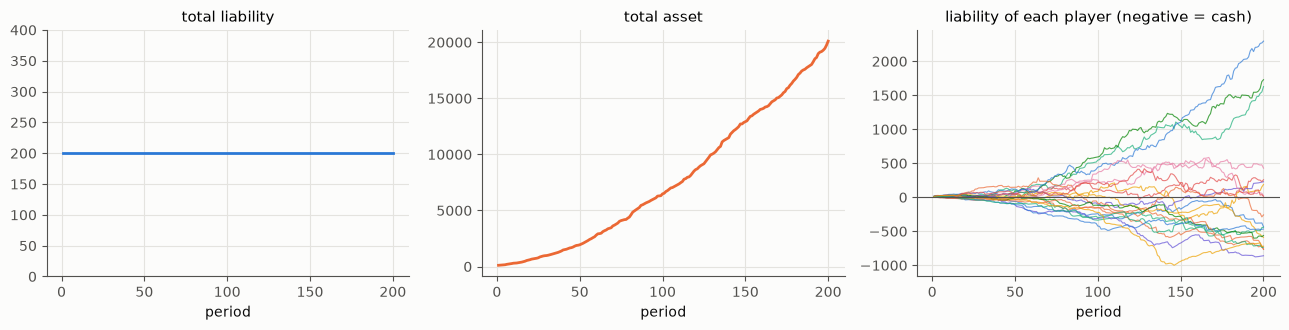

総 liability: 最初 200.000000、最後 200.000000
総 asset: 10 期 297.3、100 期 6482.9、200 期 20096.3


In [4]:
import sm0_perl
importlib.reload(sm0_perl)
sm0_perl.fetch()
print('simple_market_0.pl: commit', sm0_perl.COMMIT[:7], '、sha256 一致')
args = ['--srand=0', '--term=200', '--player=20', '--luxury=4', '--essential=3']
t0 = time.time()
H = sm0_perl.run(args)
print(f'Perl で 20 人・200 期: {time.time() - t0:.1f} 秒')
A = np.array([[float(a) for a, l in st.values()] for st in H])
L = np.array([[float(l) for a, l in st.values()] for st in H])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
t = np.arange(1, len(H) + 1)
ax[0].plot(t, L.sum(1), color=PAL[0]); ax[0].set(title='total liability', xlabel='period', ylim=(0, 400))
ax[1].plot(t, A.sum(1), color=PAL[1]); ax[1].set(title='total asset', xlabel='period')
for j in range(L.shape[1]):
    ax[2].plot(t, L[:, j], color=PAL[j % len(PAL)], lw=0.8, alpha=0.7)
ax[2].axhline(0, color=INK2, lw=0.8); ax[2].set(title='liability of each player (negative = cash)', xlabel='period')
plt.tight_layout(); plt.show()
print(f'総 liability: 最初 {L[0].sum():.6f}、最後 {L[-1].sum():.6f}')
print(f'総 asset: 10 期 {A[9].sum():.1f}、100 期 {A[99].sum():.1f}、200 期 {A[-1].sum():.1f}')

三つのことが見える。

- **総 liability は、ぴったり一定である。** お金(マイナスの負債)は、プレイヤーのあいだを移るだけで、生まれも消えもしない。
- **総 asset は、際限なく増える。** asset は嗜好品を買った値段で積み上がり、目減りしない。
- **個人の liability は、時とともに大きく広がる。** 大きな借金を抱える人と、大きな現金を持つ人に分かれていく。

なぜこうなるかは、第 2 章で解剖する。その前に、このモデルを Python に移しておく。改造して調べるには、そのほうが楽だからである。

### 1.3 Python に移す: ぴったり同じ計算にする

移すときの方針は、ノート 1 と同じく、**元のコードと同じ計算をしていることを確かめてから使う**ことである。今回は、統計的に似ているだけでなく、**一桁も違わない**ことを目指す。そのために、三つのことに気をつける。

1. **乱数**: Perl 5.20 以降の `rand` は、Perl 自身が持つ drand48(48 ビットの線形合同法)で作られている。これは式が公開されているので、Python でそのまま書ける。
2. **ガンマ関数**: このコードは、Perl の数学ライブラリ(Math::GSL など)があればそれを、なければ自前の近似式を使う。普通の環境には入っていないので、近似式が使われる。それも、そのまま書く。
3. **順序**: 1.2 で見たとおり、Perl のハッシュの順序は決まっていない。移した版では、キーを辞書順に並べて処理する。比べる相手の Perl 側も、**繰り返しの順序だけを辞書順に直した版**にする(`keys` を `sort keys` にする。数を数えるだけの所は変えない)。順序が変われば乱数の使われ方が変わるので、結果の数値は 1.2 とは違うが、モデルとしては同じものである。2011 年当時の Perl の順序も、たまたま決まっていた一つの順序にすぎない。

In [5]:
%%writefile sm0.py
"""sm0.py -- JRF の simple_market_0.pl(2011)を Python に移したもの。

ねらいは「完全に同じ計算」。そのために次のことを Perl と同じにする。
  - 乱数: Perl 5.20 以降の rand は、自前の drand48(48 ビットの線形合同法)。それをそのまま書く。
  - ガンマ関数: Perl 版は、Math::GSL などが無いと自前の近似(_approx_gamma)を使う。それをそのまま書く。
  - 繰り返しの順序: Perl のハッシュの順序は決まっていないので、Perl 側を「キーの辞書順」に直した版(順序だけの差分)と比べる。
"""
import math

PI = math.pi
POW = 0.5                 # $Pow
ETERMMAX = 20             # 持分権の期間の上限


class Drand48:
    """Perl の rand と同じ乱数(srand(seed) のあとの rand(1))。"""
    def __init__(self, seed):
        self.x = (0x330E + (seed << 16)) & ((1 << 48) - 1)

    def rand(self, n=1.0):
        self.x = (self.x * 0x5DEECE66D + 0xB) & ((1 << 48) - 1)
        return n * (self.x / 2.0 ** 48)


def approx_gamma(x):
    """Perl 版の _approx_gamma(近似。厳密なガンマ関数ではない)。"""
    G = 0.57721566490153286060651209008240243104215933593992
    def mini(x):
        return (1 / x) - G + (1 / 6) * (3 * G * G + PI * PI / 2) * x
    r = 1.0
    if x < 0:
        while x < 0:
            r *= 1 / x; x += 1
    else:
        while x - 1 > 0:
            r *= (x - 1); x -= 1
    if x == 1.0: return r
    if x == 0.0: return r * math.inf
    if x == 0.5: return r * math.sqrt(PI)
    if 0 < x < 0.5: return r * mini(x)
    return r * (PI / math.sin(PI * x)) / mini(1 - x)

Overwriting sm0.py


In [6]:
%%writefile -a sm0.py
class Rand:
    """乱数の道具(Perl の Math::Aux と同じ式・同じ順序で乱数を引く)。"""
    def __init__(self, seed):
        self.g = Drand48(seed)

    def normal(self, mean=0.0, variance=1.0):
        # 元のコードの名前は variance だが、実際には標準偏差として使っている
        u1 = self.g.rand(1)
        u2 = self.g.rand(1)
        return mean + (variance * math.sqrt(-2 * math.log(1.0 - u1)) * math.cos(PI * u2))

    def powered_normal(self, mean, variance, pw):
        r = self.normal(0, variance)
        if r == 0.0:
            return mean
        return abs(r) ** pw + mean

    @staticmethod
    def variance_for_mean_of_pnr(mean, pw):
        return (mean * math.sqrt(PI) / approx_gamma((pw + 1) / 2)) ** (1 / pw) / math.sqrt(2)

Appending to sm0.py


In [7]:
%%writefile -a sm0.py
class Player:
    def __init__(self, pid, asset, liability):
        self.id = pid
        self.asset = float(asset)
        self.liability = float(liability)
        self.possession = {}          # cid -> {'quota': int, 'term': float}
        self.desire = {}
        self.greed = {}


class Market:
    """simple_market_0.pl の Main::_Market と同じ一期の計算。"""
    def __init__(self, seed=0, players=5, luxuries=2, essentials=3, initial_asset=5, initial_liability=10,
                 ess_rule='orig', lux_rule='orig', delta=0.0):
        # ess_rule: 必需品の代金の決め方('orig' 元のまま、'uniform' 一律価格、'pay_as_bid' 希望どおりの支払い)
        # lux_rule: 嗜好品の組み合わせ方('orig' 元のまま、'call' 一つの価格で清算するコール市場)
        # delta: asset の毎期の減耗率(元は 0)
        self.ess_rule, self.lux_rule, self.delta = ess_rule, lux_rule, delta
        self.lux_volume, self.lux_count = 0.0, 0
        self.R = Rand(seed)
        self.player = {f'P{i + 1:03d}': Player(f'P{i + 1:03d}', initial_asset, initial_liability) for i in range(players)}
        n = 0
        self.luxury = {}
        for i in range(luxuries):
            n += 1
            self.luxury[f'C{n:03d}'] = dict(difficulty=1 - 1.0 / players, simplicity=0.7)
        self.essential = {}
        for i in range(essentials):
            n += 1
            cid = f'C{n:03d}'
            self.essential[cid] = dict(need=players * 0.7)
            self.random_attach(cid, math.ceil(players * 0.8))
        self.current_essential = {}   # cid -> {pid: 生産量}
        self.current_luxury = {}      # cid -> {pid: 希望価格}
        self.cur_gross = 0.0
        self.prev_gross = 0.0
        self.term = 0

    # 持分権の割り当て(Main::_EssentialCommodity::random_attach)
    def random_attach(self, cid, newquota):
        while newquota > 0:
            newquota -= 1
            newterm = self.R.g.rand(ETERMMAX)
            p = sorted(self.player)
            pid = p[int(self.R.g.rand(len(p)))]
            pos = self.player[pid].possession
            if cid in pos:
                pos[cid]['term'] = pos[cid]['term'] + (newterm / (1 + pos[cid]['quota']))
                pos[cid]['quota'] += 1
            else:
                pos[cid] = {'quota': 1, 'term': newterm}

    def produce(self):
        for pid in sorted(self.player):
            p = self.player[pid]
            for cid in sorted(p.possession):
                quota = p.possession[cid]['quota']
                v = Rand.variance_for_mean_of_pnr(quota, POW)
                self.current_essential.setdefault(cid, {})[pid] = self.R.powered_normal(0, v, POW)
        for pid in sorted(self.player):
            p = self.player[pid]
            for cid in sorted(self.luxury):
                c = self.luxury[cid]
                if self.R.g.rand(1) < c['difficulty']:
                    continue                     # 作れなかった(元のコードは 0 を返し、0 は記録しない)
                v = Rand.variance_for_mean_of_pnr(math.log(1 + p.asset), POW)
                cur = self.R.powered_normal(0, v, POW)
                if cur:
                    self.current_luxury.setdefault(cid, {})[pid] = cur

    def demand_essential(self):
        for pid in sorted(self.player):
            p = self.player[pid]
            for cid in sorted(self.current_essential):
                if pid in self.current_essential[cid]:
                    prod = self.current_essential[cid][pid]
                    quota = p.possession[cid]['quota']
                    mag = math.exp(1 - (prod / quota) ** (1 / POW))
                    lia = p.liability if p.liability > 100 else math.log(1 + math.exp(p.liability))
                    p.greed[cid] = mag * math.sqrt(lia)

    def match_greed(self, cid, prodmap):
        producer = sorted(sorted(prodmap), key=lambda pid: self.player[pid].greed[cid])
        total_prod = 0.0
        for pid in producer:              # sum() は Python 3.12 から補正つきの和なので使わない(Perl と同じ順に足す)
            total_prod += prodmap[pid]
        total, need, i = 0.0, self.essential[cid]['need'], 0
        while need > 0 and i < len(producer):
            pid = producer[i]; i += 1
            greed, prod = self.player[pid].greed[cid], prodmap[pid]
            if need < prod:
                total += greed * need; need = 0
            else:
                total += greed * prod; need -= prod
        buyer_price = total / len(self.player)
        seller_price = {pid: prodmap[pid] * total / total_prod for pid in producer}
        return buyer_price, seller_price

    def consume_essential(self):
        for cid in sorted(self.current_essential):
            if self.ess_rule == 'orig':
                buyer_price, seller_price = self.match_greed(cid, self.current_essential[cid])
            else:
                buyer_price, seller_price = self.match_greed_alt(cid, self.current_essential[cid])
            for pid in sorted(seller_price):
                self.player[pid].liability -= seller_price[pid]
            for pid in sorted(self.player):
                self.player[pid].liability += buyer_price
            self.cur_gross = buyer_price * len(self.player)    # 元のコードどおり、最後の財の値で上書き

    def match_greed_alt(self, cid, prodmap):
        """別の決め方: greed の低い順に必要量まで買い、'uniform' なら最後に買った売り手の greed で一律に、
        'pay_as_bid' なら各自の greed で払う。必要量を超えて作った分には払わない。"""
        producer = sorted(sorted(prodmap), key=lambda pid: self.player[pid].greed[cid])
        need, sold = self.essential[cid]['need'], {}
        for pid in producer:
            if need <= 0:
                break
            q = min(need, prodmap[pid]); sold[pid] = q; need -= q
        if self.ess_rule == 'uniform':
            marginal = self.player[list(sold)[-1]].greed[cid] if sold else 0.0
            pay = {pid: marginal * q for pid, q in sold.items()}
        else:
            pay = {pid: self.player[pid].greed[cid] * q for pid, q in sold.items()}
        total = 0.0
        for pid in pay:
            total += pay[pid]
        return total / len(self.player), pay

    def demand_luxury(self):
        lprice = {}
        for cid in sorted(self.current_luxury):
            total, n = 0.0, 0
            for pid in sorted(self.current_luxury[cid]):
                total += self.current_luxury[cid][pid]; n += 1
            lprice[cid] = self.luxury[cid]['simplicity'] * (total / n)
        for pid in sorted(self.player):
            p = self.player[pid]
            for cid in sorted(self.current_luxury):
                r = (4 / PI) * math.atan2(self.cur_gross, self.prev_gross)
                p.desire[cid] = self.R.normal(r * lprice[cid], math.sqrt(p.asset))

    def match_desire(self, cid, pricemap):
        producer = sorted(sorted(pricemap), key=lambda pid: pricemap[pid])
        desire = [pid for pid in sorted(self.player) if cid in self.player[pid].desire]
        desire = sorted(desire, key=lambda pid: -self.player[pid].desire[cid])
        match = []
        while producer and desire:
            p = producer[0]
            d = desire.pop(0)
            price = pricemap[p]
            if self.player[d].desire[cid] < price:
                break
            if desire:
                rival = desire[0]
                if self.player[rival].desire[cid] > price:
                    price = self.player[rival].desire[cid]
            producer = [q for q in producer if pricemap[q] <= price]
            match.insert(0, [price, d] + list(producer))
            if producer:
                producer.pop()
        sold, prev_price = 0, 0.0
        out = []
        for m in match:
            price, d, rest = m[0], m[1], m[2:]
            p = rest[sold]; sold += 1
            seller_price = pricemap[p]
            if len(rest) > sold:
                price = seller_price if seller_price > prev_price else prev_price
            out.append((price, d, p))
            prev_price = price
        return out

    def consume_luxury(self):
        self.lux_volume, self.lux_count = 0.0, 0
        for cid in sorted(self.current_luxury):
            pricemap = self.current_luxury[cid]
            matches = self.match_desire(cid, pricemap) if self.lux_rule == 'orig' else self.match_call(cid, pricemap)
            for price, d, p in matches:
                self.player[d].asset += price
                self.player[d].liability += price
                self.player[p].liability -= price
                self.lux_volume += price; self.lux_count += 1
        if self.delta:
            for p in self.player.values():
                p.asset *= (1 - self.delta)

    def match_call(self, cid, pricemap):
        """コール市場: 売り手の希望価格を安い順、買い手の desire を高い順に並べ、成り立つ数 k だけ、一つの価格で取引する。
        価格は k 番目の売り手の希望と k 番目の買い手の desire の中点。"""
        asks = sorted(sorted(pricemap), key=lambda pid: pricemap[pid])
        bids = sorted([pid for pid in sorted(self.player) if cid in self.player[pid].desire],
                      key=lambda pid: -self.player[pid].desire[cid])
        k = 0
        while k < min(len(asks), len(bids)) and self.player[bids[k]].desire[cid] >= pricemap[asks[k]]:
            k += 1
        if k == 0:
            return []
        price = (pricemap[asks[k - 1]] + self.player[bids[k - 1]].desire[cid]) / 2
        return [(price, bids[i], asks[i]) for i in range(k)]

    def attach(self):
        newquota = {}
        for pid in sorted(self.player):
            p = self.player[pid]
            for cid in sorted(p.possession):
                quota = p.possession[cid]['quota']
                term = p.possession[cid]['term'] - 1
                if term <= 0:
                    del p.possession[cid]
                    newquota[cid] = newquota.get(cid, 0) + quota
                else:
                    p.possession[cid]['term'] = term
        for cid in sorted(newquota):
            self.random_attach(cid, newquota[cid])

    def cleanup(self):
        for p in self.player.values():
            p.desire, p.greed = {}, {}
        self.current_essential, self.current_luxury = {}, {}
        self.prev_gross, self.cur_gross = self.cur_gross, 0.0

    def step(self):
        self.term += 1
        self.produce()
        self.demand_essential()
        self.consume_essential()
        self.demand_luxury()
        self.consume_luxury()
        self.attach()
        self.cleanup()

    def snapshot(self):
        return {pid: (p.asset, p.liability) for pid, p in sorted(self.player.items())}


def run(T, **kw):
    m = Market(**kw)
    hist = []
    for t in range(T):
        m.step()
        hist.append(m.snapshot())
    return hist

Appending to sm0.py


In [8]:
import sm0, difflib, math
importlib.reload(sm0)
g = sm0.Drand48(0)
perl_r = subprocess.run(['perl', '-e', 'srand(0); printf "%.17g %.17g", rand(1), rand(1)'], capture_output=True, text=True).stdout
print('Perl の rand  :', perl_r)
print('Python の再現 :', '%.17g %.17g' % (g.rand(), g.rand()))
print(f'ガンマ関数 Γ(0.75): Perl 版の近似 {sm0.approx_gamma(0.75):.6f}、正しい値 {math.gamma(0.75):.6f}')
orig = open(sm0_perl.fetch(), encoding='utf-8').read().split('\n')
srt = open(sm0_perl.sorted_keys_source(), encoding='utf-8').read().split('\n')
d = [l for l in difflib.unified_diff(orig, srt, lineterm='', n=0) if l[:1] in '+-' and l[:3] not in ('+++', '---')]
print(f'順序だけを直した差分: {len(d) // 2} 行(はじめの 3 行)')
for l in d[:6]:
    print('   ', l.strip())

Perl の rand  : 0.17082803610628972 0.74990198048496381
Python の再現 : 0.17082803610628972 0.74990198048496381
ガンマ関数 Γ(0.75): Perl 版の近似 1.210579、正しい値 1.225417
順序だけを直した差分: 41 行(はじめの 3 行)
    -      my @p = keys %$players;
    +      my @p = sort keys %$players;
    -    foreach my $cid (keys %{$market->{current_essential}}) {
    +    foreach my $cid (sort keys %{$market->{current_essential}}) {
    -      foreach my $pid (keys %$owe) {
    -	foreach my $to (keys %{$owe->{$pid}}) {


Perl の `rand` と、Python で書いた drand48 は、17 桁まで一致する。ガンマ関数の近似は、正しい値と 1% ほど違う(0.75 での値)。これは「2011 年のモデルの一部」なので、そのまま使う。

もう一つ、Python 側の落とし穴があった。Python 3.12 から、浮動小数点数の `sum()` は、丸め誤差を補正する足し算(Neumaier の方法)になった。Perl の素朴な足し算とは、最後の桁が違うことがある。だから、移した版では `sum()` を使わず、Perl と同じ順に一つずつ足している。

では、Perl(順序を直した版)と移した版を、乱数の種・人数・財の数を変えて 200 期ずつ回し、各期の全プレイヤーの asset と liability を比べる。Perl の出力(Data::Dumper)は 15 桁で数を書くので、15 桁で比べる。

In [9]:
def compare(a):
    seed, P, L, E, T = a
    Hp = sm0_perl.run([f'--srand={seed}', f'--term={T}', f'--player={P}', f'--luxury={L}', f'--essential={E}'], sorted_keys=True)
    Q = sm0.run(T, seed=seed, players=P, luxuries=L, essentials=E)
    for t in range(T):
        if {k: ('%.15g' % x, '%.15g' % y) for k, (x, y) in Q[t].items()} != Hp[t]:
            return a, t + 1
    return a, None


# compare は %%writefile したモジュールの関数ではないので、ここでは順に回す
jobs = [(s, P, L, E, 200) for s in (0, 1, 7) for (P, L, E) in ((5, 2, 3), (20, 4, 3), (8, 1, 5))]
t0 = time.time()
for a, bad in map(compare, jobs):
    print(f'seed {a[0]}、{a[1]:2d} 人、嗜好品 {a[2]}、必需品 {a[3]}: ' + ('200 期すべて一致' if bad is None else f'{bad} 期目で不一致'))
print(f'({time.time() - t0:.0f} 秒)')

seed 0、 5 人、嗜好品 2、必需品 3: 200 期すべて一致


seed 0、20 人、嗜好品 4、必需品 3: 200 期すべて一致
seed 0、 8 人、嗜好品 1、必需品 5: 200 期すべて一致


seed 1、 5 人、嗜好品 2、必需品 3: 200 期すべて一致


seed 1、20 人、嗜好品 4、必需品 3: 200 期すべて一致
seed 1、 8 人、嗜好品 1、必需品 5: 200 期すべて一致


seed 7、 5 人、嗜好品 2、必需品 3: 200 期すべて一致


seed 7、20 人、嗜好品 4、必需品 3: 200 期すべて一致
seed 7、 8 人、嗜好品 1、必需品 5: 200 期すべて一致
(2 秒)


9 通りの設定すべてで、200 期のあいだ、全プレイヤーの asset と liability が 15 桁まで一致する。移した版 `sm0.py` は、2011 年のモデルと**同じ計算**をしている。

### 1.4 多数回で見る

移した版を使って、乱数の種を変えて 100 回(各 20 人、200 期)回し、1.2 で見た三つのことが一般的かを確かめる。

In [10]:
%%writefile -a sm0.py
def summary(a):
    """(seed, 期数, 人数, 嗜好品の数, 必需品の数[, 設定の dict]) → 期ごとの
    (総 asset, 総 liability, liability の標準偏差, asset の最大, 嗜好品の取引額, 嗜好品の取引数)。"""
    seed, T, P, L, E = a[:5]
    opts = a[5] if len(a) > 5 else {}
    m = Market(seed=seed, players=P, luxuries=L, essentials=E, **opts)
    rows = []
    for t in range(T):
        m.step()
        A = [p.asset for p in m.player.values()]
        Lb = [p.liability for p in m.player.values()]
        mean = sum(Lb) / len(Lb)
        rows.append((sum(A), sum(Lb), (sum((x - mean) ** 2 for x in Lb) / len(Lb)) ** 0.5, max(A), m.lux_volume, m.lux_count))
    return rows

Appending to sm0.py


総 liability の変動の最大(全 100 回): 1.2e-11


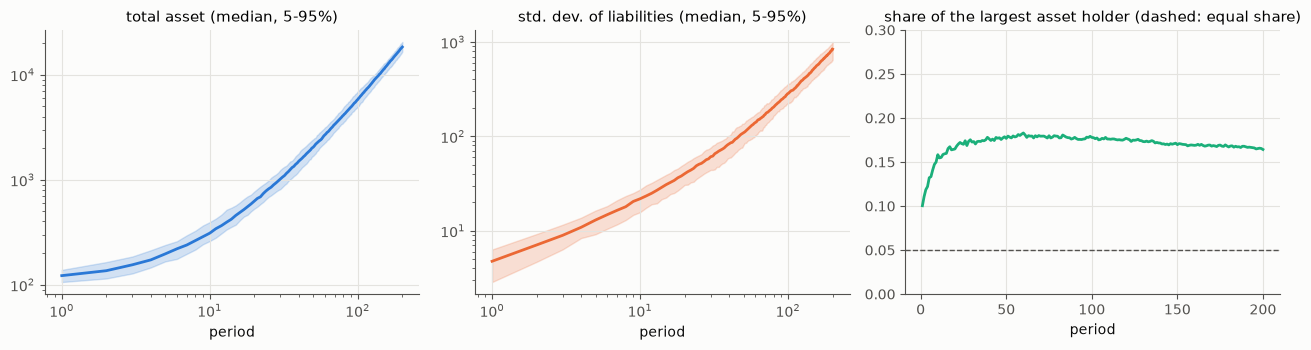

総 asset: 中央値は 51〜200 期で、ほぼ 期数^1.60 で増える
liability の標準偏差: 中央値は 51〜200 期で、ほぼ 期数^1.48 で増える


In [11]:
importlib.reload(sm0)
n_runs = 30 if FAST else 100
R = np.array(pmap(sm0.summary, [(s, 200, 20, 4, 3) for s in range(n_runs)]))   # 回 × 期 × (総 asset, 総 liability, liability の sd, asset の最大)
TA, TL, SD, MX = R[:, :, 0], R[:, :, 1], R[:, :, 2], R[:, :, 3]
t = np.arange(1, R.shape[1] + 1)
print(f'総 liability の変動の最大(全 {n_runs} 回): {np.ptp(TL, axis=1).max():.1e}')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (X, lab) in enumerate(((TA, 'total asset'), (SD, 'std. dev. of liabilities'))):
    ax[k].fill_between(t, np.percentile(X, 5, 0), np.percentile(X, 95, 0), color=PAL[k], alpha=0.2)
    ax[k].plot(t, np.median(X, 0), color=PAL[k])
    ax[k].set(xscale='log', yscale='log', xlabel='period', title=lab + ' (median, 5-95%)')
ax[2].plot(t, np.median(MX / TA, 0), color=PAL[2]); ax[2].axhline(1 / 20, color=INK2, ls='--', lw=1)
ax[2].set(ylim=(0, 0.3), xlabel='period', title='share of the largest asset holder (dashed: equal share)')
plt.tight_layout(); plt.show()
for name, X in (('総 asset', TA), ('liability の標準偏差', SD)):
    b = np.polyfit(np.log(t[50:]), np.log(np.median(X, 0)[50:]), 1)[0]
    print(f'{name}: 中央値は 51〜200 期で、ほぼ 期数^{b:.2f} で増える')

- 総 liability は、どの回でも一定である(変動は計算機の丸め誤差の大きさ)。
- 総 asset は、期数のほぼ 1.6 乗で増える。直線より速いが、指数関数ほど速くはない。
- liability のばらつき(標準偏差)は、期数のほぼ 1.5 乗で広がる。もし毎期、同じ大きさのランダムな受け払いをくり返すだけなら、ばらつきは期数の 0.5 乗(ランダムウォーク)でしか広がらない。それよりずっと速いのは、asset が増えるにつれて嗜好品の値段も上がり、受け払いの大きさそのものが大きくなっていくからである。
- 一番 asset を持つプレイヤーの取り分は、20 人なら平等で 5% のところ、16〜18% ほどで落ち着く。

このモデルの経済は、**お金の量は変わらないのに、資産の値打ちだけが膨らみ続け、貸し借りの格差が加速度的に広がる**経済である。次の章で、その理由を部品ごとに見ていく。

## 第 2 章 解剖: 2011 年のモデルは何をしていたか

第 1 章で、このモデルが「お金の量は変わらないのに、資産の値打ちだけが膨らみ続け、貸し借りの格差が加速度的に広がる」経済であることを見た。この章では、その理由を、部品ごとに調べる。

### 2.1 会計: 現金はマイナスの負債

このモデルには「現金」という変数がない。負債(liability)が、マイナスになったら現金を持っていることになる。すべての受け払いは、

- 払う側の liability を増やし、
- 受け取る側の liability を同じ額だけ減らす、

という形で書かれている。必需品の取引では、買い手全員が払う額の合計($\text{total}/n \times n$)と、売り手が受け取る額の合計($\text{total}$)が等しい。嗜好品の取引では、一件ごとに、買い手と売り手の liability が同じ額だけ逆に動く。だから、**全員の liability の合計は、何をしても変わらない**。これは、複式簿記(すべての取引を、借方と貸方の二か所に同じ額で書く)の一つの書き方になっている。

ノート 1 で見た 2018 年のモデルでは、お金の出入りを「社会的負債」という勘定にまとめていたが、その計算に三つの誤りがあった。2011 年のモデルは、書き方そのものが保存を保証しているので、そういう誤りが入り込む余地がない。この点では、2011 年のモデルのほうが筋が良い。

ただし、一つ足りないものがある。最初に全員が負債 10 を持っている(5 人なら合計 50)。**その 50 を貸しているのは誰か**が、モデルの中にない。複式簿記なら、全員の負債の合計 50 に対して、どこかに「50 の債権」があるはずである。モデルは、その相手方を暗に外に置いている。

作者は 2011 年 3 月のコメントで、「中央銀行モデル」というアイデアを書いていた。「最強」のプレイヤーが一人いて、その者の liability がどんどん減っていく(マイナスの負債、つまり債権を集中させる)、というものである。これは、まさにこの相手方を、モデルの中の一つの部門として明示することにあたる。信用創造のモデル(信用循環モデル)では、銀行と政府がこの役を担っていた。

もう一つ、**asset(資産)には相手方がない**。嗜好品を買うと、買い手の asset と liability が同じ額だけ増える。liability の増加の相手方は売り手(その liability が減る)だが、asset の増加には相手方がいない。asset は、お金の請求権ではなく、「文化資本」という実物の資産で、**買った値段のまま**帳簿に載り、減らない。全員の「正味の資産」(asset − liability)の合計は、総 asset − 50 なので、総 asset と一緒に際限なく増える。この点は 2.3 で詳しく見る。

### 2.2 価格の決め方

#### 必需品: メリットオーダーと、生産量に比例した支払い

必需品の取引の仕方は、こうだった。

1. 売り手(その必需品を作った人)を、greed(売りたい値)の低い順に並べる。
2. 必要量(人数 × 0.7)に達するまで、安い順に集める。集めた分の「greed × 量」の合計を $T$ とする。
3. 買い手(全員)は、$T$ を人数で割った額を一人ずつ払う。
4. 売り手には、**作った量に比例して** $T$ を配る。必要量を超えて作った分(誰にも使われない分)にも、同じ割合で配られる。

前半の「安い順に、必要量まで集める」は、電力市場の**メリットオーダー**(発電の費用の安い順に、需要に達するまで発電所を動かす)と同じ形である。メリットオーダーの市場では、代金の払い方に二つの典型がある。

- **一律価格**: 最後に使われた(一番高い)売り手の値で、使われた全員に払う。
- **希望どおりの支払い**(pay-as-bid): 使われた売り手それぞれに、自分の希望した値で払う。

2011 年のモデルの払い方は、そのどちらでもなく、合計 $T$ を「作った量」に比例して配る、という独自のものである。払い方を替えると、何が変わるか。移した版 `sm0.py` に、二つの払い方の切り替えを入れて、100 回ずつ回す(20 人、200 期)。

In [12]:
importlib.reload(sm0)
CONF = {'original': {}, 'necessities: uniform price': {'ess_rule': 'uniform'},
        'necessities: pay-as-bid': {'ess_rule': 'pay_as_bid'}, 'luxuries: call market': {'lux_rule': 'call'},
        'asset depreciation 5%': {'delta': 0.05}, 'asset depreciation 20%': {'delta': 0.2}}
t0 = time.time()
ALT = {name: np.array(pmap(sm0.summary, [(s, 200, 20, 4, 3, o) for s in range(n_runs)])) for name, o in CONF.items()}
print(f'({time.time() - t0:.0f} 秒)')
t = np.arange(1, 201)
slope = lambda X: np.polyfit(np.log(t[50:]), np.log(np.median(X, 0)[50:]), 1)[0]
print('設定                          総 asset(200 期)  期数の何乗か   liability の sd(200 期)  期数の何乗か   嗜好品の取引額/期  件数/期')
for name, R in ALT.items():
    TA, SD, LV, LC = R[:, :, 0], R[:, :, 2], R[:, :, 4], R[:, :, 5]
    print(f"{name:30s} {np.median(TA[:, -1]):12.0f}      {slope(TA):5.2f}        {np.median(SD[:, -1]):10.1f}          {slope(SD):5.2f}        {np.median(LV[:, -50:].mean(1)):8.1f}      {LC[:, -50:].mean():5.2f}")

(2 秒)
設定                          総 asset(200 期)  期数の何乗か   liability の sd(200 期)  期数の何乗か   嗜好品の取引額/期  件数/期
original                              18367       1.60             837.3           1.48           143.0       3.95
necessities: uniform price            18425       1.60            4183.6           1.32           143.1       3.95
necessities: pay-as-bid               18493       1.60             295.9           1.24           143.8       3.95
luxuries: call market                 11942       1.50             514.8           1.32            87.7       3.94
asset depreciation 5%                   524       0.02             256.3           0.84            27.9       3.81
asset depreciation 20%                    6      -0.53             113.1           0.60             2.6       2.88


必需品の払い方で、貸し借りの格差の広がり方が大きく変わる。

- **一律価格**にすると、liability のばらつきは元の 5 倍ほどになる。理由は greed の式にある。greed は $\sqrt{\text{負債}}$ に比例するので、借金の多い売り手ほど高い値をつける。一律価格では、その高い値が、使われた全員の値になる。借金の多い者が値を吊り上げ、その値で受け払いが大きくなり、格差が広がる。
- **希望どおりの支払い**にすると、ばらつきは元の 3 分の 1 ほどになる。
- 元の払い方は、その中間である。

作者は記事で、greed について「借金が大きいと値段をふっかけようとする」と説明している。その「ふっかけ」が市場全体にどう効くかは、払い方の制度で大きく変わる、ということである。

#### 嗜好品: セカンドプライス型の競り

嗜好品の組み合わせ方は、もう少し込み入っている。

1. 売り手を、希望価格の安い順に並べる。買い手を、desire(買いたい値)の高い順に並べる。
2. 一番 desire の高い買い手を取り出す。その desire が、一番安い売り手の希望価格に届かなければ、終わる。
3. 届けば、取引の値段を「一番安い売り手の希望価格」と「**二番目に desire の高い買い手の desire**」の高いほうにする。
4. その値段より高い希望価格の売り手は外し、残りの売り手の中で一番高い者を外す。2 に戻る。
5. 最後に、組み合わせを後ろから見て、余裕のある所は売り手の希望価格まで値を下げる。

3 の「二番目に高い買い手の値で買う」は、Vickrey(1961)の**セカンドプライス・オークション**と同じ考え方である。セカンドプライス・オークションでは、自分の本当の評価額をそのまま入札するのが一番得になる(嘘をついても得をしない)。作者は、この性質の良い仕組みを、独自に組み立てていたことになる。

一方、作者自身も「このアルゴリズムでよいのか、はっきり言って自信はない」と書いていた。よく調べられた別の仕組みとして、**コール市場**(一定の時刻に注文を集め、一つの価格で清算する)と比べる。売り手の希望を安い順、買い手の desire を高い順に並べ、「desire ≥ 希望」が成り立つだけの組を作り、成り立つ最後の組の希望と desire の中点を、全員の価格にする。上の表の「luxuries: call market」がそれである。

コール市場では、取引の値段が下がり(中点を取るので)、総 asset の増え方は少し遅くなる(期数の 1.6 乗が 1.5 乗に)。取引の件数はほとんど変わらない。しかし、総 asset が際限なく増えること自体は変わらない。発散の原因は、組み合わせ方ではない。

### 2.3 文化の積み上がりと、資産の発散

作者によれば、asset には、帳簿の上の貸し借りとは別に、**文化は積み上がっていく**ということを表したい、という意図があった。「これからは知的財産が大事」と言われていた時代の模索である。だから、asset が増えていくこと自体は、意図どおりである。

問題は、積み上がり方にある。総 asset が増え続ける理由は、次の**正のフィードバック**にある。

1. 嗜好品を買うと、買い手の asset が、払った値段だけ増える。減ることはない。
2. 嗜好品の希望価格は、作り手の asset が大きいほど高くなりやすい(希望価格の乱数のばらつきが $\log(1 + \text{asset})$ で決まる)。
3. desire のばらつきも、$\sqrt{\text{asset}}$ で大きくなる。asset の大きい人は、高い値でも買う。
4. だから、asset が大きくなるほど、嗜好品の値段が上がり、それを買った人の asset がさらに増える。

このフィードバックを断ち切るには、asset を毎期少しずつ目減りさせればよい(上の表の「asset depreciation」)。

- 5% の減耗では、総 asset は増えなくなる(期数の 0.02 乗、つまりほぼ一定)。liability のばらつきの広がりも、ずっと遅くなる。
- 20% の減耗では、総 asset はほとんど 0 まで縮み、嗜好品の取引も細る。asset が小さいと、嗜好品の値段も低くなるからである。

積み上がった文化を、買った値段のまま評価し、その値打ちが次の値付けを押し上げる。この回り方は、文化の積み上がりというより、**値段が値段を呼ぶ泡**(バブル)の形である。のちの暗号資産の値上がりにも、同じ形がある。第 4 章では、同じ帳簿を、買値ではなく時価で測ると何が見えるかを調べる。

作者は記事で、資産の減耗について「なくてもよい。減耗する場合は、定率にするか、ランダムにばらすか試してみるべきだろう」と書き、実装には入れなかった。上の結果は、**定率の減耗を入れるだけで、資産の発散は止まる**ことを示している。

しかし、作者が 2011 年 3 月のコメントで考えていたのは、定率の減耗ではなかった。「資産減耗遷移(または資産減耗埋め込み)」、つまり、ふだんは減耗せず、経済が落ち着いたころに、**埋め込まれた別の経済への遷移として、一挙に**資産が目減りする、というものである。これが、この文書の後半(第 6 章)の主題になる。

(贅沢品・嗜好品・知財の区別は、シリーズ全体にかかわるので、ノート 2 の 8.3 節の表にまとめた。このモデルの嗜好品は、その表の「残る(資産)」嗜好品・文化資本にあたる)

### 2.4 外作用と内作用

作者の 2011 年のモデルの一番の特徴は、**ルール**(外作用)と**戦術**(内作用)を分けたことである。

- ルールは、第 1 章で見た一期の流れである。全員に同じように効き、簡易で厳格である。
- 戦術は、ルールの途中に割り込んで、市場に手を加える。ただし、手を加えてよいのは二つだけである。必需品を「捨てる」(売り物から外す)ことと、嗜好品の値を「下げる」こと。お金(liability)や資産(asset)を直接いじることはできない。
- 戦術には、市場の**コピー**を渡す。戦術がそのコピーに何をしても、本物の市場に反映されるのは、許された二つの操作だけである。作者は、「他人が書いた戦術をコピーして自分の環境で走らせても安全になる」ことをねらっていた。

これは、ゲーム理論でいう「**ゲームの形式**」(ルール)と「**戦略**」(戦術)の区別そのものである。そして、戦略をコピーした環境で走らせ、許された操作だけを本番に反映するという作りは、いろいろな人が書いた戦略を対戦させる実験(Axelrod 1984 の、繰り返し囚人のジレンマのトーナメントが有名である)を安全に行う仕組みとして、正しい設計である。

#### 戦術を反映する部分の誤り

ところが、Python に移すためにコードを読んでいて、戦術の結果を本物の市場に反映する部分(`change_after_tactics`)に、誤りが見つかった。値下げを反映する所で、

```perl
if (exists $pricemap2->{$pid}) {
```

と書かれている。`$pricemap2` は財の ID を鍵にした表なので、プレイヤーの ID `$pid` で引いても、何も見つからない。条件はいつも偽になり、値下げは一度も反映されない。必需品を捨てる側も同じである。正しくは `$pricemap2->{$cid}->{$pid}` である。

作者の記事では、戦術ありの実行は、通常の実行(`-d0`)で行われていた。デバッグ実行(`-d1`)では、戦術はコピーではなく本物の市場を直接いじるので、この誤りの影響を受けない。四つの場合を、Perl のコードそのもので比べる(5 人、100 期、乱数の種を 20 通り)。

In [13]:
%%writefile -a sm0_perl.py
def tactic_stats(a):
    """(seed, 期数, 設定名) → 嗜好品の取引の件数・額の期平均と、最後の期の liability の標準偏差。
    設定名: 'none' 戦術なし、'd0' 戦術あり(元のまま)、'd0fix' 戦術あり(反映の誤りを直した)、'd1' 戦術あり(デバッグ実行)。"""
    seed, T, mode = a
    args = [f'--srand={seed}', f'--term={T}'] + ([] if mode == 'none' else ['--tactics-desire-greed-convert'])
    H, L = run(args, sorted_keys=True, fix_tactics=(mode == 'd0fix'), debug=(mode == 'd1'), luxury=True)
    lb = [float(l) for a_, l in H[-1].values()]
    mean = sum(lb) / len(lb)
    return (sum(c for v, c in L) / len(L), sum(v for v, c in L) / len(L), (sum((x - mean) ** 2 for x in lb) / len(lb)) ** 0.5,
            tuple(tuple(st.items()) for st in H))

Appending to sm0_perl.py


In [14]:
importlib.reload(sm0_perl)
n_t = 8 if FAST else 20
TS = {mode: pmap(sm0_perl.tactic_stats, [(s, 100, mode) for s in range(n_t)]) for mode in ('none', 'd0', 'd0fix', 'd1')}
label = {'none': '戦術なし', 'd0': '戦術あり、通常の実行(元のまま)', 'd0fix': '戦術あり、通常の実行(反映の誤りを直した)', 'd1': '戦術あり、デバッグ実行'}
for mode, R in TS.items():
    same = sum(r[3] == q[3] for r, q in zip(R, TS['none']))
    print(f"{label[mode]:28s}: 嗜好品の取引 {np.mean([r[0] for r in R]):.3f} 件/期、{np.mean([r[1] for r in R]):6.2f}/期   "
          f"戦術なしと全期で一致した回数 {same}/{n_t}")
same_fix = sum(r[3] == q[3] for r, q in zip(TS['d0fix'], TS['d1']))
print(f'反映を直した通常の実行と、デバッグ実行が全期で一致した回数: {same_fix}/{n_t}')

戦術なし                        : 嗜好品の取引 1.637 件/期、 13.22/期   戦術なしと全期で一致した回数 20/20
戦術あり、通常の実行(元のまま)            : 嗜好品の取引 1.637 件/期、 13.22/期   戦術なしと全期で一致した回数 20/20
戦術あり、通常の実行(反映の誤りを直した)       : 嗜好品の取引 1.659 件/期、 13.36/期   戦術なしと全期で一致した回数 3/20
戦術あり、デバッグ実行                 : 嗜好品の取引 1.659 件/期、 13.36/期   戦術なしと全期で一致した回数 3/20
反映を直した通常の実行と、デバッグ実行が全期で一致した回数: 20/20


- 元のままの通常の実行では、戦術ありの結果は、戦術なしの結果と**すべての回で、全期にわたって一致する**。戦術は、何の効果も持っていなかった。記事に「取引はほとんど起こらなかった」とあるのは、このためでもある。
- 反映の誤りを直すと(2 か所の差分)、通常の実行の結果は、デバッグ実行の結果と**完全に一致する**。コピーに渡して、許された操作だけを反映する、という設計そのものは正しく働く。
- 直したときの戦術の効果は、嗜好品の取引を 1% ほど増やす程度である。

#### 足りなかったもの: 「良さ」の基準

作者の戦術(「値下げの権利」と「必需品を捨てる権利」の交換)は、嗜好品の売れ残りを減らすことをねらっていた。作者は、目標を「総 liability が小さい中で、嗜好品の一期の売買総額が大きくなること」に「とりあえず」したいと書いた一方で、「asset が大きいことも liability が大きいことも、良いこととするかどうかは決まっていない」とも書いていた。

戦術どうしを比べ、良い戦術を選ぶには、**何が良いか**(ゲーム理論でいう利得)が決まっていなければならない。作者のモデルには、それがなかった。利得さえ決めれば、

- いろいろな戦術を持つプレイヤーを対戦させ(トーナメント)、
- 得をした戦術が増えていくように、プレイヤーの戦術を入れ替えていく(進化、レプリケーター動学)、

ことで、「どの戦術が生き残るか」を調べられる。ノート 1 では、式が足りない分を埋めるのは歴史・慣習・戦術だと述べた(ノート 1 の 8.1、9.3)。2011 年の外作用・内作用の分け方は、その戦術を、ルールから切り離して自由に書く枠組みとして、先駆的だった。

### 2.5 戦術の得: どの戦術が得をするか

反映の誤りを直した上で、戦術の得を調べる。2011 年のモデルには利得の基準がなかったので、ここでは、一番素直な基準として、各プレイヤーの**正味資産**(asset − liability。文化資本は買値で測る)を使う。

戦術は、2011 年のモデルで許された操作だけで書く。

- **値下げ**: 自分の嗜好品の希望価格を $m$ 倍に下げる。
- **自分の廃棄**: 自分の作った必需品の一部を捨てる(売り物から外す)。
- **安い相手への廃棄の強制**: 自分が作っている必需品で、自分より greed の低い(安く売る)ほかの生産者に、作った分の一部を捨てさせる。2011 年の戦術(DesireGreedConvertTactics)の「自分が生産者のときは、自分より低い greed の者に廃棄させる」にあたる。

乱数を引く回数は戦術によらないので、同じ乱数の種どうしを比べれば、戦術の違いだけが見える。まず、P001 一人だけが戦術を取る場合を、必需品の代金の決め方(2.2 の三通り)ごとに調べる(5 人、100 期、60 通りの乱数の種)。

In [15]:
%%writefile tactics.py
"""tactics.py -- 2011 年のモデル(移植版)で、プレイヤーに戦術を取らせ、その得を比べる。

戦術は、2011 年のモデルで許された操作だけで書く:
- lower[pid] = m: 自分の嗜好品の希望価格を m 倍に下げる(m <= 1)。
- discard[pid] = d: 自分の作った必需品の d の割合を捨てる(売り物から外す)。
- cartel[pid] = d2: 自分が作っている必需品で、自分より greed の低い(安く売る)ほかの生産者に、作った分の d2 の割合を
  捨てさせる(2011 年の DesireGreedConvertTactics の「自分が生産者のときは、自分より低い greed の者に廃棄させる」)。
乱数を引く回数は戦術によらないので、同じ seed どうしを比べれば、乱数の違いではなく戦術の違いだけが見える(共通の乱数)。
得は、正味資産(asset − liability。文化資本は買値で測る)で測る。
"""
import numpy as np
import sm0


class TacticMarket(sm0.Market):
    def __init__(self, lower=None, discard=None, cartel=None, **kw):
        super().__init__(**kw)
        self.lower, self.discard, self.cartel = lower or {}, discard or {}, cartel or {}

    def produce(self):
        super().produce()
        for cid, pm in self.current_luxury.items():
            for pid, m in self.lower.items():
                if pid in pm:
                    pm[pid] *= m
        for cid, pm in self.current_essential.items():
            for pid, d in self.discard.items():
                if pid in pm:
                    pm[pid] *= (1 - d)

    def demand_essential(self):
        super().demand_essential()
        for me in sorted(self.cartel):
            d2 = self.cartel[me]
            for cid, pm in self.current_essential.items():
                if me in pm:
                    g = self.player[me].greed[cid]
                    for pid in pm:
                        if pid != me and self.player[pid].greed[cid] < g:
                            pm[pid] *= (1 - d2)


def net_worth(a):
    """(seed, 期数, 戦術の dict, 市場の設定の dict) → 期の終わりの各プレイヤーの正味資産と、全員の文化資本の合計。"""
    seed, T, tac, opts = a
    m = TacticMarket(seed=seed, **tac, **opts)
    for t in range(T):
        m.step()
    return {pid: p.asset - p.liability for pid, p in m.player.items()}, sum(p.asset for p in m.player.values())


def deviant(a):
    """(seed, 期数, 戦術の種類, 強さ, 必需品の決め方) → P001 だけが戦術を取ったときの、P001 の正味資産 − ほかの平均。"""
    seed, T, kind, x, rule = a
    nw, A = net_worth((seed, T, {kind: {'P001': x}} if x else {}, {'ess_rule': rule}))
    return nw['P001'] - np.mean([v for k, v in nw.items() if k != 'P001']), A

Overwriting tactics.py


In [16]:
import tactics
importlib.reload(tactics)
n_tac = 20 if FAST else 60
RULE = {'orig': '元の規則', 'uniform': '一律価格', 'pay_as_bid': '入札価格どおり'}
print('戦術                        強さ   P001 の正味資産 − ほかの 4 人の平均(代金の決め方: 元の規則 / 一律価格 / 入札価格どおり)')
for kind, xs, lab in (('lower', (1.0, 0.5, 0.25), '値下げ(希望価格を m 倍)'), ('discard', (0.5,), '自分の必需品を捨てる'),
                      ('cartel', (0.3, 0.6, 0.9), '安い相手に捨てさせる')):
    for x in xs:
        xx = None if (kind == 'lower' and x == 1.0) else x
        row = [np.mean([r[0] for r in pmap(tactics.deviant, [(s, 100, kind, xx, rule) for s in range(n_tac)])]) for rule in RULE]
        print(f'{(lab if xx is not None else "何もしない"):24s}  {x:4.2f}   ' + ' / '.join(f'{v:8.1f}' for v in row))

戦術                        強さ   P001 の正味資産 − ほかの 4 人の平均(代金の決め方: 元の規則 / 一律価格 / 入札価格どおり)


何もしない                     1.00      -15.4 /     29.8 /    -20.6


値下げ(希望価格を m 倍)            0.50      -36.0 /     -8.2 /    -31.1


値下げ(希望価格を m 倍)            0.25      -52.6 /    -31.0 /    -37.3


自分の必需品を捨てる                0.50      -46.7 /   -695.3 /    -19.9


安い相手に捨てさせる                0.30       -3.7 /    152.0 /    -17.3


安い相手に捨てさせる                0.60       10.2 /    208.2 /    -15.5


安い相手に捨てさせる                0.90       16.8 /    238.0 /    -17.1


- 何もしないときでも、P001 は少し不利である(並び順の都合)。それを基準に読む。
- **許された二つの操作は、自分に使うと、どちらも損である**(入札価格どおりの決め方での自分の廃棄だけは、ほとんど影響がない)。値下げは自分の売上を減らし、自分の廃棄は自分の取り分を減らす。一律価格の決め方で自分の必需品を捨てると、大きな損になる。
- **得をするのは、安い相手に捨てさせることである。** 元の規則では、捨てさせる割合を大きくするほど得が増える。安い売り手が抜けると、必要量を満たすのに高い売り手が使われ、代金の総額が上がる。さらに、元の規則では作った量に比例して代金が配られるので、相手が作った量が減れば、自分の取り分が増える。
- 一律価格の決め方では、得は桁違いに大きい。安い売り手が抜ければ、最後に使われる売り手の値が上がり、それが全員に払われるからである。これは、電力市場で、発電所の出力をわざと絞って清算価格をつり上げる「出し惜しみ」と同じで、2000〜01 年のカリフォルニア電力危機で大きな問題になった(Borenstein, Bushnell and Wolak 2002)。
- 入札価格どおりの決め方では、得はほとんどない。高い売り手が使われても、その分は高い売り手に入るだけだからである。

一人だけが取るなら、カルテルの戦術が得をする。では、ほかの人も真似したらどうなるか。5 人のうち $k$ 人がカルテルの戦術(捨てさせる割合 0.6)を取る場合を、$k = 0$ から 5 まで調べる。誰が取るかは、乱数の種ごとにくじで決める(並び順の有利不利を消すため)。

In [17]:
%%writefile -a tactics.py
def tournament(a):
    """(seed, 期数, カルテルを取る人数 k, 強さ d2, 必需品の決め方) → カルテルを取る人の正味資産の平均、取らない人の平均、
    全員の文化資本の合計。誰がカルテルを取るかは seed から決める(並び順の有利不利を消すため)。"""
    seed, T, k, d2, rule = a
    rng = np.random.default_rng(1000 + seed)
    ids = [f'P{i + 1:03d}' for i in range(5)]
    who = set(rng.choice(ids, size=k, replace=False)) if k else set()
    nw, A = net_worth((seed, T, {'cartel': {p: d2 for p in who}}, {'ess_rule': rule}))
    c = [v for p, v in nw.items() if p in who]
    n = [v for p, v in nw.items() if p not in who]
    return (np.mean(c) if c else np.nan), (np.mean(n) if n else np.nan), A

Appending to tactics.py


In [18]:
importlib.reload(tactics)
for rule in ('orig', 'uniform'):
    print(f'代金の決め方: {RULE[rule]}')
    print('  取る人数   取る人の正味資産   取らない人の正味資産   全員の文化資本の合計')
    for k in range(6):
        R = np.array(pmap(tactics.tournament, [(s, 100, k, 0.6, rule) for s in range(n_tac)]))
        c = f'{np.nanmean(R[:, 0]):8.1f}' if k else '     ―  '
        n_ = f'{np.nanmean(R[:, 1]):8.1f}' if k < 5 else '     ―  '
        print(f'     {k}         {c}            {n_}              {np.mean(R[:, 2]):8.1f}')

代金の決め方: 元の規則
  取る人数   取る人の正味資産   取らない人の正味資産   全員の文化資本の合計


     0              ―                 254.3                1321.5


     1            285.2               248.0                1327.1


     2            273.1               240.8                1318.5


     3            259.9               243.0                1315.5


...

     1            451.8               194.0                1277.8


     2            357.1               173.2                1283.9


     3            279.5               200.0                1288.7


     4            264.1               204.3                1310.6


     5            252.6                 ―                  1313.2


- 何人が取っていても、**取る人は、取らない人より得をする**。だから、得をした戦術を真似していくと(進化、レプリケーター動学)、カルテルの戦術は広がり、最後は全員が取るようになる。
- 全員が取ると、得は消える。全員の正味資産は、誰も取らないときとほとんど同じになる。
- 全員の正味資産の平均は、「(文化資本の合計 − 最初の負債 50)/ 人数」に等しい。第 4 章で見る「経済全体の正味資産は、実物資産の合計に等しい」の帰結である。必需品の代金の戦術は、文化資本の合計をほとんど動かさないので、**分配を動かすだけ**である。全員が取るようになっても、社会全体は豊かにも貧しくもならない(一律価格では、必需品の支払いが増えると嗜好品の desire が上がる仕組み(1.1)を通じて、文化資本がいくらか増える)。

まとめると、2011 年のモデルで「最適」な戦術は、**安い競争相手の供給を減らして値をつり上げる、カルテル・独占の戦術**だった。ノート 1 で、2018 年のモデルのスコアの本当の最小点が「全企業のカルテルによる崩壊点」だったのと、同じものが別の形で出てきたことになる。作者の目標(総負債が小さいなかで、嗜好品の売買総額が大きいこと)から見れば、社会的には何も生まない戦術である。利得を決めずに戦術を自由に書けるようにすると、最適な戦術は「市場の規則の穴」を突くものになる。どの戦術を許し、どの戦術を禁じるか(独占禁止法)も、外作用(ルール)の設計の一部なのである。

### 2.6 出発点の問い

作者は記事の終わりで、そもそもの動機は「**ペニーオークションは無尽講ではないか**」という疑問を確かめるためのモデルを作ることだった、と書いている。ミクロな取引の「外側」を、簡単に表す手段が欲しかった、と。

その疑問は、2010 年 12 月の「ひとこと」(aboutme:135109)に書かれていた。入札料を取るネットオークションは、まともにやれば、無尽や頼母子講の現代版になるのではないか。短期的にやるから賭博のように見えるが、長く伸ばせば、競りで「利息」分を最後まで払えた者が工作機械を導入できる、というのと同じではないか。そして、今は競り落とす物が生産活動につながらないので、胴元だけが得をする形になっているのではないか。作者は、ネットオークションが新しい経済の基礎になりうるという期待と、無尽がそうだったように、やはりだめなのではないかという疑いの、両方を持っていた。

このモデルは、経済全体を作るところで手一杯になり、ペニーオークションのモデル化には至らなかった。振り返れば、この問いには、経済全体ではなく、**その仕組みだけのゲーム**を書くのが近道だった。次の章で、それをやる。

## 第 3 章 ペニーオークションと無尽講

### 3.1 ルール

**ペニーオークション**は、2000 年代後半に流行したネットのオークションの形式である。ふつうのオークションと違うのは、**入札するたびに、入札料を払う**ことである。

- 品物の価値を $v$ とする。価格は 0 から始まる。
- 誰かが入札するたびに、価格が少し($s$)上がり、入札した人は入札料 $c$ を売り手に払う。入札料は、落札できなくても返ってこない。
- 最後に入札した人(首位の人)のあとに、決められた時間のあいだ誰も入札しなければ、首位の人が、そのときの価格で品物を買う。

売り手の収入は、**全員が払った入札料の合計 + 落札価格**である。品物が 1 円単位で値上がりしても、入札料が 100 円なら、売り手には入札ごとに 101 円が入る。

時間の流れを、段に分けて書く。価格の段 $k$(価格 $p_k = ks$)で首位の人がいるとき、首位でない $N - 1$ 人が、それぞれ入札するかを決める。誰も入札しなければ終わり、誰かが入札すれば(複数なら一人をくじで選んで)段 $k + 1$ に進む。以下、$v = 100$、$c = 1$、$s = 1$、$N = 5$ とする。

### 3.2 売り手の収入が品物の価値に等しくなる均衡

参加者が損得に中立(危険中立)だとする。段 $k$ で入札すると、入札料 $c$ を払って首位になる。次の段で誰も入札しなければ($k+1$ の段で終わる確率を $\mu_{k+1}$ とする)、価格 $p_{k+1}$ で価値 $v$ の品物が手に入る。入札する得は、

$$
\mu_{k+1}\,(v - p_{k+1}) - c .
$$

続いていくような均衡では、参加者は入札しても入札しなくても同じ(期待利益 0)になるように、確率的に入札する(Augenblick 2016)。つまり、

$$
\mu_{k} = \frac{c}{v - p_k}
\qquad(\text{段 } k \text{ で入札が入った直後に終わる確率}).
$$

価格が上がるほど($v - p_k$ が小さくなるほど)、終わりやすくなる。

この均衡では、**売り手の期待収入が、ちょうど品物の価値 $v$ に等しくなる**。どの入札も期待利益が 0 なので、参加者全体としては「入札料と落札価格の合計を払って、価値 $v$ の品物を一つ得る」ことになり、期待値ではちょうど釣り合う。品物の価値の全部が、入札料として売り手に吸い取られる(経済学で「レントの完全な散逸」という)。

計算と、実際にこの確率で入札させたときの結果を比べる。

In [19]:
%%writefile penny.py
"""penny.py -- ペニーオークションの理論(均衡)と、学習するエージェントの模型。

ルール: 品物の価値 v、一回の入札料 c(売り手に入る)、一回の入札での値上げ幅 s、参加者 N 人。
価格の段 k(価格 p_k = k s)で首位の者がいるとき、首位でない N−1 人が入札するかを決める。
誰も入札しなければ、首位の者が価格 p_k で品物を得て終わる。入札が入れば(複数なら一人をくじで選ぶ)、段 k+1 に進む。
"""
import numpy as np


class Game:
    def __init__(self, v=100.0, c=1.0, s=1.0, N=5):
        self.v, self.c, self.s, self.N = v, c, s, N
        self.K = int(round(v / s))

    def mixed_mu(self):
        """混合戦略均衡: 段 k で入札が入った直後に終わる確率 μ_k = c / (v − p_k)(1 を超えたら 1)。"""
        mu = np.ones(self.K + 2)
        for k in range(1, self.K + 1):
            room = self.v - k * self.s
            mu[k] = min(1.0, self.c / room) if room > 0 else 1.0
        return mu

    def hetero_mu(self, lo, hi):
        """感じる入札の費用が一様分布 [lo, hi] のときの、ただ一つの均衡(上の段から後ろ向きに決まる)。
        β_k = P(感じる費用 < μ_{k+1}(v − p_{k+1})),μ_k = (1 − β_k)^(N−1)。"""
        mu = np.ones(self.K + 2)
        for k in range(self.K - 1, 0, -1):
            gain = mu[k + 1] * (self.v - (k + 1) * self.s)
            beta = np.clip((gain - lo) / (hi - lo), 0, 1)
            mu[k] = (1 - beta) ** (self.N - 1)
        return mu

    def slope(self, mu, lo, hi):
        """後ろ向きの写像 μ_{k+1} → μ_k の傾き(絶対値が 1 より大きいと、上の段のずれが下の段で増幅される)。"""
        ks = np.arange(1, self.K - 1)
        b = np.clip((mu[ks + 1] * (self.v - (ks + 1) * self.s) - lo) / (hi - lo), 0, 1)
        inside = ((mu[ks + 1] * (self.v - (ks + 1) * self.s)) > lo) & ((mu[ks + 1] * (self.v - (ks + 1) * self.s)) < hi)
        return ks, np.where(inside, (self.N - 1) * (1 - b) ** (self.N - 2) * (self.v - (ks + 1) * self.s) / (hi - lo), 0.0)

    def revenue(self, mu):
        """終了確率の列 μ から、売り手の期待収入(入札料の合計 + 落札価格)と平均の最終価格を計算する。"""
        surv, R, Ek = 1.0, 0.0, 0.0
        for k in range(1, self.K + 1):
            pk = surv * mu[k]
            R += pk * (k * self.c + k * self.s); Ek += pk * k * self.s
            surv *= (1 - mu[k])
        return R, Ek

Overwriting penny.py


In [20]:
%%writefile -a penny.py
def play(game, beta_fn, rng, n=20000):
    """各段の入札の決め方 beta_fn(k, rng) -> 入札する人がいるか、で n 回のオークションを回し、収入と最終価格を返す。"""
    rev, price = [], []
    for _ in range(n):
        k = 1
        while k < game.K and beta_fn(k, rng):
            k += 1
        rev.append(k * game.c + k * game.s); price.append(k * game.s)
    return np.array(rev), np.array(price)


def simulate_mixed(a):
    """(seed, 回数) → 全員が混合戦略均衡の確率で入札するときの収入と最終価格。"""
    seed, n = a
    g = Game(); rng = np.random.default_rng(seed); mu = g.mixed_mu()
    beta = np.r_[0, [1 - mu[k + 1] ** (1 / (g.N - 1)) for k in range(1, g.K + 1)]]
    return play(g, lambda k, r: r.binomial(g.N - 1, beta[k]) > 0, rng, n)


def learn(a):
    """(lo, hi, 学習の回数, seed) → 感じる費用が一様分布 [lo, hi] のエージェントが学んだ終了確率と、その信念での収入。
    学習: 各段で「入札が入った直後に終わった割合」を数えて終了確率を推定し(仮想プレイ)、
    推定した得 μ_{k+1}(v − p_{k+1}) が自分の感じる費用を超えれば入札する。
    学習中は、ランダムな段からオークションを始めて、すべての段を経験する。"""
    lo, hi, T, seed = a
    g = Game(); rng = np.random.default_rng(seed)
    A = np.zeros(g.K + 2); E = np.zeros(g.K + 2)
    for it in range(T):
        mh = (E + 1) / (A + 2)
        k = rng.integers(1, g.K + 1)
        while True:
            A[k] += 1
            if k >= g.K:
                E[k] += 1; break
            gain = mh[k + 1] * (g.v - (k + 1) * g.s)
            if not np.any(rng.uniform(lo, hi, g.N - 1) < gain):
                E[k] += 1; break
            k += 1
    mh = (E + 1) / (A + 2)
    rev, price = play(g, lambda k, r: np.any(r.uniform(lo, hi, g.N - 1) < mh[k + 1] * (g.v - (k + 1) * g.s)), rng)
    return mh, rev.mean()

Appending to penny.py


売り手の期待収入: 理論 100.00、均衡の確率で入札させた模擬 98.94 ± 0.18(品物の価値 v = 100.0)
平均の落札価格  : 理論 50.00、模擬 49.47


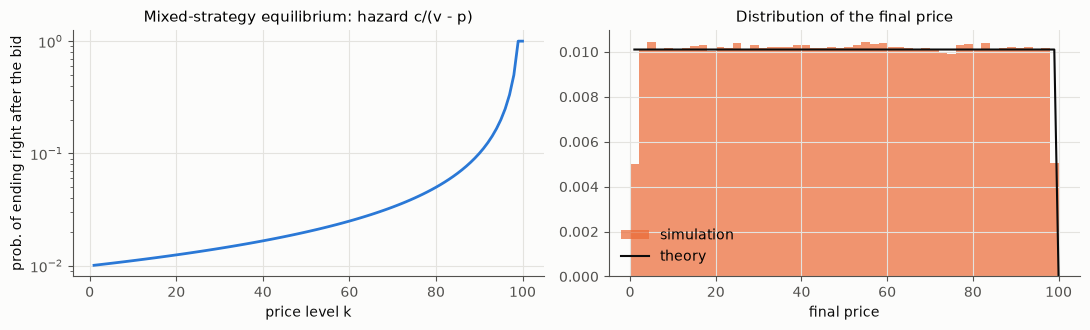

In [21]:
import penny
importlib.reload(penny)
G = penny.Game()
R_th, P_th = G.revenue(G.mixed_mu())
n_mix = 4 if FAST else 20
SIM = pmap(penny.simulate_mixed, [(s, 20000) for s in range(n_mix)])
rev = np.concatenate([r for r, p in SIM]); price = np.concatenate([p for r, p in SIM])
print(f'売り手の期待収入: 理論 {R_th:.2f}、均衡の確率で入札させた模擬 {rev.mean():.2f} ± {2 * rev.std() / np.sqrt(len(rev)):.2f}(品物の価値 v = {G.v})')
print(f'平均の落札価格  : 理論 {P_th:.2f}、模擬 {price.mean():.2f}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.arange(1, G.K + 1), G.mixed_mu()[1:G.K + 1], color=PAL[0])
ax[0].set(yscale='log', xlabel='price level k', ylabel='prob. of ending right after the bid', title='Mixed-strategy equilibrium: hazard c/(v - p)')
ax[1].hist(price, bins=np.arange(0, 101, 2), density=True, color=PAL[1], alpha=0.7, label='simulation')
surv = np.cumprod(np.r_[1, 1 - G.mixed_mu()[1:G.K]]); pk = surv * G.mixed_mu()[1:G.K + 1]
ax[1].plot(np.arange(1, G.K + 1), pk, color=INK, lw=1.5, label='theory')
ax[1].set(xlabel='final price', title='Distribution of the final price'); ax[1].legend()
plt.tight_layout(); plt.show()

理論と模擬は一致する。落札価格の分布は、0 から 100 までほぼ一様に広がる。参加者から見れば、**いくらで買えるかがまったく読めない、くじのようなもの**である。

### 3.3 均衡はたくさんある

ところが、ペニーオークションの均衡は、これだけではない。

**早く終わる均衡**を作ってみる。上の段から考える。価格が $v - c$ を超えると、入札しても損なので、誰も入札しない。その一つ下の段では、入札すれば確実に首位のまま終わるので、得が $v - p - c > 0$ で、全員が入札する。すると、その一つ下の段では、入札しても次の段で必ず誰かに抜かれるので、損になり、誰も入札しない。……このように、「全員が入札する段」と「誰も入札しない段」が交互に並ぶ。オークションは、最初に「誰も入札しない段」に来たところで、すぐに終わる。売り手の収入はわずかである。

これも、どの段でも、誰も得をする逸脱ができないので、均衡である。Augenblick(2016)は、すぐに終わる均衡を含め、均衡がたくさんあることを指摘している。Hinnosaar(2016)は、対称なマルコフ完全均衡をすべて特徴づけ、結果のばらつきが大きいことがこの形式にもともと備わった性質であること、そして高い収入は、合理的で危険中立な参加者とは合わないことを示した。

3.2 の均衡は、すべての段でちょうど「入札しても、しなくても同じ」になる、という、ぎりぎりの釣り合いの上に立っている。どちらの均衡が現れるのか。それを決めるのが、次の二つの節の主題である。

### 3.4 入札の手間の感じ方にばらつきがあると

現実の参加者は、入札の手間の感じ方が人によって違う。面倒だと感じる人もいれば、入札そのものを楽しむ人もいる。そこで、入札するたびに、各自が「感じる費用」を、一様分布 $[\,lo,\ hi\,]$ から引くことにする(実際に売り手に払う入札料は $c$ のまま)。

入札する人の割合は、$\beta_k = P(\text{感じる費用} < \mu_{k+1}(v - p_{k+1}))$ になり、段 $k$ で終わる確率は、首位でない $N - 1$ 人が誰も入札しない確率 $\mu_k = (1 - \beta_k)^{N-1}$ になる。一番上の段では誰も入札しないので、そこから**後ろ向きに**計算していけば、どの段の $\mu_k$ も決まる。均衡は**ただ一つ**に決まる(経済学では、ばらつきを入れて均衡を一つに絞ることを「純粋化」という。Harsanyi 1973)。

ばらつきの大きさを変えて、計算する。

感じる費用の範囲      売り手の期待収入   平均の落札価格
[  0.9,   1.1]               2.00              1.0
[  0.0,   2.0]               2.00              1.0
[ -1.0,   3.0]              10.64              5.3
[ -3.0,   5.0]              24.71             12.4
[ -5.0,   7.0]              65.50             32.8


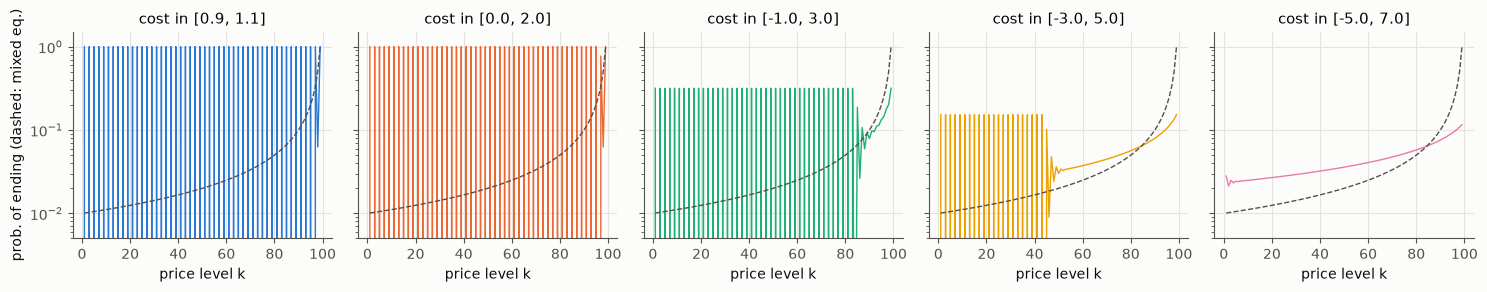

In [22]:
CASES = [(0.9, 1.1), (0.0, 2.0), (-1.0, 3.0), (-3.0, 5.0), (-5.0, 7.0)]
fig, ax = plt.subplots(1, len(CASES), figsize=(15, 3.0), sharey=True)
print('感じる費用の範囲      売り手の期待収入   平均の落札価格')
for j, (lo, hi) in enumerate(CASES):
    mu = G.hetero_mu(lo, hi); R, P = G.revenue(mu)
    print(f'[{lo:5.1f}, {hi:5.1f}]           {R:8.2f}           {P:6.1f}')
    ax[j].plot(np.arange(1, G.K), mu[1:G.K], color=PAL[j], lw=1)
    ax[j].plot(np.arange(1, G.K), G.mixed_mu()[1:G.K], color=INK2, ls='--', lw=1)
    ax[j].set(yscale='log', ylim=(5e-3, 1.5), title=f'cost in [{lo}, {hi}]', xlabel='price level k')
ax[0].set_ylabel('prob. of ending (dashed: mixed eq.)')
plt.tight_layout(); plt.show()

- ばらつきが小さい(0.9〜1.1、0〜2)と、均衡は 3.3 の**交互の均衡**になる。終了確率が 0 と 1 を行き来し、オークションはすぐに終わる。
- ばらつきが中くらい(−1〜3、−3〜5)だと、価格の低い所では交互の形が残るが、終了確率は 1 まで行かず、少し長く続く。価格の高い所では、なめらかな形になる。
- ばらつきが大きい(−5〜7)と、交互の形が消え、終了確率は、3.2 の均衡(点線)と同じように、なめらかな右上がりの形になる(点線より平らだが)。売り手の収入は 65 で、品物の価値に近づく。

なぜ、ばらつきが小さいと交互になるのか。段 $k+1$ の終了確率から段 $k$ の終了確率を決める写像

$$
\mu_k = g(\mu_{k+1}) = \big(1 - F(\mu_{k+1}(v - p_{k+1}))\big)^{N-1}
$$

($F$ は感じる費用の分布)は、$\mu_{k+1}$ が大きいほど $\mu_k$ が小さくなる、右下がりの写像である。右下がりの写像をくり返すと、その傾きの絶対値が 1 より小さければ一つの値(不動点)に落ち着き、1 より大きければ大きな値と小さな値を交互に行き来するようになる。3.2 の均衡は、この写像の不動点にあたる。ばらつきが小さいと、$F$ が急になり、傾きが大きくなって、不動点は**不安定**になる。

傾きが 1 より大きい所では、上の段のわずかなずれが、下の段に行くほど増幅される。試しに、ばらつきが −5〜7 の場合に、段 60 の終了確率を $10^{-9}$ だけずらしてみる。

In [23]:
lo, hi = -5.0, 7.0
base = G.hetero_mu(lo, hi)
def down(k0, mu0):
    mu = {k0: mu0}
    for k in range(k0 - 1, 0, -1):
        mu[k] = (1 - np.clip((mu[k + 1] * (G.v - (k + 1) * G.s) - lo) / (hi - lo), 0, 1)) ** (G.N - 1)
    return mu
ks, sl = G.slope(base, lo, hi)
print('写像の傾きの絶対値(段 5, 30, 60, 90):', [round(float(sl[k - 1]), 2) for k in (5, 30, 60, 90)])
for eps in (0.0, 1e-9, 1e-6):
    m = down(60, base[60] + eps)
    print(f'段 60 を {eps:.0e} ずらす → 段 50, 30, 10, 5 の終了確率', [round(float(m[k]), 4) for k in (50, 30, 10, 5)])

写像の傾きの絶対値(段 5, 30, 60, 90): [1.93, 1.63, 1.18, 0.43]
段 60 を 0e+00 ずらす → 段 50, 30, 10, 5 の終了確率 [0.0359, 0.0293, 0.0249, 0.0244]
段 60 を 1e-09 ずらす → 段 50, 30, 10, 5 の終了確率 [0.0359, 0.0293, 0.1158, 0.0]
段 60 を 1e-06 ずらす → 段 50, 30, 10, 5 の終了確率 [0.0359, 0.0693, 0.1158, 0.0]


段 60 での $10^{-9}$ のずれが、段 10 ではまったく別の値になっている。下の段(価格の低い所)では、傾きの絶対値が 1.5〜2 あり、ずれが一段ごとに 2 倍近くに増幅されるからである。均衡は数学的には一つに決まっていても、**上のほうのわずかな事情で、下のほうの振る舞いがまるで変わる**。Hinnosaar の言う「予測できない」ことの、一つの姿である。

### 3.5 学習するエージェントは、理論に一致するか

参加者が均衡を知っているのではなく、経験から学ぶとしたら、どうなるか。次のようなエージェントを作る。

- 各段で「入札が入った直後に終わった割合」を数え、終了確率を推定する(経済学で「仮想プレイ」という学び方)。
- 推定した得 $\hat\mu_{k+1}(v - p_{k+1})$ が、そのとき感じる費用を超えれば、入札する。
- 学習のあいだは、オークションをランダムな段から始めて、すべての段を経験させる(そうしないと、価格の高い段がほとんど経験されず、推定が育たない)。

30 万回の学習のあと、学んだ終了確率と、その信念でオークションを最初から回したときの収入を、3.4 の理論と比べる。

(17 秒)
感じる費用の範囲   収入: 学習 / 理論    境目 k*   理論とのずれ: k* より上 / 下    一段の釣り合いの残差: 上 / 下
[  0.9,   1.1]         2.00 /   2.00       98         —    / 0.3989                —    / 0.0387
[  0.0,   2.0]         4.20 /   2.00       97       0.0009 / 0.5123              0.0008 / 0.0693
[ -1.0,   3.0]        16.04 /  10.64       93       0.0093 / 0.1232              0.0034 / 0.0300
[ -3.0,   5.0]        27.60 /  24.71       82       0.0052 / 0.0812              0.0020 / 0.0087
[ -5.0,   7.0]        39.08 /  65.50       69       0.0030 / 0.0343              0.0014 / 0.0086


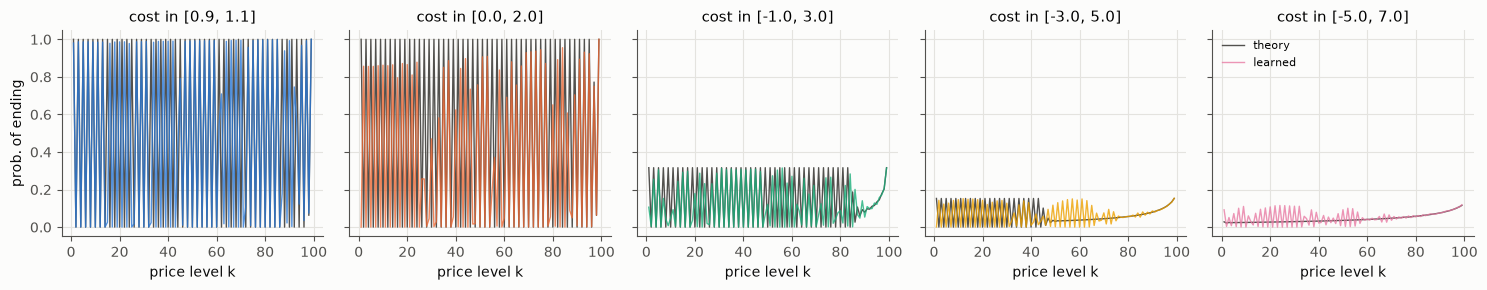

In [24]:
n_learn = 60000 if FAST else 300000
t0 = time.time()
LR = pmap(penny.learn, [(lo, hi, n_learn, 0) for lo, hi in CASES])
print(f'({time.time() - t0:.0f} 秒)')
print('感じる費用の範囲   収入: 学習 / 理論    境目 k*   理論とのずれ: k* より上 / 下    一段の釣り合いの残差: 上 / 下')
fig, ax = plt.subplots(1, len(CASES), figsize=(15, 3.0), sharey=True)
for j, ((lo, hi), (mh, rev)) in enumerate(zip(CASES, LR)):
    mu = G.hetero_mu(lo, hi); R, _ = G.revenue(mu)
    ks, sl = G.slope(mu, lo, hi)
    kstar = ks[sl >= 1].max() if (sl >= 1).any() else 0      # これより上の段では、写像はどこでも縮む
    up = ks > kstar
    err = np.abs(mh[ks] - mu[ks])
    res = np.abs(mh[ks] - (1 - np.clip((mh[ks + 1] * (G.v - (ks + 1) * G.s) - lo) / (hi - lo), 0, 1)) ** (G.N - 1))
    f = lambda x: f'{x.mean():.4f}' if len(x) else '  —   '
    print(f'[{lo:5.1f}, {hi:5.1f}]       {rev:6.2f} / {R:6.2f}      {kstar:3d}       {f(err[up])} / {f(err[~up])}'
          f'              {f(res[up])} / {f(res[~up])}')
    ax[j].plot(np.arange(1, G.K), mu[1:G.K], color=INK2, lw=1, label='theory')
    ax[j].plot(np.arange(1, G.K), mh[1:G.K], color=PAL[j], lw=1, alpha=0.8, label='learned')
    ax[j].set(ylim=(-0.05, 1.05), title=f'cost in [{lo}, {hi}]', xlabel='price level k')
ax[0].set_ylabel('prob. of ending'); ax[-1].legend(fontsize=8, loc='upper left', framealpha=0.9)
plt.tight_layout(); plt.show()

「境目 $k^*$」は、写像の傾きの絶対値が 1 以上になる一番上の段である。それより上の段では、写像はどこでも縮む(0.9〜1.1 では、上の段は残らない)。「一段の釣り合いの残差」は、学んだ終了確率が、すぐ上の段の(学んだ)終了確率から 3.4 の式で決まる値と、どれだけ違うかである。これが小さければ、学んだ信念は、その段だけ見れば均衡の条件をほぼ満たしている。

結果は、写像の傾きで説明できる。

- **$k^*$ より上の段**(写像が縮む所)では、ばらつきが大きいと、学んだ終了確率は理論の均衡によく一致する。−5〜7 では、ずれの平均は 0.003 しかない。
- **$k^*$ より下の段**(写像が増幅する所)では、ずれが大きくなる。ところが、一段の釣り合いの残差は、ずれの数分の一から十分の一ほどしかない。つまり、学んだ信念は、**どの段でもほぼ均衡の条件を満たしているのに、全体としては理論の均衡と違う**。上の段のわずかなずれが、下の段に向かって増幅され、別の形に育ったのである。−5〜7 では、理論はなめらかなのに、学んだ終了確率は価格の低い所で交互に揺れている。その結果、収入も理論(65)と違って 39 になる。
- ばらつきが小さい場合(0.9〜1.1、0〜2)は、学習でも交互の形が現れる。しかし、**交互の位相**(どの段が「終わる段」になるか)が理論と逆になることがある。0〜2 では、学習は位相が逆で、段 1 では終わらず段 2 で終わるので、収入は理論の 2 ではなく 4.2 になる。0.9〜1.1 では、途中の段で位相がずれる所はあるものの、価格の低い所では位相が合い、収入も理論と同じ 2 になる。位相が逆になると、多くの段でずれが 1 近くになるので、ずれの平均は大きく見える。

まとめると、「学習するエージェントは理論に一致するか」の答えは、**写像が縮む所では一致し、増幅する所では、ほぼ均衡ではあるが理論とは別の形に落ち着く**。その境目は、写像の傾きの絶対値が 1 になる所である。理論の均衡が上の段のわずかな事情に敏感な所では、学習も同じだけ敏感になる。これは学習の失敗というより、均衡そのものの性質である。

ノート 1 で見た「式が足りないとき、どの答えが選ばれるかは、歴史(学び方)で決まる」という話が、ここにも現れている。ペニーオークションの均衡選択は、参加者の感じ方のばらつきと、学び方で決まる。

### 3.6 入札を楽しむ人がいると

実際のペニーオークションのデータでは、売り手の利益率は 50% を超えていた(Augenblick 2016、約 16 万 6 千件のオークション)。つまり、売り手の収入は品物の価値を大きく上回っていた。危険中立の理論では、収入はせいぜい品物の価値どまりである。

Augenblick は、この差を「**サンクコストの錯誤**」(すでに払った入札料を取り返そうとして、やめられなくなる)で説明した。Platt, Price, Tappen(2013)は、参加者が少しだけ**賭けを好む**(危険愛好)とすれば、データがよく説明できることを示し、ペニーオークションを「穏やかな形の賭け事」と呼んだ。

3.4 の模型では、「感じる費用」がマイナスの人は、入札そのものを楽しむ人である。その割合を変えて、理論の収入を計算する。

In [25]:
print('感じる費用の範囲   入札を楽しむ人(費用 < 0)の割合   売り手の期待収入(品物の価値 = 100)')
for lo, hi in ((-1, 3), (-2, 2), (-3, 1), (-4, 0), (-6, 2), (-10, 4)):
    R, _ = G.revenue(G.hetero_mu(lo, hi))
    print(f'[{lo:4d}, {hi:3d}]              {max(0, -lo) / (hi - lo):5.2f}                       {R:7.1f}')

感じる費用の範囲   入札を楽しむ人(費用 < 0)の割合   売り手の期待収入(品物の価値 = 100)
[  -1,   3]               0.25                          10.6
[  -2,   2]               0.50                          63.8
[  -3,   1]               0.75                         179.8
[  -4,   0]               1.00                         200.0
[  -6,   2]               0.75                         175.3
[ -10,   4]               0.71                         158.9


入札を楽しむ人が半分を超えると、売り手の収入は品物の価値を超える。4 分の 3 なら、品物の価値のおよそ 1.8 倍になる。全員が楽しむなら、オークションは価格の上限まで続き、収入は上限(この設定では 200)になる。

参加者から見れば、ペニーオークションは、品物の値段の割引を期待する買い物ではなく、**入札するという行為そのものにお金を払う、娯楽か賭け事**に近い。売り手の利益は、その楽しみ(あるいは錯誤)の対価である。

### 3.7 無尽講との比較

作者の 2011 年の問いは、「ペニーオークションは**無尽講**ではないか」だった。

**無尽講**(頼母子講ともいう)は、仲間が定期的に掛け金を出し合い、集まったお金を、くじか入札で、毎回一人が受け取る仕組みである。全員が一度ずつ受け取ったら終わる。経済学では、世界中にある「**回転型貯蓄信用講**(ROSCA)」として研究されている(Besley, Coate, Loury 1993)。早く受け取った人は、いわば借金をして先に物を買い、あとの掛け金で返す。遅く受け取った人は、貯金をしてから受け取る。くじで順番を決める講と、入札で決める講(早く欲しい人が割引を申し出て、その割引分が他の仲間に配られる)がある。

二つを並べると、似ている所と違う所がはっきりする。

In [26]:
n, m = 10, 1.0          # 10 人、毎回 1 ずつ掛ける無尽講(10 回で一巡)
print(f'無尽講(くじ): 一人が払う額 {n * m:.0f}、一人が受け取る額 {n * m:.0f}、胴元の取り分 0、全員の収支の和 0')
G2 = penny.Game()
R_mix, _ = G2.revenue(G2.mixed_mu()); R_fun, _ = G2.revenue(G2.hetero_mu(-3, 1))
print(f'ペニーオークション(危険中立の均衡): 参加者全体が払う額の期待値 {R_mix:.0f}、受け取る品物の価値 {G2.v:.0f}、胴元(売り手)の取り分 {R_mix:.0f}')
print(f'ペニーオークション(入札を楽しむ人が 4 分の 3): 参加者全体が払う額の期待値 {R_fun:.0f}、品物の価値 {G2.v:.0f}、楽しみの対価 {R_fun - G2.v:.0f}')

無尽講(くじ): 一人が払う額 10、一人が受け取る額 10、胴元の取り分 0、全員の収支の和 0
ペニーオークション(危険中立の均衡): 参加者全体が払う額の期待値 100、受け取る品物の価値 100、胴元(売り手)の取り分 100
ペニーオークション(入札を楽しむ人が 4 分の 3): 参加者全体が払う額の期待値 180、品物の価値 100、楽しみの対価 80


| | 無尽講(ROSCA) | ペニーオークション |
|---|---|---|
| お金の集め方 | 仲間の掛け金 | 参加者の入札料 |
| 誰が受け取るか | 仲間の一人(くじ・入札) | 品物は落札者に、**入札料は売り手(胴元)に** |
| 全体の収支 | 仲間のあいだで回るだけで、和は 0 | 参加者全体で「払った額 − 品物の価値」だけ、胴元に移る |
| 何のための仕組みか | 貯蓄と信用(先に受け取る人は借り、後の人は貯める) | 割引の期待と、入札そのものの楽しみ |
| 危険中立の理論では | 誰も得も損もしない(順番の価値を除けば) | 胴元の収入 = 品物の価値。参加者全体としては得も損もしない |

**似ている所**: どちらも、多くの人から少しずつお金を集め、それを一人がまとめて受け取る。受け取る人が、くじか競りで決まる。参加者一人から見れば、少ない掛け金で大きなものが手に入るかもしれない、という「くじ」の面がある。

**違う所**: 無尽講では、お金は仲間のあいだで回るだけで、**胴元がいない**。ペニーオークションでは、入札料はすべて**売り手に入る**。危険中立の理論では、売り手の収入はちょうど品物の価値になり、参加者全体としては損も得もしない(公平なくじに近い)。しかし、データでは収入が品物の価値を大きく上回り、参加者全体としては損をしている。胴元の取り分のある賭けになっている。

作者の直感(ペニーオークションは無尽講に似ている)は、半分は正しい。お金の集め方と、受け取る人の決め方の形は、無尽講に近い。ただし、**胴元がいて、その取り分がある**点で、無尽講よりも、胴元つきの「くじ」に近い。

#### 作者が 2010 年に思い描いていたもの: 入札の講

ただ、作者が 2010 年 12 月に書いた直感(2.6)は、もう少し踏み込んでいた。「長く伸ばせば、競りで『利息』分を最後まで支払いができた者が、工作機械を導入できる」。これは、無尽講のうち、**入札で受け取る人を決める講**(入札講)の仕組みそのものである。

入札講では、毎回、まだ受け取っていない仲間が競る。早く受け取りたい人(早くお金を使えば大きく稼げる人)ほど、大きな割引(利息)を申し出る。一番大きな割引を申し出た人が、集まったお金から割引を引いた額を受け取り、割引はほかの仲間に配られる。早く受け取った人は利息を払って借り、遅く受け取る人は利息を受け取って貯める。くじの講と入札の講のどちらがよいかは、経済学でも調べられている(Besley, Coate and Loury 1993; Kovsted and Lyk-Jensen 1999)。

小さな模型で比べる。10 人が毎回 1 ずつ掛け、集まった 10 を一人が受け取る。受け取った 10 で「機械」を買うと、その後、毎回、利回り $y_i$(人ごとに違う。0.02〜0.2)× 10 を生む。早く受け取るほど、長く機械を使える。決め方を三つ比べる。

- **くじ**: 順番をくじで決める。
- **入札(利息は仲間へ)**: 毎回、利回りの一番高い人が受け取り、二番目に高い人の「一回早く受け取る値打ち」を割引(利息)として払う。利息は、ほかの 9 人で分ける。
- **入札(利息は胴元へ)**: 同じだが、利息は胴元に入る(胴元のいる営業無尽や、入札料が売り手に入るペニーオークションの形)。

In [27]:
%%writefile -a penny.py
def rosca(a):
    """(seed, 人数 n, 決め方) → 無尽講(ROSCA)の一巡の結果。
    n 人が毎回 1 ずつ掛け、集まった n を一人が受け取る。n 回で全員が一度ずつ受け取る。
    受け取った n で「機械」を買うと、その後、毎回 y_i × n を生む(y_i は人ごとの事業の利回り。一様分布 0.02〜0.2)。
    t 回目に受け取った人は、残りの n − t 回、機械を使える。
    決め方: 'lottery'(くじで順番を決める)、'bid'(毎回、まだ受け取っていない人が競り、利回りの一番高い人が受け取る。
    受け取る人は、二番目に高い人の「一回早く受け取る値打ち」y × n を割引として払い、それをほかの n − 1 人で分ける)、
    'bid_house'('bid' と同じだが、割引は胴元に入る)。
    返り値: (生産の合計, 胴元の取り分, 利回りの高い半分の人の正味の得の平均, 低い半分の平均)。
    正味の得 = 機械の生んだもの + 受け取った額 + 分けてもらった割引 − 掛け金の合計。"""
    seed, n, mode = a
    rng = np.random.default_rng(seed)
    y = rng.uniform(0.02, 0.2, n)
    order = rng.permutation(n) if mode == 'lottery' else np.argsort(-y)
    gain = np.zeros(n); house = 0.0; out = 0.0
    for t, i in enumerate(order, start=1):
        rest = [j for j in order[t:]]
        D = 0.0
        if mode != 'lottery' and rest:
            D = min(n, max(y[j] for j in rest) * n)       # 二番目に高い人の、一回早く受け取る値打ち
        prod = y[i] * n * (n - t)
        out += prod
        gain[i] += prod + (n - D) - n                    # 機械の生産 + 受け取り − 掛け金(n 回 × 1)
        if mode == 'bid':
            others = [j for j in range(n) if j != i]
            gain[others] += D / (n - 1)
        elif mode == 'bid_house':
            house += D
    hi = y >= np.median(y)
    return out, house, gain[hi].mean(), gain[~hi].mean()

Appending to penny.py


In [28]:
importlib.reload(penny)
n_ro = 500 if FAST else 2000
print('決め方                  生産の合計   胴元の取り分   利回りの高い半分の得   低い半分の得')
for mode, lab in (('lottery', 'くじ'), ('bid', '入札(利息は仲間へ)'), ('bid_house', '入札(利息は胴元へ)')):
    R = np.array([penny.rosca((s, 10, mode)) for s in range(n_ro)]).mean(0)
    print(f'{lab:18s}   {R[0]:8.1f}      {R[1]:8.1f}          {R[2]:8.2f}            {R[3]:8.2f}')

決め方                  生産の合計   胴元の取り分   利回りの高い半分の得   低い半分の得


くじ                       49.5           0.0              6.78                3.11


入札(利息は仲間へ)               63.0           0.0             10.41                2.19


入札(利息は胴元へ)               63.0           9.2              9.55                1.22


- **入札の講は、くじの講より、生産が 3 割近く大きい。** 一番うまくお金を使える人から順に受け取るからである。作者の言う「利息を払える者が工作機械を導入できる」は、お金を、それを一番生かせる人に先に回す仕組みとして、正しく働く。
- 利息が仲間に回るので、遅く受け取る人(利回りの低い人)も、利息の分は報われる。ただし、くじならたまたま早く受け取れたかもしれない分を失うので、利回りの低い人の得は、くじの講より少し小さい。全体が大きくなった分の多くは、利回りの高い人に行く。
- 利息が胴元に入ると、仲間全体の得は、ちょうど胴元の取り分だけ減る。とくに利回りの低い人は、くじの講より損をする。

ペニーオークションは、この「利息が胴元に入る入札の講」の、さらに極端な形である。競り落とす物が生産につながらない(機械ではなく、消費する品物である)ので、生産の増えがない。そして、利息(入札料)はすべて胴元に入る。作者が 2010 年に「今は競り落とす物が特に生産活動につながるものではないので、どう国民経済と結びつくのか展望が見えず、胴元だけが得をする形になっている」と書いたのは、模型の言葉でも、そのとおりである。

### 3.8 仮想通貨の採掘: 第三の形

作者は 2025 年 1 月に、「ビットコインのような仮想通貨は、現代版の無尽や頼母子講になるのではないか。くじで当たった者に資金がいくのは、まさに暗号を(部分的に)当てた者に権利がいく仮想通貨の仕組みだ」と書いた(cocolog:95231675)。

実際、ビットコインの採掘(プルーフ・オブ・ワーク)は、ペニーオークションとよく似た形をしている。採掘する人は、計算のための電気代を払い続け(入札料)、暗号を最初に当てた人が報酬をまとめて受け取る(落札)。採掘への参入が自由なら、採掘の費用の合計は、報酬の値打ちにほぼ等しくなるまで増える(Budish 2018)。3.2 の「胴元の収入 = 品物の価値」と同じ、**レントの完全な散逸**である。

違うのは、集めたお金(費用)の行き先である。三つを並べる。

| | 無尽講(入札の講) | ペニーオークション | 仮想通貨の採掘 |
|---|---|---|---|
| 集める物 | 掛け金と利息 | 入札料 | 電気代(計算の費用) |
| 受け取る物 | 集まったお金(機械を買える) | 品物 | 新しく作られる通貨と手数料 |
| 利息・入札料の行き先 | **仲間に回る** | **胴元に入る** | **誰にも入らず、燃える** |
| 社会全体で見ると | お金が、それを生かせる人に先に回る | 胴元への移転 | 資源が使われて消える(その代わり、誰も記録を改ざんできない) |

採掘で燃える費用は、無駄だけではない。その費用が、記録を書き換えようとする者にとっての壁になり、胴元がいなくても記録の正しさが保たれる。Budish(2018)は、その安全のための費用が、守る値打ちの大きさに比例して増え続けることを示し、ここに仮想通貨の経済的な限界があると論じた。

### 3.9 無尽は相互銀行になった: 格上げとしての歴史

作者の直感には、もう一つの面がある。「**歴史は繰り返す**」である。

日本では、無尽にも、胴元にあたる業者が運営する「営業無尽」が広がり、1915 年の無尽業法で、無尽会社として規制されるようになった。戦後、無尽は賭博的だと見る向きもあったが、無尽会社は 1951 年の相互銀行法で相互銀行になった。相互銀行は 1989 年ごろから普通銀行に転換し、今の第二地方銀行の多くの前身になっている。

これは、このノートの後半の言葉で言えば、**格上げ**である。仲間うちの、法の外の(バーチャルな)金融だった無尽が、法という引き金によって、制度の側の金融機関になった。くじと競りで集める仕組みは、時代ごとに、無尽、ネットオークション、仮想通貨と、形を変えて繰り返し現れる。そのたびに、利息がどこに行くか(仲間か、胴元か、燃えるか)と、制度に格上げされるかどうかで、運命が分かれる。仮想通貨が、無尽が相互銀行になったように次の時代の金融の一部になるのか、ペニーオークションのように消えていくのかは、まだわからない。第 7 章で、仮想通貨を、格上げの事例の一つとしてもう一度取り上げる。

### 3.10 Lean: 混合均衡の条件

3.2 節の混合均衡 μ = c / (v − p) は、入札するかしないかを無差別にする確率である。ほかの人が続けない確率が μ なら、費用 c を払って入札する得の期待値 μ(v − p) − c は 0 になる。

In [29]:
%%writefile -a embedded_economy.lean
/-! ## 第 3 章 ペニーオークションの混合均衡

今の値段 p で、入札の費用 c を払って入札すると、ほかの誰も続けなければ v − p を得る。
ほかの人が続けない確率 μ が c / (v − p) なら、入札の得の期待値は 0 で、入札するかしないかが無差別になる。 -/
theorem penny_indifference {v p c : ℝ} (h : p < v) : c / (v - p) * (v - p) - c = 0 := by
  have : v - p ≠ 0 := by linarith
  field_simp; ring

/-- 無差別にする確率が 1 以下であるのは、費用が残りの値打ち以下のとき。 -/
theorem penny_prob_le_one {v p c : ℝ} (h : p < v) : c / (v - p) ≤ 1 ↔ c ≤ v - p := by
  rw [div_le_one (by linarith)]

Appending to embedded_economy.lean


## 第 4 章 最低限の経済原理

ここから、このノートの後半に入る。後半の問いは、「経済の中で、まったく違う経済が育ち、ある日それが全体に格上げされる」ことを、どうモデルにするか、である。

まったく違う経済を比べたり、つないだりするには、**どの経済にも共通する骨組み**が要る。この章では、それを探す。材料は、ここまでに解剖した三つのモデルである。

- 2011 年の外作用モデル(このノートの第 1・2 章)
- 2018〜2020 年の micro_economy(ノート 1)
- 2026 年の信用循環モデル(「信用創造のミクロ的基礎」と「信用の世界経済は一つか」)

### 4.1 三つのモデルを並べる

三つのモデルは、見かけはまったく違う。2011 年のモデルは、競りとくじの積み重ねである。micro_economy は、価格を最適化で決める。信用循環モデルは、部門ごとの差分方程式である。しかし、どれも次の四つの部分に分けられる。

| 原理 | 中身 | 2011 年のモデル | micro_economy | 信用循環モデル |
|---|---|---|---|---|
| **保存** | すべての受け払いに、払う側と受け取る側がある | 現金をマイナスの負債として書くので、自動的に保存される。最初の負債の貸し手はモデルの外 | 「社会的負債」が相手方の勘定(三つの誤りを直せば閉じる) | 部門の収支の和が 0 になる恒等式 |
| **評価** | 価値の物差しと、価格 | desire・greed から決まる価格。文化資本は買値のまま | 最適化で決める四つの価格 | 名目の量。地域が別の通貨なら為替 |
| **実現可能性** | 予算、技術、資源の制約 | 必需品の必要量、持分権。借りる額に上限はない | 投入係数、労働、参入 | 生産の式、準備率 |
| **行動** | 制約の中から、どれを選ぶか | 内作用(戦術)と、乱数で決まる希望価格 | スコアの最適化(暗黙の戦術) | 行動の式(消費の割合など) |

四つは、役割がはっきり違う。

- **保存**は、どのモデルでも、どの時点でも、例外なく成り立たなければならない。破れていれば、それはモデルの誤りである(ノート 1 の三つの誤りは、どれも保存の破れとして見つかった)。物理の保存則に近い。
- **評価**は、物差しの選び方による。同じ帳簿を、違う物差しで測れば、違う数字になる。
- **実現可能性**は、技術や制度で変わる。新しい技術は、できることの範囲を広げる。
- **行動**は、残りの自由を埋める。ノート 1 で見たように、式が足りないとき、どの答えが選ばれるかを決めるのは、行動(歴史、慣習、戦術)である。

以下、一つずつ、手を動かして確かめる。最後に、「埋め込みの遷移」で入れ替わるのが四つのうちのどれかを考える。

### 4.2 保存: 複式簿記と、差の群

**複式簿記**は、すべての取引を、二つ以上の勘定に、借方(左)と貸方(右)の同じ額で書く方法である。たとえば、現金 100 で品物を買えば、「品物 100(借方)/ 現金 100(貸方)」と書く。どの取引も、借方の合計と貸方の合計が等しい。だから、帳簿全体でも、借方の合計と貸方の合計は、いつも等しい。

数学者で経済学者の Ellerman(1985)は、この仕組みを代数として書いた。勘定を、借方と貸方の二つの数の組 $[\,d\ //\ c\,]$(T 勘定)で表し、

- 足し算は、借方どうし・貸方どうしを足す: $[\,d\ //\ c\,] + [\,d'\ //\ c'\,] = [\,d + d'\ //\ c + c'\,]$。
- $d + c' = d' + c$ のとき、$[\,d\ //\ c\,]$ と $[\,d'\ //\ c'\,]$ は同じものとみなす(大事なのは、借方と貸方の**差**だけ)。

とする。すると、T 勘定の全体は**群**になる(Ellerman は「パチョーリ群」と呼んだ。パチョーリは、1494 年に複式簿記を初めて本に書いた修道士である)。$[\,x\ //\ x\,]$ が零で、$[\,d\ //\ c\,]$ の逆元は、借方と貸方を入れ替えた $[\,c\ //\ d\,]$ である。**取引とは、和が零になる T 勘定の組**であり、帳簿が釣り合っていることは、群の中で「すべての取引の和が零」と言える。

In [30]:
%%writefile ledger.py
"""ledger.py -- 複式簿記の帳簿。Ellerman のパチョーリ群、仕訳と集計、2011 年のモデルに帳簿を付けた版。"""
import math
from collections import defaultdict


class T:
    """T 勘定 [借方 // 貸方]。どちらも 0 以上の数。Ellerman(1985)のパチョーリ群の元。
    [d // c] と [d' // c'] は、d + c' = d' + c のとき同じものとみなす(差だけが意味を持つ)。"""
    def __init__(self, d=0.0, c=0.0):
        assert d >= 0 and c >= 0
        self.d, self.c = d, c

    def __add__(self, o):
        return T(self.d + o.d, self.c + o.c)

    def __neg__(self):                  # 借方と貸方を入れ替える(仕訳の取り消し)
        return T(self.c, self.d)

    def __eq__(self, o):
        return math.isclose(self.d + o.c, o.d + self.c, rel_tol=1e-12, abs_tol=1e-9)

    def is_zero(self):                  # [x // x] は、どれも零元
        return self == T()

    def __repr__(self):
        return f'[{self.d:g} // {self.c:g}]'

Overwriting ledger.py


In [31]:
import ledger
importlib.reload(ledger)
T = ledger.T
goods, cash = T(100, 0), T(0, 100)       # 品物 100 を借方に、現金 100 を貸方に
print('品物を買う取引:', goods, '+', cash, '=', goods + cash, '→ 零か:', (goods + cash).is_zero())
print('[5 // 3] と [7 // 5] は同じか:', T(5, 3) == T(7, 5), ' / [5 // 3] の逆元:', -T(5, 3), '、足すと', T(5, 3) + (-T(5, 3)))

品物を買う取引: [100 // 0] + [0 // 100] = [100 // 100] → 零か: True
[5 // 3] と [7 // 5] は同じか: True  / [5 // 3] の逆元: [3 // 5] 、足すと [8 // 8]


この構成は、数学では「**差の群**」(グロタンディーク群)と呼ばれるものの、一番簡単な例である。0 以上の数(足すことしかできない)から、「差」を考えることで、引き算のできる群を作る。自然数から整数を作るのと同じ作り方である。

ここで大事なのは、この作り方が、**いちばん無駄のない作り方として、ただ一つに決まっている**ことである(数学の言葉で「普遍性」という)。足し算だけの世界を、引き算のできる世界に広げる方法は、本質的にこれしかない。簿記がどの国でも、どの時代でも同じ形をしているのは、このためだと考えることができる。この「普遍性」の考え方は、第 5 章で、経済どうしの関係を考えるときに、もう一度使う。

2011 年のモデルは、現金を「マイナスの負債」として、一つの符号つきの数で書いた。これは、T 勘定を、借方と貸方の差という一つの数で表すことにあたる。パチョーリ群は、符号つきの数(実数)と同じものなので、この書き方は正しい。符号つきの数で書く限り、受け払いのたびに、片方に足して片方から引けば、保存は自動的に守られる。

### 4.3 2011 年のモデルに帳簿を付ける

では、2011 年のモデルに、本当に帳簿を付けてみる。Python 版(`sm0.py`)の市場に、すべての受け払いを仕訳として記録する機能を足す。勘定は、プレイヤーごとに、

- 現金(マイナスの liability)、文化資本(asset)、正味資産、
- 売上、必需品の消費(期末に正味資産へ振り替える)、

とする。2.1 で見たとおり、最初の負債(一人 10)には貸し手がいないので、モデルの外に「外の貸し手」(EXT)を一人置き、最初の負債はそこから借りたことにする。仕訳を記録するとき、借方と貸方が一致しない仕訳は受け付けない(エラーで止まる)ようにする。

計算そのものは元の Python 版と同じで、仕訳を書く行を足しただけである。まず、元の Python 版と全期で同じ結果になることと、帳簿から読んだ liability と asset が、プレイヤーの値と一致することを確かめる。

In [32]:
%%writefile -a ledger.py
class Ledger:
    """仕訳帳と元帳。仕訳は {(主体, 勘定): 金額} で、借方を正、貸方を負で書く。和が 0 でない仕訳は受け付けない。"""
    def __init__(self, tol=1e-9, keep=False):
        self.bal = defaultdict(float)
        self.tol = tol
        self.journal = [] if keep else None      # keep=True なら、仕訳をすべて残しておく
        self.n_entries, self.max_gap = 0, 0.0

    def post(self, entry):
        gap = 0.0
        for v in entry.values():
            gap += v
        scale = max(1.0, max(abs(v) for v in entry.values()))
        self.max_gap = max(self.max_gap, abs(gap) / scale)
        if abs(gap) > self.tol * scale:
            raise ValueError(f'貸借が一致しない仕訳: {entry}')
        for k, v in entry.items():
            self.bal[k] += v
        self.n_entries += 1
        if self.journal is not None:
            self.journal.append(entry)

    def balance(self, agent, account):
        return self.bal.get((agent, account), 0.0)


def aggregate(bal, group):
    """集計: 主体を group(主体) にまとめた残高。和をとるだけなので、貸借の一致はそのまま保たれる。"""
    out = defaultdict(float)
    for (a, acc), v in bal.items():
        out[(group(a), acc)] += v
    return dict(out)

Appending to ledger.py


In [33]:
%%writefile -a ledger.py
import sm0


class BookedMarket(sm0.Market):
    """2011 年のモデル(移植版)に帳簿を付けた版。計算は sm0.Market と同じで、受け払いをすべて仕訳として記録する。
    勘定(主体ごと): cash(現金。マイナスの liability)、culture(文化資本 = asset)、equity(正味資産)、
    sales(売上)、ess_cost(必需品の消費)、depr(減耗)。外の貸し手 EXT は loan(貸付)を持つ。
    嗜好品は、主体ごと・財ごとに、持っている数と買値も覚えておく(時価で評価し直すため)。"""
    def __init__(self, keep_journal=False, **kw):
        super().__init__(**kw)
        self.L = Ledger(keep=keep_journal)
        self.units = defaultdict(lambda: defaultdict(float))
        self.last_price = {}
        self.self_volume, self.self_count = 0.0, 0      # 自分から買った嗜好品の額と件数(累計)
        self.asset0 = {pid: p.asset for pid, p in self.player.items()}   # 初めの文化資本(財の数はわからないので買値のまま)
        for pid, p in self.player.items():
            # 開始の仕訳: 最初の liability は、外の貸し手 EXT への借り(元のモデルには EXT がいない)
            self.L.post({(pid, 'equity'): p.liability, (pid, 'cash'): -p.liability,
                         ('EXT', 'loan'): p.liability, ('EXT', 'equity'): -p.liability})
            self.L.post({(pid, 'culture'): p.asset, (pid, 'equity'): -p.asset})

    def consume_essential(self):
        for cid in sorted(self.current_essential):
            if self.ess_rule == 'orig':
                buyer_price, seller_price = self.match_greed(cid, self.current_essential[cid])
            else:
                buyer_price, seller_price = self.match_greed_alt(cid, self.current_essential[cid])
            entry = defaultdict(float)
            for pid in sorted(seller_price):
                self.player[pid].liability -= seller_price[pid]
                entry[(pid, 'cash')] += seller_price[pid]; entry[(pid, 'sales')] -= seller_price[pid]
            for pid in sorted(self.player):
                self.player[pid].liability += buyer_price
                entry[(pid, 'ess_cost')] += buyer_price; entry[(pid, 'cash')] -= buyer_price
            self.L.post(dict(entry))
            self.cur_gross = buyer_price * len(self.player)

    def consume_luxury(self):
        self.lux_volume, self.lux_count = 0.0, 0
        for cid in sorted(self.current_luxury):
            pricemap = self.current_luxury[cid]
            matches = self.match_desire(cid, pricemap) if self.lux_rule == 'orig' else self.match_call(cid, pricemap)
            for price, d, p in matches:
                self.player[d].asset += price
                self.player[d].liability += price
                self.player[p].liability -= price
                self.lux_volume += price; self.lux_count += 1
                entry = defaultdict(float)       # 買い手と売り手が同じ人のこともある(自分の作ったものを自分で買う)
                entry[(d, 'culture')] += price; entry[(d, 'cash')] -= price
                entry[(p, 'cash')] += price; entry[(p, 'sales')] -= price
                self.L.post(dict(entry))
                if d == p:
                    self.self_volume += price; self.self_count += 1
                self.units[d][cid] += 1.0
                self.last_price[cid] = price
        if self.delta:
            for pid, p in self.player.items():
                dep = p.asset * self.delta
                p.asset *= (1 - self.delta)
                self.L.post({(pid, 'depr'): dep, (pid, 'culture'): -dep})
                for cid in self.units[pid]:
                    self.units[pid][cid] *= (1 - self.delta)

    def close(self):
        """期末の締め: 売上・消費・減耗を正味資産に振り替える(これも貸借の一致した仕訳)。"""
        for pid in sorted(self.player):
            e = {}
            for acc in ('sales', 'ess_cost', 'depr'):
                v = self.L.balance(pid, acc)
                if v:
                    e[(pid, acc)] = -v
                    e[(pid, 'equity')] = e.get((pid, 'equity'), 0.0) + v
            if e:
                self.L.post(e)

    def step(self):
        super().step()
        self.close()

    def net_worth(self, value=None):
        """主体ごとの正味資産 = 現金 + 文化資本の評価額。value(pid) を渡すと、文化資本をその評価で測る(既定は買値)。"""
        return {pid: self.L.balance(pid, 'cash') + (value(pid) if value else self.L.balance(pid, 'culture'))
                for pid in sorted(self.player)}


def booked_check(a):
    """(seed, 期数, 人数) → 帳簿を付けた版が sm0.Market と全期でぴったり同じか、仕訳の数と貸借のずれの最大、
    帳簿から読んだ liability・asset が Player の値と一致するか。"""
    seed, T_, P = a
    m, ref = BookedMarket(seed=seed, players=P), sm0.Market(seed=seed, players=P)
    same, read_ok = True, True
    for t in range(T_):
        m.step(); ref.step()
        same &= m.snapshot() == ref.snapshot()
        for pid, p in m.player.items():
            read_ok &= math.isclose(-m.L.balance(pid, 'cash'), p.liability, rel_tol=1e-9, abs_tol=1e-9)
            read_ok &= math.isclose(m.L.balance(pid, 'culture'), p.asset, rel_tol=1e-9, abs_tol=1e-9)
    return same, read_ok, m.L.n_entries, m.L.max_gap

Appending to ledger.py


In [34]:
importlib.reload(ledger)
n_b = 8 if FAST else 20
BC = pmap(ledger.booked_check, [(s, 200, 5) for s in range(n_b)])
print(f'元の Python 版と全期で同じ結果: {sum(r[0] for r in BC)}/{n_b}、帳簿の値がプレイヤーの値と一致: {sum(r[1] for r in BC)}/{n_b}')
print(f'仕訳の数(一回あたり): {np.mean([r[2] for r in BC]):.0f}、仕訳の貸借のずれの最大(金額に対する比): {max(r[3] for r in BC):.1e}')
m = ledger.BookedMarket(seed=1)
for t in range(100):
    m.step()
name = {'cash': '現金', 'culture': '文化資本', 'equity': '正味資産', 'loan': '貸付', 'sales': '売上', 'ess_cost': '必需品の消費'}
print('\n100 期のあとの残高(借方が正、貸方が負)。プレイヤー全員をまとめた勘定と、外の貸し手:')
agg = ledger.aggregate(m.L.bal, lambda a: '外の貸し手' if a == 'EXT' else 'プレイヤー全員')
for (g, acc), v in sorted(agg.items()):
    if abs(v) > 1e-9:
        print(f'  {g:8s} {name[acc]:6s} {v:10.3f}')
print(f'  すべての残高の和: {sum(agg.values()):.1e}')

元の Python 版と全期で同じ結果: 20/20、帳簿の値がプレイヤーの値と一致: 20/20
仕訳の数(一回あたり): 1937、仕訳の貸借のずれの最大(金額に対する比): 8.5e-16

100 期のあとの残高(借方が正、貸方が負)。プレイヤー全員をまとめた勘定と、外の貸し手:
  プレイヤー全員  現金        -50.000
  プレイヤー全員  文化資本     1018.608
  プレイヤー全員  正味資産     -968.608
  外の貸し手    正味資産      -50.000
  外の貸し手    貸付         50.000
  すべての残高の和: -2.1e-13


帳簿を付けた版は、元の計算と全期で一致し、数千の仕訳のどれも、借方と貸方が(計算機の丸めの誤差 $10^{-16}$ の範囲で)一致している。2011 年のモデルの受け払いは、**一つ残らず複式簿記として正しい**。

残高を見ると、次のことがわかる。

- プレイヤー全員の現金の合計は −50 で、外の貸し手の貸付 50 と打ち消し合う。**金融の請求権は、経済全体で足すと 0 になる**。
- プレイヤー全員の正味資産(貸方の 968.6)と、外の貸し手の正味資産(貸方の 50)を足すと、文化資本の合計(1018.6)に等しい。

これは、次の一般的な事実の例である。

> **経済全体の正味資産は、実物資産の価値の合計に等しい。** 金融の請求権(貸し借り、お金)は、持っている側と負っている側の両方の帳簿に、反対の符号で一度ずつ現れるので、全体で足すと消える。

この事実は、物差し(価格)を何にしても成り立つ。請求権の貸し手と借り手が、同じ物差しで測っている限り、二つは同じだけ増え減りして、打ち消し合うからである。消えずに残るのは、相手方のいない実物資産だけである。

#### 2.1 の訂正: 文化資本の相手方

2.1 では、文化資本(asset)の増加には相手方がない、と書いた。帳簿を付けてみると、正確には、**相手方は売り手の売上**である。買い手は現金を文化資本に替え(借方: 文化資本、貸方: 現金)、売り手は嗜好品を作って売った(借方: 現金、貸方: 売上)。売上は期末に売り手の正味資産になる。つまり、嗜好品の取引は、経済全体で見れば「**嗜好品を生産し、それを減らさずに資産として積み上げる**」ことである。資産が際限なく増える(2.3)のは、作ったものが、使っても減らず、すべて資産として残り続けるからである。必需品のほうは、期末に「消費」として正味資産から引かれるので、積み上がらない。

#### 自分で作ったものを、自分で買う

帳簿を付けて、もう一つ見つかったことがある。嗜好品の取引で、**買い手と売り手が同じプレイヤー**になることがある。自分が作って売りに出した嗜好品を、自分の desire で競り落とすのである。このとき、現金は自分から自分に払われるので動かず、文化資本だけが、その値段だけ増える。

In [35]:
%%writefile -a ledger.py
def trade_stats(a):
    """(seed, 期数, 人数) → 嗜好品の取引の (自分から買った額, 全体の額, 自分から買った件数, 全体の件数)。"""
    seed, T_, P = a
    m = BookedMarket(seed=seed, players=P)
    vol, cnt = 0.0, 0
    for t in range(T_):
        m.step(); vol += m.lux_volume; cnt += m.lux_count
    return m.self_volume, vol, m.self_count, cnt


def valuation_path(a):
    """(seed, 期数, 人数) → 期ごとの (文化資本の買値の合計, 時価の合計, 嗜好品の購入額の累計) と、
    最後の期の主体ごとの正味資産(買値で測る、時価で測る、財 C002 だけ 3 倍に値上がりした時価で測る)。
    時価 = 初めの文化資本 + 持っている数 × その財の最後の取引価格。"""
    seed, T_, P = a
    m = BookedMarket(seed=seed, players=P)
    path, cum = [], 0.0
    mv = lambda pid, boost=1.0: m.asset0[pid] + sum(u * m.last_price[c] * (boost if c == 'C002' else 1.0) for c, u in m.units[pid].items())
    for t in range(T_):
        m.step(); cum += m.lux_volume
        path.append((sum(p.asset for p in m.player.values()), sum(mv(pid) for pid in m.player), cum))
    final = (m.net_worth(), m.net_worth(mv), m.net_worth(lambda pid: mv(pid, 3.0)))
    return path, final

Appending to ledger.py


In [36]:
importlib.reload(ledger)
TSt = pmap(ledger.trade_stats, [(s, 200, P) for P in (5, 10) for s in range(n_b)])
for j, P in enumerate((5, 10)):
    R = TSt[j * n_b:(j + 1) * n_b]
    print(f'{P:2d} 人: 嗜好品の取引のうち、自分で作ったものを自分で買った割合  額で {sum(r[0] for r in R) / sum(r[1] for r in R):.1%}、件数で {sum(r[2] for r in R) / sum(r[3] for r in R):.1%}')

 5 人: 嗜好品の取引のうち、自分で作ったものを自分で買った割合  額で 20.1%、件数で 19.7%
10 人: 嗜好品の取引のうち、自分で作ったものを自分で買った割合  額で 10.8%、件数で 10.7%


5 人では、嗜好品の取引の **2 割**が、自分で作ったものを自分で買う取引である(10 人では 1 割)。複式簿記としては正しい(借方: 文化資本、貸方: 売上)。国民経済計算(SNA)でも、自分で作って自分で使う資本(自己勘定の総固定資本形成。たとえば、会社が自分で作るソフトウェア)は、生産として数える。

作者に尋ねると、嗜好品については、自分で作ったものを自分で買うこともある、という認識で作っていたように思う、とのことだった。そうやって「価格」が決まることがある。前の期の価格が大事なら、自分で買ってでも値を付けることもあるだろう、という感覚だったという。意図した動きと考えてよい。

現実にも、取引の少ない市場では、自分で売って自分で買い、値を作ることがある(美術品や NFT の市場でよく問題になる)。株式の市場では、これは「仮装売買」と呼ばれ、相場を操る手口として、日本では金融商品取引法(第 159 条)で禁じられている。値を付けることそのものに、それだけの力があるからである。ただし、2011 年のモデルでは、前の期の取引価格は、次の期の値付けに直接は使われていない。自分で買った分は、文化資本を増やし、それを通じて、次の期の希望価格と desire の振れ幅を大きくする(2.3)。値の効き方は、間接的である。

ただし、そのときの値段の付け方が問題になる。国民経済計算では、同じような品物の市場の値段で評価する。2011 年のモデルでは、競りの値段がそのまま付く。競りの相手が少なければ、自分の desire がそのまま値段になる。**自分で付けた値段で、自分の資産が増える**のである。これは、次の 4.4 の「評価」の問題そのものである。

### 4.4 評価: 同じ帳簿、違う物差し

保存は、物差しによらずに成り立つ。では、物差しを変えると、何が変わるのか。

2011 年のモデルでは、文化資本を**買値**で帳簿に載せている。買ったあとで、同じ嗜好品の値段が上がっても下がっても、帳簿の値は変わらない。これに対して、**時価**(今、同じものを売り買いすると付く値段)で測ることもできる。時価で測るには、誰がどの嗜好品をいくつ持っているかが要る。帳簿を付けた版では、それも覚えておいたので、

- 時価 = 持っている数 × その嗜好品の最後の取引価格

で測れる。さらに、嗜好品の一つ(C002)だけが、何かの理由で 3 倍に値上がりした場合の時価も考える。三つの物差しで、同じ帳簿の正味資産を測る。

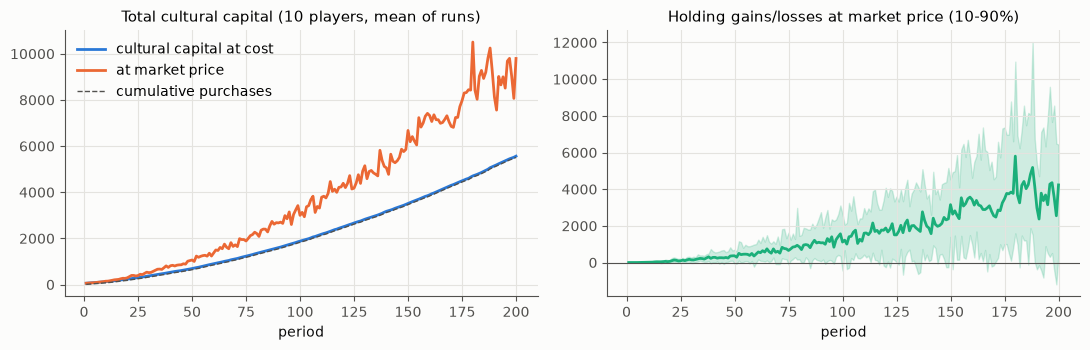

正味資産の順位の相関(スピアマン): 買値 と 時価 0.89、時価 と C002 が 3 倍の時価 0.85
一番の金持ちが同じ人である割合: 買値 と 時価 85%、買値 と C002 が 3 倍の時価 65%
物差しの単位だけを 1000 倍に変えたとき(デノミの逆): 順位の相関 1.00、各人の取り分は変わらない


In [37]:
from scipy.stats import spearmanr
VP = pmap(ledger.valuation_path, [(s, 200, 10) for s in range(n_b)])
path = np.array([p for p, f in VP])                     # (回, 期, [買値, 時価, 購入の累計])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
t = np.arange(1, path.shape[1] + 1)
ax[0].plot(t, path[:, :, 0].mean(0), color=PAL[0], label='cultural capital at cost')
ax[0].plot(t, path[:, :, 1].mean(0), color=PAL[1], label='at market price')
ax[0].plot(t, path[:, :, 2].mean(0), color=INK2, ls='--', lw=1, label='cumulative purchases')
ax[0].set(xlabel='period', title='Total cultural capital (10 players, mean of runs)'); ax[0].legend()
reval = path[:, :, 1] - path[:, :, 2] - 50               # 時価 −(初めの 50 + 購入の累計)= 評価の変化の累計
ax[1].plot(t, reval.mean(0), color=PAL[2]); ax[1].fill_between(t, np.percentile(reval, 10, 0), np.percentile(reval, 90, 0), color=PAL[2], alpha=0.2)
ax[1].axhline(0, color=INK2, lw=0.8)
ax[1].set(xlabel='period', title='Holding gains/losses at market price (10-90%)')
plt.tight_layout(); plt.show()
rc = [spearmanr(list(f[0].values()), list(f[1].values()))[0] for p, f in VP]
rb = [spearmanr(list(f[1].values()), list(f[2].values()))[0] for p, f in VP]
top = [np.mean([max(f[k], key=f[k].get) == max(f[0], key=f[0].get) for p, f in VP]) for k in (1, 2)]
print(f'正味資産の順位の相関(スピアマン): 買値 と 時価 {np.mean(rc):.2f}、時価 と C002 が 3 倍の時価 {np.mean(rb):.2f}')
print(f'一番の金持ちが同じ人である割合: 買値 と 時価 {top[0]:.0%}、買値 と C002 が 3 倍の時価 {top[1]:.0%}')
f0 = VP[0][1][1]; lam = 1000.0
r_scaled = spearmanr(list(f0.values()), [lam * v for v in f0.values()])[0]
print(f'物差しの単位だけを {lam:g} 倍に変えたとき(デノミの逆): 順位の相関 {r_scaled:.2f}、各人の取り分は変わらない')

左の図: 買値で測った文化資本の合計は、購入額の累計(点線)とぴったり重なる。帳簿が、取引だけで動いているからである。時価で測ると、それを大きく上回り、しかも激しく揺れる。2.3 で見たとおり、文化資本が増えるほど desire の振れ幅が大きくなり、嗜好品の値段そのものが上がっていく。昔安く買ったものが、今の高い値段で測られるのである。

両者の差は、**評価の変化**(持っているあいだに値段が変わったことによる得や損。国民経済計算では「保有利得・損失」と呼び、取引とは別の「再評価勘定」に書く)である。右の図のとおり、評価の変化は、平均では大きな得だが、回によって、また期によって、大きくぶれる。時価で測れば、2.3 の資産の発散は、さらに激しく見える。

正味資産の**順位**を見ると、物差しを変えると、誰が金持ちかが変わる。

- 買値と時価では、順位の相関は 0.89 で、15% の回では一番の金持ちが別の人になる。
- 嗜好品の一つ(C002)だけが 3 倍に値上がりすると、それを多く持っていた人が上に来る。買値で測ったときと比べて、35% の回で一番の金持ちが入れ替わる。誰も何も売り買いしていないのに、である。
- 一方、物差しの単位だけを変える(すべての値段を同じ倍率にする。通貨の呼び方を変えるデノミネーション)なら、順位も取り分も変わらない。

まとめると、正味資産の変化は、いつも二つに分けられる。

$$
\Delta(\text{正味資産}) = \underbrace{\text{貯蓄}}_{\text{取引による。保存に従う}} + \underbrace{\text{評価の変化}}_{\text{物差しによる。相手方がない}}
$$

前の項は、取引の結果で、誰かの得は誰かの払いである(保存)。後の項には、相手方がいない。値段が変われば、誰も何もしなくても、財産の分け前が変わる。**保存は物差しを選ばないが、分配は物差しで決まる**。

この区別は、国民経済計算(SNA 2008)の、取引と「その他の資産の変動」の区別そのものである。経済学の「ストック・フロー一貫モデル」(Godley and Lavoie 2007)も、取引の表(どの行も列も和が 0)と、再評価の表を分けて書く。信用循環モデルも、この流儀で作った。

### 4.5 実現可能性: できることの範囲

実現可能性は、**何ができて、何ができないか**の制約である。

- 2011 年のモデルでは、必需品は持分権のある人しか作れず、必要量(人数 × 0.7)だけ消費される。嗜好品は、作れる確率(difficulty)が決まっている。一方、**借りる額に上限はない**。誰でも、いくらでも liability を増やせる。第 1 章で、liability の個人差が加速度的に広がったのは、このためでもある。(ただ、この長さの実行では、借りた額が文化資本の買値を上回る人、つまり正味資産がマイナスの人は出なかった。借りたお金で買った資産が、帳簿の上では借りを支えている。)
- micro_economy では、投入係数(一つ作るのに要る材料と労働)、人口(労働の上限)、参入の規則が、実現可能性を決めていた。
- 信用循環モデルでは、生産の式と、銀行の準備率(貸せる額の上限)が、実現可能性を決めていた。

実現可能性は、保存と違って、**枠組みごとに違う**。そして、新しい技術や制度は、実現可能性を広げる。「経済の中で新しい経済が育つ」とき、まず変わるのはここである。たとえば、情報技術は、それまでできなかった取引(遠くの人との、小さな額の、速い取引)を、できるようにした。

### 4.6 行動: 残りの自由を埋める

保存と実現可能性は、「してはいけないこと」を決める。それでも、ふつうは、できることはたくさん残る。その中から、どれを選ぶかを決めるのが**行動**である。

- 2011 年のモデルでは、希望価格(desire・greed)は乱数で決まり、戦術(内作用)がそれに手を加える。
- micro_economy では、スコアの最適化が、行動のかわりをしていた。ノート 1 で見たように、スコアの形と、最適化の道筋(ネルダー・ミード法の局所性)が、実際には「戦術」として働いていた。
- 信用循環モデルでは、消費の割合や、借りる・貸す判断を、式で書いた。

ノート 1 の結論の一つは、「式の数が変数の数に足りないとき、どの答えが選ばれるかは、行動(歴史、慣習、戦術)で決まる」ということだった。第 3 章のペニーオークションでも、均衡がたくさんあり、学び方によって行き先が変わった。行動は、四つの原理のうちで一番自由で、だからこそ、一番モデルの作り手の腕が問われる部分である。

### 4.7 埋め込みの遷移で、何が入れ替わるのか

ここまでで、四つの原理の性質がわかった。では、「経済の中で育った経済が、全体に格上げされる」とき、四つのうちのどれが変わり、どれが変わらないのか。

| 原理 | 遷移をまたいで | 理由 |
|---|---|---|
| 保存 | **変わらない**(変わってはいけない) | 誰かの得は誰かの払い。遷移の瞬間にも、帳簿は釣り合っていなければならない。通貨改革で旧い円を新しい円に替えるときも、貸し手と借り手の両方に同じ率をかける |
| 評価 | **不連続に変わる** | 物差し(何で測るか、どの経済が根か)が替わる。誰も取引していないのに、財産の分け前が入れ替わる |
| 実現可能性 | 広がる(遷移の前から、徐々に) | 新しい技術・制度が、子の経済の中で育つ |
| 行動 | 学び直される | 新しい物差しの下での、新しい戦術。どの均衡に行くかは、学び方で決まる |

つまり、埋め込みの遷移とは、**保存を守ったまま、評価が跳ぶ出来事**である。4.4 で、嗜好品の一つが 3 倍になっただけで順位が入れ替わったのは、その小さな予告である。格上げの遷移では、値上がりするのは一つの品物ではなく、**一つの経済の全体**であり、値下がりするのは、旧い経済の全体である。

2011 年に作者が書いた「資産減耗遷移」(資産の目減りは、少しずつではなく、枠組みの交代として一挙に起こる)は、この言葉で言い直せる。減耗は、取引(貯蓄の項)ではなく、**評価の変化**の項で起こる。そして、その評価の変化は、なめらかではなく、跳ぶ。

次の第 5 章では、「物差しが固定されているあいだ、まとめても測っても同じ」ことと「物差しが跳ぶと、それが崩れる」ことを、もう少し抽象的な言葉(圏論)で書く。第 6 章では、それを入れ子の経済の模型で、実際に起こしてみせる。

## 第 5 章 抽象的な理論: 経済の圏

第 4 章で、どの経済モデルも、保存・評価・実現可能性・行動の四つで書けることを見た。そして、埋め込みの遷移とは「保存を守ったまま、評価が跳ぶ出来事」だろう、と見当をつけた。

この章では、そのことを、もう一段抽象的な言葉で書く。使うのは、数学の**圏論**の、ごく入り口の部分である。目的は、数学に深入りすることではなく、次の二つのことを、はっきり区別して言えるようにすることである。

- 「信用の世界経済は一つか」で扱った**縮約**(いくつもの経済を、一つにまとめて描く)が、いつ正しいのか。
- 2011 年の作者の直感にあった**格上げ**(部分の経済が、全体に取って代わる)が、縮約とどう違うのか。

なお、経済を圏論で書く試みは、経済学の標準的な道具ではない。この章の枠組みは、このノートのための提案であり、確立した理論として紹介するものではない。

### 5.1 圏の最小限

**圏**とは、次のものの組である。

- **対象**: 考えたい「もの」。
- **射**: 対象から対象への「矢印」。対象 $A$ から $B$ への射を $f: A \to B$ と書く。
- **合成**: $f: A \to B$ と $g: B \to C$ があれば、つないだ射 $g \circ f: A \to C$ がある。合成は**結合的**($h \circ (g \circ f) = (h \circ g) \circ f$)で、各対象には「何もしない」射(恒等射)がある。

たとえば、対象を「集合」、射を「関数」とすれば、圏になる。

圏から圏への「構造を保つ写像」を**関手**という。対象を対象に、射を射に移し、合成を保つ($F(g \circ f) = F(g) \circ F(f)$)ものである。

二つの関手 $F, G$ のあいだの「つじつまの合った変換の族」を**自然変換**という。各対象 $A$ に射 $\eta_A: F(A) \to G(A)$ があり、どの射 $f: A \to B$ についても、

$$
\begin{array}{ccc}
F(A) & \xrightarrow{\ F(f)\ } & F(B) \\
\big\downarrow{\scriptstyle \eta_A} & & \big\downarrow{\scriptstyle \eta_B} \\
G(A) & \xrightarrow{\ G(f)\ } & G(B)
\end{array}
$$

の四角で、どちらの道を通っても同じ結果になる($\eta_B \circ F(f) = G(f) \circ \eta_A$)。この「どちらの道でも同じ」を、**図式が可換である**という。

経済の言葉で言えば、自然変換は「**先にまとめてから測っても、先に測ってからまとめても、同じになる**」という性質である。縮約が正しいとは、まさにこのことである。

### 5.2 帳簿の圏: 集計は保存を守る

経済を、次のような圏として考える。

- **対象**: 勘定の集まり $A$(主体と勘定の種類の組の集合)。そこに、残高のベクトル $x \in \mathbb{R}^A$ や、仕訳(和が 0 のベクトル)が載る。
- **射** $f: A \to B$: 勘定の名前の付け替え。どの勘定を、どの勘定にまとめるか(たとえば、人を組に、組を国に)。射 $f$ は、残高を足し合わせる写像 $f_*: \mathbb{R}^A \to \mathbb{R}^B$ を決める。

この圏で、次の二つが成り立つ。

1. **集計は保存を守る。** 仕訳 $x$ の和が 0 なら、まとめた仕訳 $f_* x$ の和も 0 である。まとめることは、和を取る順番を変えるだけだからである。だから、まとめた帳簿も、必ず釣り合う。
2. **集計は関手である。** $(g \circ f)_* = g_* \circ f_*$。段階的にまとめても、一度にまとめても、同じになる。「信用の世界経済は一つか」の 5.2 節と第 9 章で見た**結合性**(三つの地域をどの順にまとめても同じ)は、これにあたる。

第 4 章の、帳簿を付けた 2011 年のモデル(10 人)で確かめる。人を二つの組(P001〜P005 と P006〜P010)にまとめ、さらに全体にまとめたものと、人から全体へ一度にまとめたものを比べる。また、組にまとめた後の仕訳が、すべて釣り合っているかも確かめる。

In [38]:
%%writefile econ_cat.py
"""econ_cat.py -- 経済の圏の小さな実験。集計(関手)、評価(自然変換)と一物一価、根の入れ替え。"""
import numpy as np
import ledger


def two_routes(a):
    """(seed, 期数, 人数) → 帳簿を「人 → 二つの組 → 全体」と段階的にまとめたものと、「人 → 全体」と一度にまとめたものの
    差の最大と、まとめた後の仕訳の貸借のずれの最大(組にまとめた場合)。"""
    seed, T_, P = a
    m = ledger.BookedMarket(seed=seed, players=P, keep_journal=True)
    for t in range(T_):
        m.step()
    half = lambda a_: a_ if a_ == 'EXT' else ('G1' if int(a_[1:]) <= P // 2 else 'G2')
    allg = lambda a_: a_ if a_ == 'EXT' else 'ALL'
    staged = ledger.aggregate(ledger.aggregate(m.L.bal, half), allg)        # 組 G1・G2 を、さらに全体にまとめる
    direct = ledger.aggregate(m.L.bal, allg)
    diff = max(abs(staged.get(k, 0.0) - direct.get(k, 0.0)) for k in set(staged) | set(direct))
    gap = 0.0
    for e in m.L.journal:
        g = ledger.aggregate(e, half)
        tot = 0.0
        for v in g.values():
            tot += v
        gap = max(gap, abs(tot))
    return diff, gap


def visible_share(a):
    """(seed, 期数, 人数) → 受け払いの総額(現金の受け取りの合計)のうち、まとめた後にも見える割合。
    まとめ方: 一人ずつ / 二つの組 / 全体。まとめると、同じ組の中の受け払いは打ち消し合って見えなくなる。"""
    seed, T_, P = a
    m = ledger.BookedMarket(seed=seed, players=P, keep_journal=True)
    for t in range(T_):
        m.step()
    groups = {'each': lambda a_: a_, 'two': lambda a_: a_ if a_ == 'EXT' else ('G1' if int(a_[1:]) <= P // 2 else 'G2'),
              'all': lambda a_: a_ if a_ == 'EXT' else 'ALL'}
    out = {}
    for name, g in groups.items():
        vis = 0.0
        for e in m.L.journal[P:]:                 # 開始の仕訳(外の貸し手から借りる)は除く
            cash = {}
            for (ag, acc), v in e.items():
                if acc == 'cash':
                    cash[g(ag)] = cash.get(g(ag), 0.0) + v
            for v in cash.values():
                vis += max(v, 0.0)
        out[name] = vis
    real = sum(p.asset for p in m.player.values()) - sum(m.asset0.values())
    return {k: v / out['each'] for k, v in out.items()}, real

Overwriting econ_cat.py


In [39]:
import econ_cat
importlib.reload(ledger); importlib.reload(econ_cat)
TR = pmap(econ_cat.two_routes, [(s, 100, 10) for s in range(n_b)])
print(f'段階的にまとめた残高と、一度にまとめた残高の差の最大: {max(r[0] for r in TR):.1e}')
print(f'組にまとめた後の仕訳の、貸借のずれの最大: {max(r[1] for r in TR):.1e}')

段階的にまとめた残高と、一度にまとめた残高の差の最大: 4.5e-13
組にまとめた後の仕訳の、貸借のずれの最大: 1.4e-14


差もずれも、計算機の丸めの誤差($10^{-13}$ 以下)だけである。集計は、保存を守る関手になっている。

#### まとめると、中の取引は見えなくなる

集計には、もう一つ大事な性質がある。同じ組の中の受け払いは、まとめると打ち消し合って、**見えなくなる**。受け払いの総額のうち、まとめた後にも見える割合を数える。

In [40]:
VS = pmap(econ_cat.visible_share, [(s, 100, 10) for s in range(n_b)])
for k, lab in (('each', '一人ずつ'), ('two', '二つの組'), ('all', '全体を一つ')):
    print(f'{lab:8s}: 受け払いの総額のうち、まとめた後にも見える割合 {np.mean([r[0][k] for r in VS]):6.1%}')
print(f'全体を一つにまとめても見えるもの: 文化資本の増加(100 期で平均 {np.mean([r[1] for r in VS]):.0f})')

一人ずつ    : 受け払いの総額のうち、まとめた後にも見える割合 100.0%
二つの組    : 受け払いの総額のうち、まとめた後にも見える割合  43.5%
全体を一つ   : 受け払いの総額のうち、まとめた後にも見える割合   0.0%
全体を一つにまとめても見えるもの: 文化資本の増加(100 期で平均 1831)


二つの組にまとめると、受け払いの半分あまり(56%)が見えなくなる。全体を一つにまとめると、受け払いは**一つも見えない**。見えるのは、実物(文化資本)の増加だけである。

これは、作者の言う「**経済の一部として、バーチャルに動いている経済**」の、正確な姿だと思われる。外から一つの点としてまとめて見られている部分の中では、たくさんの取引が行われていて、それなりの「経済」が動いている。しかし外からは、その差し引きの結果しか見えない。まとめて見るという射が、中の経済を「バーチャル」にしているのである。

### 5.3 評価は自然変換。ただし一物一価の範囲で

次に、評価を考える。勘定が、いろいろな財(や通貨)の**量**で書かれているとする。評価とは、値段 $p$ を掛けて、一つの物差しの値打ちに直すことである。

「先にまとめてから値段を掛けても、先に値段を掛けてからまとめても、同じ」(評価が自然変換である)のは、いつか。答えは次のとおりである。

> **命題(一物一価).** 勘定をまとめる射 $f: A \to B$ と、勘定ごとの値段 $p_A$ が与えられたとする。どんな残高(量)についても「まとめてから測る = 測ってからまとめる」となるような、まとめた側の値段 $p_B$ があるのは、**まとめられる勘定どうしで、同じ財の値段が等しいとき、そのときに限る**。

理由は簡単である。値段が等しければ、値段をくくり出せるので、順序を変えても同じになる。逆に、まとめられる勘定 $a, a'$ で同じ財の値段が違うとする。$a$ だけがその財を 1 単位持つ残高を考えると、四角が可換であるには $p_B = p_A(a)$ でなければならない。$a'$ だけが持つ残高では $p_B = p_A(a')$ でなければならない。両方は同時には成り立たない。

**値段が違うものをまとめると、まとめた値打ちは、中の構成(誰が何をどれだけ持っているか)に依存する。** だから、まとめた時点で値打ちを合わせても(加重平均の値段を使えば、その時点では必ず合う)、構成が変われば、ずれが出る。

二つの経済 O と N を、一つの経済として描く場合で確かめる。O と N は、それぞれ自分の単位で資産を測っていて、N の 1 単位は O の $e$ 単位である($e$ は為替)。一つの経済として描く粗い見方では、まとめた時点の値段(加重平均)を使い続ける。

In [41]:
%%writefile -a econ_cat.py
def coarse_error(qO, qN, e):
    """二つの経済 O(自分の単位)と N(自分の単位。e で O の単位に換算する)の資産の量の経路から、
    「一つの経済として、まとめた時点(最初)の物価で測る」粗い見方の、本当の値打ちとのずれ(比)を返す。
    本当の値打ち W = qO + e qN。粗い見方 = P0 (qO + qN)、P0 は最初の時点で W に一致するように選ぶ。"""
    qO, qN, e = map(np.asarray, (qO, qN, e))
    P0 = (qO[0] + e[0] * qN[0]) / (qO[0] + qN[0])
    W = qO + e * qN
    return (P0 * (qO + qN) - W) / W

Appending to econ_cat.py


same price (e = 1), N grows faster          : 60 期目のずれ    0.0%
e = 2 fixed, same growth (balanced path)    : 60 期目のずれ   -0.0%
e = 2 fixed, N grows faster                 : 60 期目のずれ  -38.5%
same growth, e jumps 2 -> 6 at t = 30       : 60 期目のずれ  -25.0%


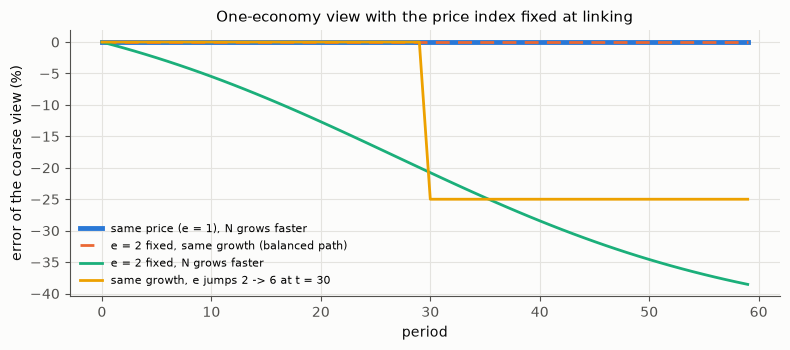

In [42]:
importlib.reload(econ_cat)
t = np.arange(60)
qO = np.exp(0.02 * t)
CASES5 = [
    ('same price (e = 1), N grows faster', qO, 0.1 * np.exp(0.08 * t), np.ones(60)),
    ('e = 2 fixed, same growth (balanced path)', qO, 0.1 * qO, 2 * np.ones(60)),
    ('e = 2 fixed, N grows faster', qO, 0.1 * np.exp(0.08 * t), 2 * np.ones(60)),
    ('same growth, e jumps 2 -> 6 at t = 30', qO, 0.1 * qO, np.where(t < 30, 2.0, 6.0)),
]
fig, ax = plt.subplots(figsize=(8, 3.6))
for j, (lab, a_, b_, e_) in enumerate(CASES5):
    err = econ_cat.coarse_error(a_, b_, e_)
    ax.plot(t, 100 * err, color=PAL[j], ls=('-', (0, (5, 3)), '-', '-')[j], lw=(3.5, 2, 2, 2)[j], label=lab)
    print(f'{lab:44s}: 60 期目のずれ {100 * err[-1]:6.1f}%')
ax.axhline(0, color=INK2, lw=0.6, zorder=0)
ax.set(xlabel='period', ylabel='error of the coarse view (%)', title='One-economy view with the price index fixed at linking'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- 値段が同じ(為替が 1)なら、N がどれだけ速く育っても、ずれは 0 である(一物一価)。
- 値段が違っても、二つが**同じ速さで育ち、構成が変わらない**なら、ずれは 0 である。これが「信用の世界経済は一つか」の**定理 A**(釣り合い経路の上での厳密な縮約)の、一番簡単な姿である。
- 値段が違い、構成が変わると(N が速く育つと)、ずれが育つ。
- 為替が跳ぶと、ずれも跳ぶ。「信用の世界経済は一つか」の 11.3 節で、「通貨が別々の世界を縮約するには、為替を追加の状態変数として持たなければならない」と述べたのは、このことである。

まとめると、**縮約が正しいのは、まとめる中で物差しが一つであるか、物差しが違っても構成が変わらないときである**。どちらでもなければ、縮約は少しずつずれていき、物差しが跳べば、一挙に壊れる。

### 5.4 埋め込みと根

ここで、作者の「埋め込み」に戻る。

経済 P の中に、別の経済 C が育っているとする。C は自分の財と、自分の物差し(単位)を持つ。P から見ると、C は、5.2 で見たように、**一つの点にまとめて**見えている。P の主体が C の資産を持っていれば、P からは、それを為替 $e$ で P の単位に換算した値打ちしか見えない。C の中で何が起きているか(どんな取引があり、どんな値段が付いているか)は、P からは見えない。これが、C が P の中で「バーチャルに」動いている、ということである。圏の言葉では、P の側の見方は、

- C の中の勘定を、一つにまとめる射(5.2)と、
- C の単位を P の単位に直す評価(5.3)

を合成したものである。

この見方の基準になっている経済(ここでは P)を、**根**と呼ぶことにする。根は、二つのことを決めている。

1. **何で測るか**(物差しの単位)。
2. **どこを細かく見て、どこをまとめて見るか**(どの部分がバーチャルか)。

**格上げ**とは、根が入れ替わることである。C が根になり、P が、C から見て一つにまとめて見られる側(バーチャルな側)になる。

では、根を入れ替えると、何が変わるのか。旧い経済 O と新しい経済 N に、主体が 3 人ずついるとして、根を O にした見え方と、根を N にした見え方を比べる。

In [43]:
%%writefile -a econ_cat.py
def view(hold, member, pO, pN, e, root):
    """世界の見え方。hold: 主体ごとの (旧い資産の数, 新しい資産の数)、member: 主体ごとの所属('O' か 'N')。
    pO は旧い資産の値段(O の単位)、pN は新しい資産の値段(N の単位)、e は N の 1 単位が O の何単位か。
    root の経済の単位で測り、root の主体は一人ずつ、もう一方の経済は一つにまとめて見せる。"""
    rate = {'O': 1.0, 'N': 1.0 / e}[root]                 # O の単位 → root の単位
    val = {i: (h[0] * pO + h[1] * pN * e) * rate for i, h in hold.items()}
    out = {i: v for i, v in val.items() if member[i] == root}
    other = 'N' if root == 'O' else 'O'
    out[f'{other} 経済(まとめて)'] = sum(v for i, v in val.items() if member[i] == other)
    return out

Appending to econ_cat.py


In [44]:
importlib.reload(econ_cat)
hold = {'O1': (10, 0), 'O2': (6, 1), 'O3': (3, 0), 'N1': (0, 5), 'N2': (1, 3), 'N3': (0, 1)}   # (旧い資産, 新しい資産)
member = {i: i[0] for i in hold}
pO, pN = 1.0, 1.0
def show(e, root):
    v = econ_cat.view(hold, member, pO, pN, e, root); tot = sum(v.values())
    return '  '.join(f'{k} {x:6.2f} ({x / tot:4.0%})' for k, x in v.items())
for e in (2.0, 6.0):
    print(f'為替 e = {e:g}(N の 1 単位 = O の {e:g} 単位)')
    print('  根 = O:', show(e, 'O'))
    print('  根 = N:', show(e, 'N'))
    sh = {}
    for root in ('O', 'N'):
        v = econ_cat.view(hold, member, pO, pN, e, root); tot = sum(v.values())
        sh[root] = sum(x for k, x in v.items() if k[0] == 'O') / tot
    print(f'  O 経済全体の取り分: 根 = O で {sh["O"]:.1%}、根 = N で {sh["N"]:.1%}')

為替 e = 2(N の 1 単位 = O の 2 単位)
  根 = O: O1  10.00 ( 25%)  O2   8.00 ( 20%)  O3   3.00 (  8%)  N 経済(まとめて)  19.00 ( 48%)
  根 = N: N1   5.00 ( 25%)  N2   3.50 ( 18%)  N3   1.00 (  5%)  O 経済(まとめて)  10.50 ( 52%)
  O 経済全体の取り分: 根 = O で 52.5%、根 = N で 52.5%
為替 e = 6(N の 1 単位 = O の 6 単位)
  根 = O: O1  10.00 ( 12%)  O2  12.00 ( 15%)  O3   3.00 (  4%)  N 経済(まとめて)  55.00 ( 69%)
  根 = N: N1   5.00 ( 38%)  N2   3.17 ( 24%)  N3   1.00 (  8%)  O 経済(まとめて)   4.17 ( 31%)
  O 経済全体の取り分: 根 = O で 31.2%、根 = N で 31.2%


読み方は次のとおりである。

- 為替が同じなら、根を O にしても N にしても、**取り分は変わらない**。e = 2 のとき、O 経済全体の取り分は、根が O でも N でも 52.5% である。根が N のときは、O の主体は「O 経済」の一つの点にまとめられて、一人ずつは見えなくなるが、全体としての取り分は同じである。単位が変わるだけである。これは、第 4 章の「デノミネーションでは取り分は変わらない」と同じことで、圏の言葉では、根の入れ替えは、二つの見方のあいだの**自然同型**(行きも帰りもできる、可換な変換)になっている。
- 取り分を変えるのは、**為替の変化**である。e が 2 から 6 になると、O 経済全体の取り分は 52.5% から 31.2% に下がる(どちらの根で見ても同じ)。誰も何も売り買いしていないのに、である。

つまり、根の入れ替えそのものは、**単位の付け替えと、どこを細かく見るかの選び直し**にすぎず、保存も分け前も変えない。分け前を変えるのは、それに伴って起こる**評価の跳び**(為替や、旧い資産の値段の不連続な変化)である。

では、なぜ、根の入れ替えと評価の跳びが、いっしょに起こるのか。根の経済は、**値段の錨**(いかり)だからである。旧い資産の値段は、旧い経済の中の需要(誰がそれを欲しがり、それで何ができるか)に支えられている。新しい経済が根になると、旧い資産の値段は、新しい経済から見た使い道で測り直される。IT 革命のあとの旧い産業の設備、通貨改革のあとの旧い通貨建ての預金、覇権の交代のあとの旧い覇権国の国債が、その例である。錨が替われば、値段は一挙に動く。

### 5.5 縮約と格上げの位置関係

この章の結論をまとめる。

| | 縮約 | 格上げ |
|---|---|---|
| 圏の言葉では | 射の合成(まとめ方の選び方) | 根(見方の基準)の入れ替え |
| 物差し | 固定されている | 入れ替わる |
| 成り立つ条件 | まとめる中で一物一価か、構成が変わらない(定理 A) | — |
| 保存 | 守られる(集計は保存を守る関手) | 守られる(守られなければならない) |
| 評価 | 自然変換(まとめる順序によらない) | 跳ぶ(自然でなくなる) |
| 中の経済 | まとめた点の中で、バーチャルに動く | バーチャルだった側が、細かく見られる側になる |

縮約と格上げは、対立するものではなく、**補い合う**ものである。

- 縮約は、物差しが固定されているあいだの理論である。その成り立つ条件(一物一価か、構成が一定)が満たされているあいだ、粗く描いた経済は、細かく描いた経済と一致する。
- その条件が少しずつ崩れていくと(バーチャルな部分が速く育ち、その中の値段が独自に動き出すと)、縮約のずれが育つ。
- そして、物差しそのものが入れ替わる瞬間に、縮約は一挙に壊れる。それが格上げである。格上げのあとは、新しい根の下で、また縮約が成り立つ。

言い換えると、**格上げとは、縮約(どこをまとめて見るか)の選び直しが、評価の跳びとともに起こる出来事**である。2011 年の作者の「埋め込み」と、2026 年の「縮約」は、同じ問いの、二つの面だったことになる。

### 5.6 自然でないものも、圏の言葉で書ける

「格上げは自然変換でない」と言うと、格上げは圏論の言葉では表せないのか、と思われるかもしれない。そうではない。「自然でない」というのは、「ある四角が可換でない」という、圏の言葉で書かれた主張である。格上げは、もう一段大きな構造を使えば、圏の言葉で書ける。三つの段階に分けて述べる。

**(1) モードを土台にした圏.** どちらの経済が根かを「モード」と呼び、モードの圏 $\mathcal{B}$ を考える。対象は「O が根」と「N が根」の二つ、射は「格上げ」(O → N)と「戻り」(N → O)である。各モード $m$ に、そのモードでの帳簿の圏(第 5.2 節。集計を射とし、そのモードの物差しで評価する)$\mathcal{F}(m)$ を載せる。格上げの射 $u: O \to N$ には、帳簿を新しい物差しで評価し直す関手 $\mathcal{F}(u): \mathcal{F}(O) \to \mathcal{F}(N)$(評価の跳び)を対応させる。これを、数学では**インデックス付き圏**と呼ぶ。

**(2) 全体を一つの圏にまとめる.** インデックス付き圏は、「モードの切り替え」と「モードの中の集計」を、両方とも射として持つ一つの圏にまとめられる。この作り方を**グロタンディーク構成**という。4.2 で、複式簿記を「差の群(グロタンディーク群)」として書いたのと、同じ数学者の名前の付いた、同じく「ただ一つに決まる」作り方である。こうしてまとめた圏の中では、平時の流れ(モードの中)と、格上げ(モードの切り替え)とが、同じ一つの言葉で書ける。モードの中では、評価は自然変換である(5.3)。モードをまたぐ射についてだけ、四角が可換にならない。

**(3) 自然でなさの大きさを測る.** 可換でない四角に、「二つの道の結果が、どれだけ離れているか」という数を付けることができる(距離を持った圏。数学者ローヴェアが、距離空間を圏の一種として扱う見方を示した)。第 8 章で、格上げの跳びの倍率が、まとめた中の構成比 $s$ によって違うことを見る。その違いが、この「自然でなさ」の大きさになる。つまり、格上げは、**圏の言葉で書けないもの**ではなく、**自然さがどれだけ壊れるかを、数で測れるもの**である。

では、圏の言葉で、本当に書けないものは何か。それは、**新しい対象そのものが現れること**である。この章の議論でも、第 6 章の模型でも、新しい経済 N は、最初から「根の候補」として用意されていた。圏は、すでにある対象のあいだの関係を書く言葉であり、何が新しく現れるかを、その構造から導くことはできない。このことは、第 9 章でもう一度取り上げる。

次の第 6 章では、これを、入れ子の経済の小さな模型で、実際に起こしてみせる。そこで、格上げを引き起こすもの(引き金)として、規模・評価・信頼の三つを比べる。

### 5.7 Lean: 集計は保存を守り、評価は一物一価の範囲で自然

5.2 節と 5.3 節の命題を証明する。一つの取引は、払う側に −a、受け取る側に +a を書くので、両方が同じ組にいれば、組の中の和は 0 になる(まとめた点の中の受け払いは見えなくなる。4.4 節の「見える受け払いの割合」が、全体を一つにまとめると 0% になった理由)。段階的にまとめても、一度にまとめても総和は同じ。そして、まとめても評価が自然である(どの量でも、一つの値段で評価した和が、ばらばらの値段で評価した和に等しい)のは、組の中の値段がすべて等しいとき、そのときに限る。値段が違っても構成が一定なら、指数で評価はずれない(縮約の定理 A の最小の姿)。

In [45]:
%%writefile -a embedded_economy.lean
/-! ## 第 5 章 経済の圏: 集計は保存を守る

一つの取引は、払う側に −a、受け取る側に +a を書く。払う側と受け取る側が同じ組にいれば、
その組の中の和は 0 になる(まとめた点の中の受け払いは見えなくなる。経済が「バーチャル」になる)。 -/
def entry {S : Type*} [DecidableEq S] (src dst : S) (a : ℝ) (s : S) : ℝ :=
  (if s = dst then a else 0) - (if s = src then a else 0)

theorem internal_trade_vanishes {S : Type*} [DecidableEq S] (g : Finset S) (src dst : S) (a : ℝ)
    (hs : src ∈ g) (hd : dst ∈ g) : ∑ s ∈ g, entry src dst a s = 0 := by
  simp [entry, Finset.sum_sub_distrib, Finset.sum_ite_eq', hs, hd]

/-- 段階的にまとめても、一度にまとめても、総和は同じ(集計は和を保つ)。 -/
theorem aggregate_in_stages {S G : Type*} [Fintype S] [Fintype G] [DecidableEq G] (grp : S → G) (x : S → ℝ) :
    ∑ g, ∑ s ∈ univ.filter (fun s => grp s = g), x s = ∑ s, x s :=
  Finset.sum_fiberwise univ grp x

/-- 一物一価: 組の中の値段 p_i で量 q_i を評価した和が、どの量でも一つの値段 p̄ × 量の和に等しいのは、
組の中の値段がすべて p̄ に等しいとき、そのときに限る(まとめても評価が自然である条件)。 -/
theorem one_price_iff {ι : Type*} [DecidableEq ι] (s : Finset ι) (p : ι → ℝ) (pbar : ℝ) :
    (∀ q : ι → ℝ, ∑ i ∈ s, p i * q i = pbar * ∑ i ∈ s, q i) ↔ ∀ i ∈ s, p i = pbar := by
  constructor
  · intro h i hi
    have := h (fun j => if j = i then 1 else 0)
    simpa [Finset.sum_ite_eq', hi] using this
  · intro h q
    rw [Finset.mul_sum]
    exact Finset.sum_congr rfl (fun i hi => by rw [h i hi])

/-- 構成が一定(量が q_i = w_i Q)なら、値段が違っても、指数 Σ p_i w_i で評価はずれない(定理 A の最小の姿)。 -/
theorem constant_composition {ι : Type*} (s : Finset ι) (p w : ι → ℝ) (Q : ℝ) :
    ∑ i ∈ s, p i * (w i * Q) = (∑ i ∈ s, p i * w i) * Q := by
  rw [Finset.sum_mul]; exact Finset.sum_congr rfl (fun i _ => by ring)

Appending to embedded_economy.lean


## 第 6 章 入れ子の経済の模型

第 5 章で、格上げを「根(物差しの基準)の入れ替え」と定め、根の入れ替えそのものは単位の付け替えにすぎず、分け前を変えるのは、それに伴う評価の跳びだと述べた。この章では、旧い経済の中で新しい経済が育ち、根が入れ替わるまでを、小さな模型で実際に起こしてみせる。

確かめたいことは、次の五つである。

1. 新しい経済は、どういう道筋で育ち、いつ根になるのか。
2. 格上げの引き金として、規模・評価・信頼の三つを比べると、何が違うのか。
3. 格上げで、誰が得をし、誰が損をするのか。
4. 行きと帰りで道筋が違う(履歴現象)のは、なぜか。
5. 縮約は、どこで壊れるのか。政策で、遷移を滑らかにできるのか。

**はじめに、この模型の限界を書いておく。** この模型は、仕組みを見せるための小さなもので、現実の数字に合わせたものではない。値の大きさや時期には意味がなく、意味があるのは、どういう向きの仕組みがあるか、だけである。また、主体が売り買いをしない(持分を持ち続ける)という、思い切った単純化をしている。

### 6.1 模型

一期を一年とする。財は一つで(実物の単位で測る)、それを作る技術が二つある。

- **旧い技術 O**: $Y_O = A_O K_O^{\alpha}$。生産性 $A_O$ は一定。
- **新しい技術 N**: $Y_N = A_N K_N^{\alpha}$。生産性 $A_N$ は、N への投資の累計 $X$ とともに伸びる(作れば作るほど上手になる。ライトの法則): $A_N = A_{N0}\,(1 + X / X_0)^{b}$。

N は、最初は小さく、生産性も低い。O の中の一部として「バーチャルに」動いている。

**資本の値打ち**(資本一単位の値段、実物の単位): $q_X = f_X \times (1 + \lambda\,[\text{根} = X]) \times B_X$。

- $f_X$ は**基礎的な価値**(資本一単位が生む限界生産物を、割引率で割ったもの)。
- $\lambda$ は**根の上乗せ**である。根の経済の資産は、担保や決済の手段として使えるので、その分だけ高く評価される。現実には、基軸通貨国の国債が、利回りが低くても買われる(「利便性の利回り」と呼ばれる。Krishnamurthy and Vissing-Jorgensen 2012)。第 5 章の「根は値段の錨」を、この一つの数で表す。
- $B_N$ は、N の資本の**泡**(バブル)である。N の生産が速く伸びると、人々はそれを先へ延ばして期待し、泡が膨らむ。伸びが鈍ると、泡は萎む: $\log B_N(t) = \rho_B \log B_N(t-1) + \phi\,(g_{Y_N}(t) - \bar g)$。旧い資本には泡がない($B_O = 1$)。

**投資**: 貯蓄(生産の 2 割)を、値打ちの比 $q_N / q_O$ に応じて、O と N に分ける(値打ちの高いほうに、多く投資する。トービンの q)。

**単位の採用**(信頼): 人々のうち、N の単位(N のお金)を使う人の割合を $s$ とする。使う単位は、

- N の実物の重み(生産の割合)、
- ほかの人が何を使っているか(ネットワーク効果。みんなが使う単位は便利)、
- どちらが根か(根の単位は、税や契約に使われる)、

で決まり、ゆっくり動く。お金の値打ちは、それを使う人の割合に比例する(旧いお金の値打ち $\propto (1 - s)Y$、新しいお金の値打ち $\propto sY$)。ネットワーク効果のある通貨の選択は、Dowd and Greenaway(1993)や Matsuyama, Kiyotaki and Matsui(1993)が論じている。

**根の決め方**(引き金)は、三つを比べる。

- **規模**: N の生産の割合 $Y_N / (Y_O + Y_N)$ が 1/2 を超えたら、N が根になる。
- **評価**: N の資本の値打ちの割合 $q_N K_N / (q_N K_N + q_O K_O)$ が 1/2 を超えたら、N が根になる。
- **信頼**: N の単位を使う人の割合 $s$ が 1/2 を超えたら、N が根になる。

どれも、1/2 を下回れば、O に戻る。根は、その期の終わりに入れ替わり、次の期の値打ちから効く。

In [46]:
%%writefile nest.py
"""nest.py -- 入れ子の経済の模型。旧い経済 O の中で、新しい経済 N が育ち、根(物差しの基準)が入れ替わる。

一期 = 一年。財は一つ(実物の単位で測る)で、それを作る技術が二つある。
- 旧い技術 O: Y_O = A_O K_O^α(A_O は一定)。
- 新しい技術 N: Y_N = A_N K_N^α。A_N は、N への投資の累計 X で伸びる(ライトの法則): A_N = A_N0 (1 + X/X0)^b。
資本の値打ち(資本一単位の値段、実物の単位)は q_X = f_X × (1 + λ[根 = X]) × B_X。
- f_X: 基礎的な価値(限界生産物の永久年金)。
- λ: 根の資産の流動性の上乗せ(根の経済の資産は、担保や決済に使えるので、その分だけ高く評価される)。
- B_N: N の資本の泡(バブル)。N の生産の伸びを外挿して膨らみ、伸びが鈍ると萎む。B_O = 1。
投資は、貯蓄 s_r Y を、値打ちの比 q_N / q_O に応じて O と N に分ける(トービンの q)。
単位の採用: N の単位(N のお金)を使う人の割合 s は、N の実物の重み、ほかの人の使い方(ネットワーク効果 β)、
どちらが根か(ζ)で決まり、ゆっくり動く。お金の値打ちは、使う人の割合に比例する: v_O ∝ (1 − s) Y、v_N ∝ s Y。
N への投資は、ban_until 期まで ban_N の割合だけ抑えられる(抑止の政策)。dual=True は、二つの物差しの併用(上乗せを半分ずつ)。
hype は、外から泡に加わる熱狂(期ごとの log B への上乗せ)。fix_flip は、法で根を入れ替える年(通貨改革。その年から N の単位を使う人を 9 割以上にする)。
根の決め方(引き金)は三つ: 'size'(N の生産の割合)、'value'(N の資本の値打ちの割合)、'trust'(s)。
どれも 1/2 を超えたら N が根になり、1/2 を下回ったら O に戻る。
"""
import numpy as np

P0 = dict(T=100, alpha=0.4, delta=0.06, s_r=0.2, rho=0.04, A_O=1.0, A_N0=0.1, X0=0.3, b=0.6,
          K_O0=None, K_N0=0.3, gamma=4.0, lam=0.3, rho_B=0.88, phi=1.2,
          c_a=5.0, beta=1.3, zeta=0.3, sig=0.5, kappa=0.3, s0=0.02, mu=0.3,
          g_bar=0.03, trigger='trust', A_N_path=None, ban_N=0.0, ban_until=0, dual=False, hype=None, fix_flip=None)


def logistic(x):
    return 1.0 / (1.0 + np.exp(-x))


def run(**kw):
    """模型を走らせ、期ごとの記録(dict of arrays)を返す。"""
    p = dict(P0, **kw)
    T, al, de = p['T'], p['alpha'], p['delta']
    K_O = p['K_O0'] if p['K_O0'] is not None else (p['s_r'] * p['A_O'] / de) ** (1 / (1 - al))
    K_N, X, s, logB, root = p['K_N0'], 0.0, p['s0'], 0.0, 'O'
    Y_N_prev = None
    keys = ('A_N', 'K_O', 'K_N', 'Y_O', 'Y_N', 'q_O', 'q_N', 'B', 's', 'v_O', 'v_N', 'root_N', 'size', 'value', 'iota')
    rec = {k: np.zeros(T) for k in keys}
    for t in range(T):
        if p['fix_flip'] is not None and t == p['fix_flip']:      # 法で決めた年に、根と単位を入れ替える(通貨改革)
            root, s = 'N', max(s, 0.9)
        A_N = p['A_N_path'][t] if p['A_N_path'] is not None else p['A_N0'] * (1 + X / p['X0']) ** p['b']
        Y_O, Y_N = p['A_O'] * K_O ** al, A_N * K_N ** al
        Y = Y_O + Y_N
        f_O = al * Y_O / K_O / (p['rho'] + de)
        f_N = al * Y_N / K_N / (p['rho'] + de)
        gY = 0.0 if Y_N_prev is None else np.log(Y_N / Y_N_prev)
        logB = p['rho_B'] * logB + p['phi'] * (gY - p['g_bar'])
        if p['hype'] is not None:                                  # 外から来る熱狂(実物の伸びによらない泡)
            logB += p['hype'][t]
        Y_N_prev = Y_N
        if p['dual']:                                              # 併用: 二つの物差しを公に認め、上乗せを分け合う
            q_O, q_N = f_O * (1 + p['lam'] / 2), f_N * (1 + p['lam'] / 2) * np.exp(logB)
        else:
            q_O = f_O * (1 + p['lam'] * (root == 'O'))
            q_N = f_N * (1 + p['lam'] * (root == 'N')) * np.exp(logB)
        size = Y_N / Y
        value = q_N * K_N / (q_N * K_N + q_O * K_O)
        # 単位の採用(ネットワーク効果と、根であることの利点)
        target = logistic((p['c_a'] * (size - 0.5) + p['beta'] * (2 * s - 1) + p['zeta'] * (1 if root == 'N' else -1)) / p['sig'])
        s = s + p['kappa'] * (target - s)
        v_O, v_N = p['mu'] * (1 - s) * Y, p['mu'] * s * Y          # お金の総額は O・N とも 1 とする
        root_used = root                                           # この期の値打ちに使った根
        # 根の決め方(この期の終わりに入れ替わり、次の期から効く)
        stat = {'size': size, 'value': value, 'trust': s}[p['trigger']]
        if p['fix_flip'] is not None:                              # 法で根を入れ替える場合は、引き金を使わない
            pass
        elif root == 'O' and stat > 0.5:
            root = 'N'
        elif root == 'N' and stat < 0.5:
            root = 'O'
        # 投資
        iota = logistic(p['gamma'] * np.log(q_N / q_O))
        if t < p['ban_until']:
            iota *= (1 - p['ban_N'])
        I = p['s_r'] * Y
        K_O = (1 - de) * K_O + (1 - iota) * I
        K_N = (1 - de) * K_N + iota * I
        X += iota * I
        for k, v in zip(keys, (A_N, K_O, K_N, Y_O, Y_N, q_O, q_N, np.exp(logB), s, v_O, v_N, root_used == 'N', size, value, iota)):
            rec[k][t] = v
    return rec

Overwriting nest.py


パラメータ: {'T': 100, 'alpha': 0.4, 'delta': 0.06, 's_r': 0.2, 'rho': 0.04, 'A_O': 1.0, 'A_N0': 0.1, 'X0': 0.3, 'b': 0.6, 'K_N0': 0.3, 'gamma': 4.0, 'lam': 0.3, 'rho_B': 0.88, 'phi': 1.2, 'c_a': 5.0, 'beta': 1.3, 'zeta': 0.3, 'sig': 0.5, 'kappa': 0.3, 's0': 0.02, 'mu': 0.3, 'g_bar': 0.03, 'ban_N': 0.0, 'ban_until': 0, 'dual': False, 'hype': None, 'fix_flip': None}


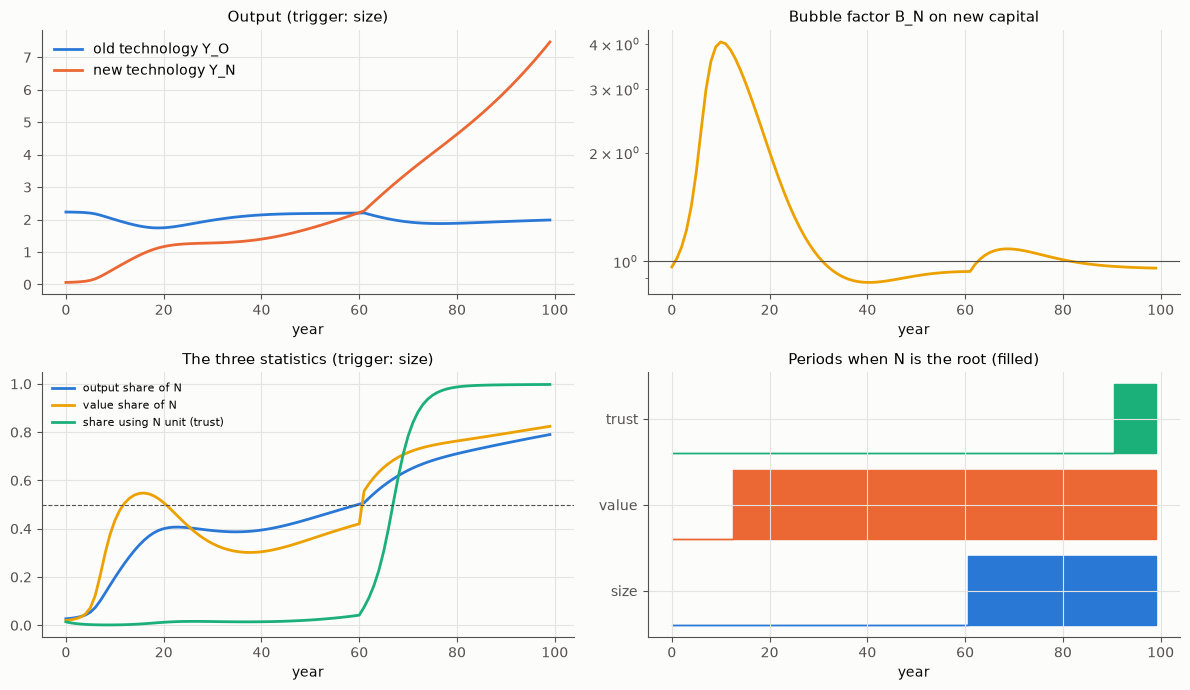

引き金 = 規模: 根が入れ替わった年 [61]、100 年の生産の合計 457.8
引き金 = 評価: 根が入れ替わった年 [13]、100 年の生産の合計 574.3
引き金 = 信頼: 根が入れ替わった年 [91]、100 年の生産の合計 428.0


In [47]:
import nest
importlib.reload(nest)
print('パラメータ:', {k: v for k, v in nest.P0.items() if k not in ('A_N_path', 'K_O0', 'trigger')})
TRIG = {'size': '規模', 'value': '評価', 'trust': '信頼'}
RUN = {g: nest.run(trigger=g) for g in TRIG}
r = RUN['size']; t = np.arange(len(r['s']))
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(t, r['Y_O'], color=PAL[0], label='old technology Y_O'); ax[0, 0].plot(t, r['Y_N'], color=PAL[1], label='new technology Y_N')
ax[0, 0].set(title='Output (trigger: size)', xlabel='year'); ax[0, 0].legend()
ax[0, 1].plot(t, r['B'], color=PAL[3]); ax[0, 1].axhline(1, color=INK2, lw=0.8)
ax[0, 1].set(title='Bubble factor B_N on new capital', xlabel='year', yscale='log')
for k, c in (('size', PAL[0]), ('value', PAL[3]), ('s', PAL[2])):
    ax[1, 0].plot(t, r[k], color=c, label={'size': 'output share of N', 'value': 'value share of N', 's': 'share using N unit (trust)'}[k])
ax[1, 0].axhline(0.5, color=INK2, lw=0.8, ls='--'); ax[1, 0].set(title='The three statistics (trigger: size)', xlabel='year'); ax[1, 0].legend(fontsize=8)
for j, g in enumerate(TRIG):
    ax[1, 1].fill_between(t, j + 0.1, j + 0.1 + 0.8 * RUN[g]['root_N'], color=PAL[j], step='mid')
ax[1, 1].set(yticks=[0.5, 1.5, 2.5], yticklabels=['size', 'value', 'trust'], title='Periods when N is the root (filled)', xlabel='year')
plt.tight_layout(); plt.show()
for g, lab in TRIG.items():
    rr = RUN[g]; fl = np.flatnonzero(np.diff(rr['root_N'].astype(int))) + 1
    print(f'引き金 = {lab}: 根が入れ替わった年 {[int(x) for x in fl]}、100 年の生産の合計 {(rr["Y_O"] + rr["Y_N"]).sum():.1f}')

### 6.2 一本の経路: 泡、崩壊、そして本体へ

左上と右上の図(引き金 = 規模の場合)を読む。

1. **導入期**(0〜10 年): N の生産性はまだ低いが、生産が速く伸び始めると、泡が膨らむ(右上、10 年目に基礎的な価値の 4 倍)。値打ちが高いので、投資の大部分が N に向かう。
2. **崩壊**(10〜30 年): 伸びが鈍ると、泡は萎み、値打ちは基礎的な価値を下回るところまで落ちる。N への投資は減る。
3. **転換と展開**(30 年〜): その間にも、泡のときの投資で N の生産性は上がっている。N の生産は着実に増え、61 年目に生産の半分を超える。その後、N の単位を使う人が急に増え(左下の緑)、N が経済の本体になる。

これは、Perez(2002)が描いた技術革命の道筋に、よく似ている。新しい技術は、旧い体制の金融の中で泡として育ち(導入期)、泡が崩れ(転換点)、そのあと、新しい制度の下で経済の本体になる(展開期)。泡は無駄ではなく、新しい技術を育てる投資の資金になる。この模型でも、泡の時期の投資が、N の生産性を押し上げている。

### 6.3 三つの引き金を比べる

右下の図は、三つの引き金で、N が根である期間を示している。

- **評価**の引き金では、泡のさなかの 13 年目に、N が根になる。
- **規模**の引き金では、61 年目に根になる。
- **信頼**の引き金では、91 年目まで根にならない。

三つの統計(左下)は、それぞれ違う時期に 1/2 を超える。**値打ちは期待で動くので早く、実物の規模はそれより遅く、人々の習慣(どの単位を使うか)は一番遅い**。

さらに、引き金によって、その後の経済そのものが変わる。評価の引き金で早く根になると、生産の合計が大きい。なぜか。根の上乗せ $\lambda$ がなければ、根がどちらでも、実物の経済は同じになるはずである。$\lambda$ を 0 にして比べる。

In [48]:
print('根の上乗せ λ   引き金   根が入れ替わった年        100 年の生産の合計')
for lam in (0.3, 0.0):
    for g, lab in TRIG.items():
        rr = nest.run(trigger=g, lam=lam); fl = np.flatnonzero(np.diff(rr['root_N'].astype(int))) + 1
        print(f'   {lam:.1f}          {lab}    {str([int(x) for x in fl]):24s}  {(rr["Y_O"] + rr["Y_N"]).sum():8.1f}')

根の上乗せ λ   引き金   根が入れ替わった年        100 年の生産の合計
   0.3          規模    [61]                         457.8
   0.3          評価    [13]                         574.3
   0.3          信頼    [91]                         428.0
   0.0          規模    [40]                         534.7
   0.0          評価    [8, 30, 43]                  534.7
   0.0          信頼    [67]                         534.7


- **$\lambda = 0$(根であることに得がない)**: どの引き金でも、生産の合計はまったく同じである。根の入れ替えは、ただの呼び名の付け替えで、実物には何の影響もない(第 5 章の「根の入れ替えそのものは自然同型」)。ただし、評価の引き金では、根が 8 年目に N になり、泡が崩れると 30 年目に O に戻り、43 年目にまた N になる。**泡による偽の格上げ**である。
- **$\lambda = 0.3$(根の資産に上乗せがある)**: 根が、実物の経済を変える。根である O の資産は上乗せの分だけ高く評価されるので、投資が O に偏り、N の成長が遅れる。**旧い根が、新しい経済の成長を押しとどめる**。その結果、規模や信頼の引き金では、格上げが遅れ、生産の合計が小さくなる。一方、評価の引き金では、泡のさなかに N が根になると、今度は上乗せが N に付くので、泡が崩れても N の値打ちが 1/2 を下回らない。**泡が、自分自身を正当化する格上げを起こし、それが固定される**。投資が N に向かい続けるので、生産の合計は大きい。

根に得がある限り、根の入れ替えは、ただの呼び名の付け替えではなく、経済の道筋を変える。そして、いったん入れ替わると、上乗せが新しい根を支えるので、元に戻りにくい。これが、次の 6.5 の履歴現象の種である。

### 6.4 誰が得をし、誰が損をするか

主体を、最初の財産の持ち方で四つの組に分ける。

| 組 | 旧い資本 | 新しい資本 | 旧いお金 | 新しいお金 |
|---|---|---|---|---|
| 旧い資本家 | 0.8 | 0 | 0.2 | 0 |
| 旧いお金の預金者 | 0.2 | 0 | 0.8 | 0 |
| 先駆者 | 0 | 0.6 | 0.2 | 0.2 |
| 分散 | 0.25 | 0.25 | 0.25 | 0.25 |

(数は、各組の財産のうち、その種類に置いている割合。)どの組も、最初に持った持分を、ずっと持ち続ける(売り買いしない)。そうしておけば、分け前の変化は、すべて**評価の変化**であり、取引によるものではない(第 4 章の「Δ正味資産 = 貯蓄 + 評価の変化」の、後ろの項だけを取り出したことになる)。

In [49]:
%%writefile -a nest.py
GROUPS = {   # 最初の値打ちの配分: (旧い資本, 新しい資本, 旧いお金, 新しいお金)
    'old capitalists': (0.8, 0.0, 0.2, 0.0),
    'old-money savers': (0.2, 0.0, 0.8, 0.0),
    'pioneers': (0.0, 0.6, 0.2, 0.2),
    'diversified': (0.25, 0.25, 0.25, 0.25),
}


def classes(rec):
    """四つの資産の種類の、実物の単位での値打ちの合計: 旧い資本、新しい資本、旧いお金、新しいお金。"""
    return np.stack([rec['q_O'] * rec['K_O'], rec['q_N'] * rec['K_N'], rec['v_O'], rec['v_N']])


def group_wealth(rec, convert=False, keep=1.0, per_head=False):
    """四つの組の、実物の単位での値打ち(組 × 期)。各組は、資産の種類ごとに、最初の配分に比例した持分を持ち続ける
    (誰も売り買いしない)。convert=True なら、N が根になった期 tf に、旧いお金を、その期の為替で新しいお金に換える
    (換算保証。為替は、格上げ直前の年のもの)。旧いお金はなくなり、お金の値打ちの全体(v_O + v_N)を、新しいお金が担う。
    新しいお金が増発されるので、もとの新しいお金の持ち主の持分は薄まる。
    keep < 1 なら、旧いお金は、その値打ちの keep 倍だけが換えられる(切り捨てのある通貨改革。10 対 1 なら 0.1)。
    per_head=True なら、切り捨てた分の新しいお金を、四つの組に等しく配る(一人あたりの配布。組の人数は等しいとする)。"""
    V = classes(rec)
    W = np.array(list(GROUPS.values()))                      # 組 × 種類 の配分
    share = W / W.sum(0, keepdims=True)                       # 種類ごとの、組の持分
    out = share @ V
    flip = np.flatnonzero(rec['root_N'])
    if convert and len(flip):
        tf = flip[0]
        add = keep * rec['v_O'][tf - 1] / rec['v_N'][tf - 1]  # 格上げ直前の年の為替で換える。新しいお金を、もとの量(1)に対してこれだけ増発する
        head = (1 - keep) * rec['v_O'][tf - 1] / rec['v_N'][tf - 1] if per_head else 0.0
        mshare = (share[:, 3] + share[:, 2] * add + head / len(share)) / (1.0 + add + head)
        out[:, tf:] = np.outer(share[:, 0], V[0, tf:]) + np.outer(share[:, 1], V[1, tf:]) + np.outer(mshare, V[2, tf:] + V[3, tf:])
    return out

Appending to nest.py


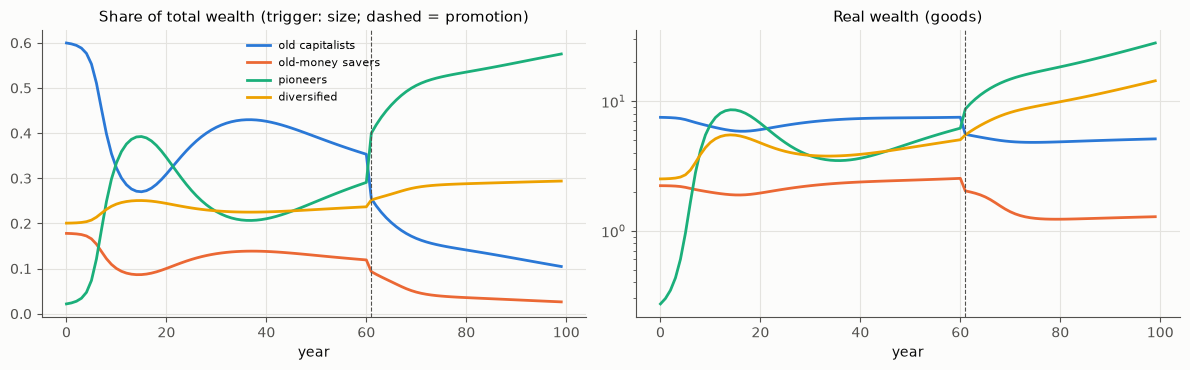

根が入れ替わった年 61 の前後一年での、分け前の変化:
  old capitalists     35.3% →  25.5%   (100 年目  10.5%、実物の値打ち  7.50 →   5.12)
  old-money savers    11.9% →   9.3%   (100 年目   2.6%、実物の値打ち  2.23 →   1.28)
  pioneers            29.1% →  40.0%   (100 年目  57.5%、実物の値打ち  0.27 →  28.14)
  diversified         23.7% →  25.2%   (100 年目  29.4%、実物の値打ち  2.51 →  14.37)


In [50]:
importlib.reload(nest)
r = RUN['size']; G = nest.group_wealth(r); sh = G / G.sum(0)
tf = int(np.flatnonzero(r['root_N'])[0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for j, g in enumerate(nest.GROUPS):
    ax[0].plot(t, sh[j], color=PAL[j], label=g); ax[1].plot(t, G[j], color=PAL[j], label=g)
for a_ in ax:
    a_.axvline(tf, color=INK2, lw=0.8, ls='--')
ax[0].set(title='Share of total wealth (trigger: size; dashed = promotion)', xlabel='year'); ax[0].legend(fontsize=8)
ax[1].set(title='Real wealth (goods)', xlabel='year', yscale='log')
plt.tight_layout(); plt.show()
print(f'根が入れ替わった年 {tf} の前後一年での、分け前の変化:')
for j, g in enumerate(nest.GROUPS):
    print(f'  {g:18s} {sh[j, tf - 1]:6.1%} → {sh[j, tf]:6.1%}   (100 年目 {sh[j, -1]:6.1%}、実物の値打ち {G[j, 0]:5.2f} → {G[j, -1]:6.2f})')

- 根が入れ替わった**その一年で**、旧い資本家の分け前は約 10 ポイント下がり、先駆者の分け前は約 10 ポイント上がる。誰も何も売り買いしていない。根の上乗せが、旧い資本から新しい資本へ移っただけである。これが、2011 年に作者が書いた「**資産の目減りは、少しずつではなく、枠組みの交代として一挙に起こる**」の姿である。
- 旧いお金の預金者は、格上げの瞬間よりも、そのあと人々が新しい単位に乗り換えていく間に、少しずつ、しかし大きく失う。旧いお金を使う人が減れば、旧いお金の値打ちは下がる。
- 実物の値打ち(右の図)で見ても、旧い資本家は 100 年で約 3 分の 1、預金者は約 4 割を失う。その間に、先駆者の財産は 100 倍になり、経済全体の財産も大きく増えている。失うのは分け前だけではないが、分け前の失い方のほうがはるかに大きい。

### 6.5 履歴現象: 行きと帰りで道が違う

新しい技術の生産性 $A_N$ を、外から、ゆっくり上げていき、また下げていく。そのとき、新しい単位を使う人の割合 $s$ と根がどう動くかを見る(引き金 = 信頼)。ネットワーク効果と根の利点が強い場合と、弱い場合を比べる。

In [51]:
%%writefile -a nest.py
def sweep(beta=1.3, zeta=0.3, lam=0.3, trigger='trust', lo=0.3, hi=2.5, n=300):
    """新しい技術の生産性 A_N を、lo から hi へゆっくり上げ、また lo へ下げる。行きと帰りの (A_N, s, 根) を返す。"""
    path = np.r_[np.linspace(lo, hi, n), np.linspace(hi, lo, n)]
    r = run(T=2 * n, A_N_path=path, beta=beta, zeta=zeta, lam=lam, trigger=trigger)
    return path, r['s'], r['root_N'], r['size']

Appending to nest.py


strong network effect and root advantage     : 上りで N が根になる A_N = 1.63、下りで O に戻る A_N = 0.70
weak network effect, no root advantage       : 上りで N が根になる A_N = 1.21、下りで O に戻る A_N = 0.99


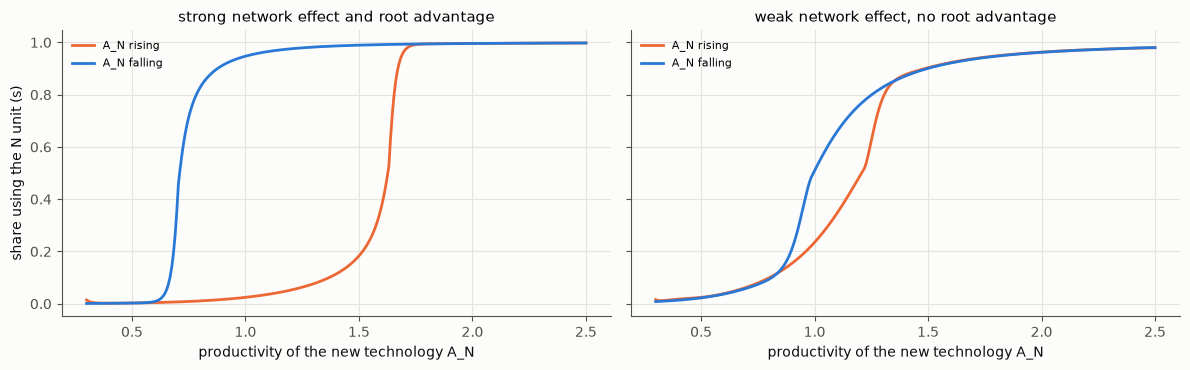

In [52]:
importlib.reload(nest)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for j, (beta, zeta, lab) in enumerate(((1.3, 0.3, 'strong network effect and root advantage'), (0.5, 0.0, 'weak network effect, no root advantage'))):
    A, s_, root_, size_ = nest.sweep(beta=beta, zeta=zeta)
    n = len(A) // 2
    ax[j].plot(A[:n], s_[:n], color=PAL[1], label='A_N rising'); ax[j].plot(A[n:], s_[n:], color=PAL[0], label='A_N falling')
    ax[j].set(title=lab, xlabel='productivity of the new technology A_N'); ax[j].legend(fontsize=8)
    up = A[np.argmax(s_[:n] > 0.5)]; dn = A[n + np.argmax(s_[n:] < 0.5)]
    print(f'{lab:45s}: 上りで N が根になる A_N = {up:.2f}、下りで O に戻る A_N = {dn:.2f}')
ax[0].set_ylabel('share using the N unit (s)')
plt.tight_layout(); plt.show()

ネットワーク効果と根の利点が強いと、行き(生産性が上がるとき)は、生産性が 1.6 を超えるまで、人々は旧い単位を使い続ける。いったん乗り換えると、帰り(生産性が下がるとき)は、0.7 まで下がっても、新しい単位を使い続ける。同じ生産性でも、来た道によって、どちらの経済が根かが違う。**履歴現象**である。

これは、カタストロフィー理論の「**折り目**」(Thom 1972、Zeeman 1977)の形である。みんなが使っている単位を自分も使う、という正の帰還があると、同じ条件に二つの落ち着き先(旧い単位の世界と、新しい単位の世界)ができる。条件がゆっくり変わっても、落ち着き先の一方が消える点で、状態は**跳ぶ**。作者の言う「カタストロフィックな格上げ」は、文字どおりのカタストロフィー(折り目の跳び)として書ける。

ネットワーク効果が弱く、根であることが単位の選び方に効かなければ(ζ = 0)、ループは小さくなり、跳びもなだらかになる。残るのは、人々がゆっくりしか乗り換えないことによる遅れと、根の上乗せ(λ)が投資を通じて N の規模を変える分である。

### 6.6 縮約の破れ

第 5 章で、二つの経済を一つにまとめて描く縮約は、まとめる中で物差しが一つであるか、構成が変わらないときに正しく、物差しが跳べば一挙に壊れる、と述べた。この模型の経路で確かめる。

各年に、前の年の値段の比で二つの資本をまとめて、一つの経済として描いたとき、今年の本当の値打ちとどれだけずれるかを計算する(一年ごとに、まとめ直す縮約)。

引き金 = 規模: 一年ごとの縮約のずれ  格上げの年 ['-24.1%']、それ以外の年の中央値 0.46%
引き金 = 評価: 一年ごとの縮約のずれ  格上げの年 ['-26.7%']、それ以外の年の中央値 0.47%
引き金 = 信頼: 一年ごとの縮約のずれ  格上げの年 ['-29.7%']、それ以外の年の中央値 0.26%


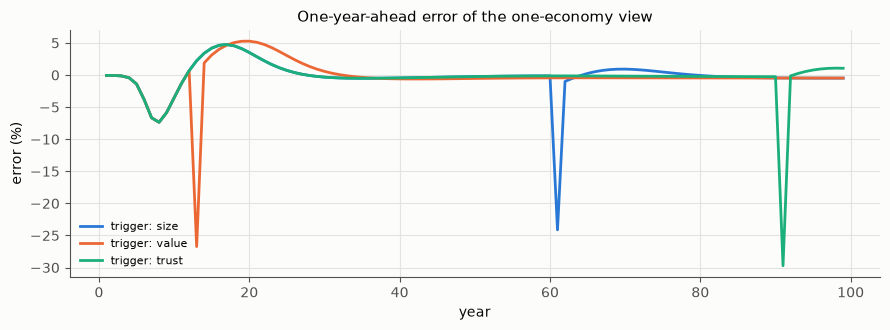

In [53]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for j, g in enumerate(TRIG):
    rr = RUN[g]; e_ = rr['q_N'] / rr['q_O']
    err1 = np.array([econ_cat.coarse_error(rr['K_O'][k - 1:k + 1], rr['K_N'][k - 1:k + 1], e_[k - 1:k + 1])[1] for k in range(1, len(e_))])
    ax.plot(np.arange(1, len(e_)), 100 * err1, color=PAL[j], label=f'trigger: {g}')
    fl = np.flatnonzero(np.diff(rr['root_N'].astype(int))) + 1
    big = np.sort(np.abs(err1))[::-1]
    print(f'引き金 = {TRIG[g]}: 一年ごとの縮約のずれ  格上げの年 {[f"{100 * err1[k - 1]:+.1f}%" for k in fl]}、それ以外の年の中央値 {100 * np.median(np.abs(np.delete(err1, fl - 1))):.2f}%')
ax.axhline(0, color=INK2, lw=0.6, zorder=0)
ax.set(xlabel='year', ylabel='error (%)', title='One-year-ahead error of the one-economy view'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

ふだんの年のずれは、中央値で 0.5% 以下しかない。一年ごとにまとめ直せば、一つの経済として描いても、ほとんど困らない。ところが、**格上げの年には、ずれが一挙に 20〜30% になる**。根の上乗せが入れ替わり、二つの資本の値段の比が跳ぶからである。泡の膨らむ時期と萎む時期にも、値段の比が速く動くので、数% のずれが出る。

縮約は、平時には(まとめ直しさえすれば)よく効く。壊れるのは、物差しの跳ぶ、格上げの瞬間である。第 5 章で述べた「縮約と格上げの位置関係」が、模型の中で、そのまま現れている。

### 6.7 政策: 遷移を滑らかにできるか

旧い経済の政府・中央銀行に、何ができるか。三つの政策を比べる(引き金 = 規模、120 年)。

- **抑止**: 40 年目まで、N への投資を半分に抑える(新しい技術の規制、資本の管理)。
- **併用**: 二つの物差しを公に認める(税や契約に、どちらの単位も使える)。根の上乗せを両方に半分ずつ付け、ネットワーク効果も半分にする。
- **換算保証**: 格上げの年に、旧いお金を、その年の為替で新しいお金に換える(旧いお金の預金者を守る)。

In [54]:
POL = {'なし': {}, '抑止': dict(ban_N=0.5, ban_until=40), '併用': dict(dual=True, beta=0.65)}
print('政策       格上げの年   120 年の生産の合計   格上げの年の旧い資本家の分け前の変化   120 年目の分け前(旧い資本家 / 預金者 / 先駆者)   旧い資本家の実物の値打ち')
for name, kw in POL.items():
    rr = nest.run(trigger='size', T=120, **kw)
    for conv in ((False, True) if name == 'なし' else (False,)):
        G = nest.group_wealth(rr, convert=conv); sh = G / G.sum(0)
        tf = int(np.flatnonzero(rr['root_N'])[0])
        lab = '換算保証' if conv else name
        print(f'{lab:6s}    {tf:5d}        {(rr["Y_O"] + rr["Y_N"]).sum():8.1f}            {100 * (sh[0, tf] - sh[0, tf - 1]):+6.1f} ポイント'
              f'                   {sh[0, -1]:5.1%} / {sh[1, -1]:5.1%} / {sh[2, -1]:5.1%}                {G[0, -1]:5.2f}')

政策       格上げの年   120 年の生産の合計   格上げの年の旧い資本家の分け前の変化   120 年目の分け前(旧い資本家 / 預金者 / 先駆者)   旧い資本家の実物の値打ち
なし           61           694.7              -9.8 ポイント                    7.2% /  1.8% / 61.2%                 5.37
換算保証         61           694.7              -9.8 ポイント                    7.9% /  4.8% / 59.5%                 5.94
抑止           87           469.8              -9.8 ポイント                   11.6% /  2.9% / 56.3%                 5.04
併用           40           810.1              -0.4 ポイント                    8.9% /  2.2% / 59.1%                 7.01


- **抑止**は、格上げを 61 年目から 87 年目に遅らせる。その代わり、新しい技術の学習が遅れ、120 年の生産の合計は 3 分の 2 になる。面白いのは、旧い資本家の立場である。抑止の下では、120 年目の旧い資本家の**分け前**は、政策なしのときより大きい。しかし、**実物の値打ち**は、政策なしのときより小さい。旧い体制の受益者には、パイが小さくなっても自分の取り分が大きいほうを選ぶ動機がある。新しい技術への抵抗が、なぜ起こるのかの一つの説明になる(Acemoglu and Robinson 2006 の「政治的な敗者」の議論に近い)。
- **併用**は、格上げを早め(40 年目)、格上げの年の分け前の跳びを、ほとんどなくす。根の上乗せを独り占めする経済がないので、根の入れ替えが、ただの呼び名の付け替えに近づくからである。生産の合計も最も大きく、旧い資本家の実物の値打ちも最も大きい。
- **換算保証**は、旧いお金の預金者の分け前を守る(120 年目の分け前が、政策なしの 2 倍あまりになる)。ただし、その分は、新しいお金を持っていた先駆者や分散の組の持分が薄まることで賄われている。**保存**の原理どおり、誰かを守る分は、誰かが払う。

この模型の中では、併用が、もっとも滑らかで、もっとも豊かな遷移を作る。ただし、これは根の上乗せを「分け合える」と仮定したからである。現実には、二つの物差しを併用すると、計算や契約の手間がかかる。併用の費用を入れれば、答えは変わりうる。

### 6.8 この章のまとめ

1. 新しい経済は、泡として育ち、泡が崩れたあとで、実物の規模で旧い経済を超え、最後に人々の習慣(どの単位を使うか)が入れ替わる。三つの引き金は、この順に引かれる。
2. 根に得(上乗せ)がなければ、格上げは呼び名の付け替えにすぎない。得があると、旧い根は新しい経済の成長を押しとどめ、いったん入れ替わった新しい根は、元に戻りにくい。泡のさなかの格上げは、自分自身を正当化して固定されうる。
3. 格上げの瞬間に、誰も取引しないまま、分け前が一挙に入れ替わる。旧いお金の預金者は、そのあとの乗り換えの間に、少しずつ大きく失う。
4. ネットワーク効果と根の利点があると、行きと帰りで閾値が違う(折り目のカタストロフィー)。
5. 一つの経済として描く縮約は、平時にはよく効くが、格上げの瞬間に一挙に壊れる。
6. 抑止は遷移を遅らせ、経済を小さくするが、旧い体制の受益者の分け前は守る。併用は遷移を滑らかにする。換算保証は、預金者を守るが、その費用は誰かが払う。

## 第 7 章 事例

第 6 章の模型は、仕組みを見せるための小さなものだった。この章では、現実に「経済の中で経済が育ち、格上げされた」と言えそうな出来事を五つ取り上げ、模型のどの部分、どのパラメータにあたるかを考える。模型で少しずつ試せるところは試す。数字の大きさに意味がないことは、第 6 章と同じである。

### 7.1 技術革命: IT 革命と、二重の泡

作者が 2011 年に思い描いていたのは、「経済危機などで、違う経済が立ち上がってくる」ことだった。その一番はっきりした例は、技術革命である。

Perez(2002)は、産業革命以来の技術革命を五つに分け、どれもが同じ道筋をたどったと論じた。

| | 技術革命 | 始まり(Perez による目印) |
|---|---|---|
| 1 | 産業革命(機械化された綿工業) | 1771 年(アークライトのクロムフォード工場) |
| 2 | 蒸気と鉄道 | 1829 年(リバプール・マンチェスター鉄道の機関車の試験) |
| 3 | 鋼鉄・電気・重工業 | 1875 年(カーネギーの製鋼所) |
| 4 | 石油・自動車・大量生産 | 1908 年(T 型フォード) |
| 5 | 情報と通信 | 1971 年(インテルのマイクロプロセッサー) |

どの革命も、前半の**導入期**には、新しい技術が旧い体制の中で育ち、金融がそこに殺到して泡(バブル)ができる。泡が崩れる**転換点**のあと、制度が組み替えられ、後半の**展開期**に、新しい技術が経済の本体になる。

第 6 章の模型の道筋(泡 → 崩壊 → 規模の逆転 → 単位の入れ替わり)は、この形をなぞったものである。IT 革命については、Perez(2009)が、1990 年代のインターネットの泡と、2000 年代の金融の泡を、「二段階で起きた、一つの 1929 年」と見ている。

Perez の議論で大事なのは、**泡は無駄ではない**という点である。泡のときの過剰な投資が、新しい技術の基盤(鉄道網、電力網、光ファイバー網)を作る。模型で、泡の強さ $\phi$ を変えてみる。

In [55]:
importlib.reload(nest)
fl = lambda r: [int(x) for x in np.flatnonzero(np.diff(r['root_N'].astype(int))) + 1]
Ysum = lambda r: (r['Y_O'] + r['Y_N']).sum()
print('泡の強さ φ   泡の最大(基礎的な価値の何倍か)   格上げの年(規模)   100 年の生産の合計')
for phi in (0.0, 0.6, 1.2, 2.0):
    rr = nest.run(trigger='size', phi=phi)
    print(f'   {phi:.1f}            {rr["B"].max():6.2f}                        {str(fl(rr)):10s}        {Ysum(rr):7.1f}')

泡の強さ φ   泡の最大(基礎的な価値の何倍か)   格上げの年(規模)   100 年の生産の合計
   0.0              1.00                        [88]                321.6
   0.6              1.47                        [78]                361.5
   1.2              4.05                        [61]                457.8
   2.0             12.74                        [22]                601.1


泡が強いほど、格上げは早く、生産の合計は大きい。泡のときの投資が、学習を通じて新しい技術の生産性を押し上げるからである。

ただし、これは模型が**泡の費用を含んでいない**からでもある。現実の泡の崩壊は、金融危機、失業、借金の返済に追われる長い停滞(信用循環モデルで見た負債の重荷)を伴う。模型の泡は、値打ちを通じて投資の配分を変えるだけで、誰も破産しない。だから、「泡は大きいほど良い」とは言えない。言えるのは、**泡には、新しい経済を育てるという働きもある**ことまでである。

### 7.2 覇権の交代: ポンドからドルへ

Arrighi(1994)は、資本主義の歴史を、ジェノヴァ、オランダ、イギリス、アメリカの四つの「蓄積の体系的循環」として描いた。どの循環も、実物の拡大の時期のあと、覇権国の資本が生産から金融に移る**金融的膨張**の時期を迎え、その間に、次の覇権国が育つ。旧い覇権国の金融が、次の覇権国を育てる資金になる。

これは、第 5・6 章の言葉では、こう読める。旧い根(覇権国)の資産は、根の上乗せ $\lambda$(基軸通貨、国際的な担保)によって、実物の力を超えて高く評価され続ける。その間に、新しい経済が、実物の規模で旧い根を追い越していく。そして、ずっと遅れて、根が入れ替わる。

イギリスからアメリカへの交代では、アメリカの経済規模がイギリスを超えたのは 19 世紀の後半だったが、ドルがポンドに代わって国際的な準備通貨の首位になったのは、ずっと後である。模型で、**規模が逆転してから、信頼(使われる単位)が入れ替わるまでの遅れ**が、根の上乗せ $\lambda$ とネットワーク効果 $\beta$ でどう変わるかを見る(200 年まで走らせる)。

In [56]:
print('根の上乗せ λ   ネットワーク効果 β   規模が逆転した年   信頼が入れ替わった年   遅れ')
for lam in (0.0, 0.3, 0.6):
    for beta in (0.8, 1.3, 1.8):
        rr = nest.run(trigger='trust', lam=lam, beta=beta, T=200)
        sz = int(np.argmax(rr['size'] > 0.5)); tr = fl(rr)[0]
        print(f'    {lam:.1f}              {beta:.1f}               {sz:4d}               {tr:4d}            {tr - sz:3d} 年')

根の上乗せ λ   ネットワーク効果 β   規模が逆転した年   信頼が入れ替わった年   遅れ
    0.0              0.8                 39                 59             20 年
    0.0              1.3                 39                 67             28 年
    0.0              1.8                 39                 79             40 年
    0.3              0.8                 60                 81             21 年
    0.3              1.3                 60                 91             31 年
    0.3              1.8                 60                104             44 年
    0.6              0.8                 95                119             24 年
    0.6              1.3                 95                130             35 年
    0.6              1.8                 95                145             50 年


- ネットワーク効果が強いほど、規模が逆転してから、信頼が入れ替わるまでの遅れが長い。
- 根の上乗せが大きいほど、そもそも規模の逆転が遅れ、その後の遅れも長くなる。旧い根の上乗せは、新しい経済の成長を押しとどめ(6.3)、人々の乗り換えも遅らせる。

ただし、歴史はこれほど単純ではなかった。Eichengreen and Flandreau(2009)は、各国の中央銀行の外貨準備の資料を調べ、**ドルは 1920 年代の半ばにはすでにポンドを追い越し、1930 年代にはまた追い越され返していた**ことを示した。つまり、二つの通貨が並んで使われ、首位が行き来した時期があった。彼らは、ネットワーク効果が現職の通貨を守る力は、思われていたより弱いと結論している。

模型の言葉では、これは**ネットワーク効果が弱く、物差しの併用が許される世界**(6.5 の右の図、6.7 の併用)に近い。そこでは、行きと帰りの閾値の差が小さく、根は行き来しうる。覇権の交代が「一度きりの跳び」か、「行き来しながらの移行」かは、ネットワーク効果の強さという、測ることのできる量の問題になる。

### 7.3 通貨改革: 新円切替と、西ドイツの通貨改革

根の入れ替えは、法で、ある日いっせいに起こすこともできる。通貨改革である。

- **日本の新円切替**(1946 年): 2 月 16 日に金融緊急措置令などが出され、預金が封鎖され、旧い日本銀行券は 3 月 2 日で効力を失った。封鎖された預金から引き出せる額は、世帯主で月 300 円などに限られた。物価の急騰の中で、預金の値打ちは大きく目減りした。
- **西ドイツの通貨改革**(1948 年 6 月): ライヒスマルクがドイツマルクに替えられた。一人あたり 40 マルク(のちに 20 マルク追加)が配られた(「頭金」)。賃金・家賃などの継続的な支払いは 1 対 1 で換えられた。一方、預金は最終的に 100 ライヒスマルクにつき 6.5 マルクに、債務は 10 対 1 に換えられた。預金者は財産の大部分を失った。のちに、1952 年の負担調整法で、戦争と改革の損失を、財産を守れた人から失った人へ、一部配り直した。

模型では、30 年目に法で根を入れ替え、その年から人々の 9 割が新しい単位を使うようにする。お金の重みが大きい経済(お金の値打ちが生産の 2 年分)にしておく。旧いお金の扱いを四通りに変えて、四つの組の分け前を比べる。

In [57]:
rr = nest.run(fix_flip=30, mu=2.0)
OPT = (('換えない(旧いお金は使われなくなる)', dict()), ('全額を換える', dict(convert=True)),
       ('10 対 1 で換える', dict(convert=True, keep=0.1)), ('10 対 1 で換え、残りを一人あたりに配る', dict(convert=True, keep=0.1, per_head=True)))
print('旧いお金の扱い                              100 年目の分け前(旧い資本家 / 預金者 / 先駆者 / 分散)')
for lab, kw in OPT:
    G = nest.group_wealth(rr, **kw); sh = G / G.sum(0)
    print(f'{lab:36s}    ' + ' / '.join(f'{x:5.1%}' for x in sh[:, -1]))

旧いお金の扱い                              100 年目の分け前(旧い資本家 / 預金者 / 先駆者 / 分散)
換えない(旧いお金は使われなくなる)                       6.5% /  1.6% / 55.8% / 36.0%
全額を換える                                  10.4% / 17.4% / 47.1% / 25.1%
10 対 1 で換える                              9.9% / 15.4% / 48.2% / 26.5%
10 対 1 で換え、残りを一人あたりに配る                  13.3% /  9.6% / 50.0% / 27.1%


- 旧いお金を換えなければ、旧いお金を使う人がいなくなるにつれて、その値打ちは消え、預金者は財産のほとんどを失う。
- 全額を換えれば、預金者は守られる。
- 10 対 1 で換えても、それだけでは、預金者の分け前は全額を換えた場合とあまり変わらない。この模型では、お金の値打ちの全体は、そのお金を使う人の数で決まり、刷った枚数では決まらないからである。切り捨てた分は消えるのではなく、ほかのお金の持ち主に移るだけである(**保存**)。
- 切り捨てた分を一人あたりに配ると(西ドイツの「頭金」に近い)、預金者から、ほかの組へ、はっきりと値打ちが移る。

現実の通貨改革で最も大きく得をしたのは、模型にいない**債務者**、とくに政府だった。戦時中に積み上がった国の借金が、切り捨てとインフレで実質的に消えた。この模型には政府と借金がないので、そこは描けていない。それでも、「**通貨改革は、評価の跳びを法で起こし、その跳びの配り方を法で決めることである**」という骨組みは見える。跳びは保存の原理に従うので、誰かが失った分は、必ず誰かに移る。どこに移すかを決めるのが、政治である。

### 7.4 仮想通貨とゲーム内経済: 実物の裏付けのない泡

文字どおり「バーチャルな経済」もある。Castronova(2001)は、オンラインゲーム「エバークエスト」の中の経済を調べ、ゲーム内の通貨が現実の通貨と取引され、ゲームの中の一人あたりの「国民総生産」が、現実の一部の国に匹敵することを報告した。ゲームの中の経済は、現実の経済の中にまとめて埋め込まれ、為替(ゲーム内通貨の現実の値段)を通してしか見えない。第 5 章の「バーチャル」そのものである。

暗号資産は、そこからさらに一歩進んで、根になろうとする試みとも読める。第 3.8・3.9 節で見たとおり、その採掘は、くじと競りで資金を集める無尽講やペニーオークションと同じ形をしており、無尽が無尽業法と相互銀行法によって制度の側に格上げされたように、法による格上げを目指す動きもある。エルサルバドルは 2021 年にビットコインを法定通貨としたが、2025 年には、IMF との合意にともなって法を改め、民間がビットコインを受け取ることを任意にした。法で根を入れ替えようとしても、人々の信頼(使われる単位)がついてこなければ、根は定着しない。

模型で、**実物の生産性がほとんど伸びない新しい経済**に、外から熱狂(泡)が加わる場合を試す(5〜14 年目に熱狂)。

In [58]:
t_ = np.arange(100)
for amp in (0.3, 0.5):
    hype = np.where((t_ >= 5) & (t_ < 15), amp, 0.0)
    for g in ('value', 'size'):
        rr = nest.run(trigger=g, b=0.1, hype=hype)
        print(f'熱狂の強さ {amp:.1f}、引き金 = {TRIG[g]}: 根が入れ替わった年 {fl(rr)}、N の値打ちの割合の最大 {rr["value"].max():.2f}、'
              f'100 年目の N の生産の割合 {rr["size"][-1]:.2f}、生産の合計 {Ysum(rr):.1f}')

熱狂の強さ 0.3、引き金 = 評価: 根が入れ替わった年 []、N の値打ちの割合の最大 0.40、100 年目の N の生産の割合 0.04、生産の合計 225.0
熱狂の強さ 0.3、引き金 = 規模: 根が入れ替わった年 []、N の値打ちの割合の最大 0.40、100 年目の N の生産の割合 0.04、生産の合計 225.0
熱狂の強さ 0.5、引き金 = 評価: 根が入れ替わった年 [12, 21]、N の値打ちの割合の最大 0.82、100 年目の N の生産の割合 0.04、生産の合計 219.5
熱狂の強さ 0.5、引き金 = 規模: 根が入れ替わった年 []、N の値打ちの割合の最大 0.73、100 年目の N の生産の割合 0.04、生産の合計 221.0


- 熱狂が弱ければ、何も起こらない。
- 熱狂が強いと、評価の引き金では、12 年目に新しい経済が根になる。しかし、実物の裏付けがないので、熱狂が冷めると、21 年目に旧い経済に根が戻る。**泡による偽の格上げ**である(6.3 の $\lambda = 0$ の場合と同じ型)。根の上乗せ $\lambda$ があっても、裏付けのない新しい経済を支えきれない。
- 規模の引き金では、何も起こらない。実物の規模は、熱狂では変わらない。
- 偽の格上げの間、投資が生産性の低い新しい経済に流れるので、生産の合計はわずかに小さくなる。

評価(値打ち)は、期待で動くので、本物の格上げも偽の格上げも、早く知らせる。規模と信頼は、遅いが、偽物にはだまされにくい。三つの引き金のどれを見るかで、格上げの「早さ」と「確かさ」が入れ替わる。

### 7.5 AI 経済と人間経済

作者は 2026 年に、アセモグルらの議論から出発して、AI 社会での再分配を考える模型を作った(「AI社会における再分配問題 ── アスモグルらの議論から」)。その後半では、資本家が資本を「人間が監査し統治する経済」と「自律的に育つ AI 経済」に分け、AI 経済からは割り引いた果実だけを取り込む、という形を考えた。そこから話は、「資本を分けるより、**人間経済への接続の量**を分けるほうがよい」に進み、「AI が巨大化するほど、人間は AI との接続を慎重にする」という見通しに至った。

これは、第 5 章の言葉では、**根を渡さない**という選択である。AI 経済は、実物の規模では人間経済を超えても、人間経済の中に一つの点としてまとめて埋め込まれ、「接続口」(第 5 章の為替、つまり AI の成果を人間経済の物差しで測る評価)を通してしか見えない。人間の側が、その接続口の流量を管理する。

模型で、新しい技術の学習が速く(AI)、人間の側が根であることの利点が大きい場合を試す。

In [59]:
rr = nest.run(trigger='trust', b=0.65, beta=1.8, zeta=0.8)
sz = int(np.argmax(rr['size'] > 0.5)); tr = fl(rr)
print(f'N(AI 経済)の生産が半分を超えた年 {sz}、根が入れ替わった年 {tr}')
print('年:                        ' + ''.join(f'{k:6d}' for k in (20, 40, 60, 80, 99)))
print('N の生産の割合:            ' + ''.join(f'{rr["size"][k]:6.2f}' for k in (20, 40, 60, 80, 99)))
print('N の単位を使う人の割合 s:  ' + ''.join(f'{rr["s"][k]:6.2f}' for k in (20, 40, 60, 80, 99)))

N(AI 経済)の生産が半分を超えた年 21、根が入れ替わった年 [81]
年:                            20    40    60    80    99
N の生産の割合:              0.50  0.56  0.71  0.82  0.92
N の単位を使う人の割合 s:    0.00  0.01  0.05  0.58  1.00


AI 経済は 21 年目に実物の規模で人間経済を超え、60 年目には生産の 7 割を占める。それでも、人々は人間経済の物差しを使い続け、根が入れ替わるのは 81 年目である。その 60 年の間、**AI 経済は、実物では全体の大部分を占めながら、物差しの上ではバーチャルなまま**である。

これは、作者の AI の模型の結論(人間経済を監査可能な大きさに留め、AI 経済を、接続口を通してだけ取り込む)が、ある期間は実際に成り立ちうることを示している。ただし、模型からは二つの注意も出てくる。

- 6.3 で見たとおり、旧い根の上乗せは、新しい経済の成長を押しとどめる。根を渡さないことには、成長の費用がある。それを安全のための保険料と見るかどうかは、価値判断である。
- 根を渡さないまま、新しい経済が育ち続けると、いずれ、ネットワーク効果の折り目(6.5)で、根は一挙に入れ替わる。管理された接続口は、跳びを遅らせることはできても、跳びそのものをなくすことは保証しない。跳びを避けたいなら、6.7 の併用のように、**二つの物差しを公に並べておく**ほうが、滑らかな道かもしれない。

### 7.6 進化の大転換

経済の外にも、同じ型の出来事がある。Maynard Smith and Szathmáry(1995)は、生命の歴史の「大転換」(複製する分子から染色体へ、原核細胞から真核細胞へ、単細胞から多細胞へ、個体から社会へ、など)に共通する特徴として、「**転換の前には独立に複製できた単位が、転換の後には、より大きな全体の一部としてしか複製できなくなる**」ことを挙げた。たとえば、ミトコンドリアは、もとは独立に生きていた細菌だったと考えられている。

これは、根の入れ替えの、逆向きの姿である。独立した経済(根)だったものが、より大きな経済の中の、一つの点にまとめられる。経済の格上げでは、「中の点」が「根」になり、進化の大転換では、「根」が「中の点」になる。どちらも、何が独立の単位で、何がまとめて見られる部分かが入れ替わる出来事である。

### 7.7 まとめ: 事例と模型の対応

| 事例 | 新しい経済(N) | 旧い経済(O) | 主な引き金 | 模型で効く部分 | 模型が描けていないもの |
|---|---|---|---|---|---|
| 技術革命(IT 革命) | 新しい技術とその産業 | 旧い技術の産業 | 評価 → 規模 → 信頼 | 泡 $\phi$、学習 $b$ | 泡の崩壊の費用(金融危機、負債) |
| 覇権の交代 | 新しい覇権国 | 旧い覇権国 | 規模のあと、ずっと遅れて信頼 | 根の上乗せ $\lambda$、ネットワーク効果 $\beta$ | 戦争、国際機関、通貨の併用の実際 |
| 通貨改革 | 新しい通貨 | 旧い通貨 | 法(ある日いっせいに) | 換算の比率、配り方 | 政府の借金、インフレ |
| 仮想通貨・ゲーム内経済 | 仮想の経済 | 現実の経済 | 評価(熱狂) | 外からの熱狂、学習の遅さ | 規制、詐欺、技術的な安全性 |
| 無尽 → 相互銀行 | 仲間うちの金融 | 制度の金融 | 法(無尽業法、相互銀行法) | 法で決めた格上げ(fix_flip) | 利息の行き先(3.7〜3.9) |
| AI 経済 | AI が自律的に営む経済 | 人間の経済 | 規模が先、信頼は人間が管理 | 根の利点 $\zeta$、学習の速さ $b$ | 監査(注意労働)、分配、安全 |
| 進化の大転換 | より大きな全体 | 独立していた単位 | (逆向きの格上げ) | — | — |

どの事例でも、共通しているのは次のことである。

1. 新しい経済は、旧い経済の中に、まとめて見られる一つの点として育つ(バーチャル)。
2. 格上げの引き金は、評価・規模・信頼のどれかで、評価が一番早く、信頼が一番遅い。
3. 格上げの瞬間に、保存を守ったまま、評価が跳び、分け前が入れ替わる。跳びの配り方を決めるのは、市場か、法か、政治である。
4. 根に得があるかぎり、旧い根は新しい経済を押しとどめ、新しい根はいったん定着すると戻りにくい。

## 第 8 章 縮約との関係

このノートのはじめに、作者の 2011 年の「埋め込み」への関心が、のちの「縮約」(いくつもの経済を、一つの経済として描けるか)への関心につながっていた、と書いた。第 5 章では、縮約と格上げを圏の言葉で並べ、「格上げとは、縮約の選び直しが、評価の跳びとともに起こる出来事」とまとめた。この章では、「信用の世界経済は一つか」で証明した縮約の定理と、格上げとの関係を、もう少し正確に述べる。

### 8.1 縮約の定理のおさらい

「信用の世界経済は一つか」では、いくつもの地域をつないだ信用循環モデル(世界のモデル)を、一つの国のモデルに縮約できるかを調べ、次のことを証明した(Lean による証明は、リポジトリ credit_simulation_v6 にある)。

- **定理 A**(釣り合い経路の上での厳密な縮約): 世界の 1 期の写像と一国の 1 期の写像が、どちらも規模について 1 次同次(全部を 2 倍にすれば、次の期も全部 2 倍)で、まとめる写像が規模と可換だとする。世界が**釣り合い経路**(どの地域も同じ率で伸び、構成比が変わらない経路)の上にあり、ある時点で一国のモデルと世界の合計が一致すれば、その後もずっと一致する。
- **定理 B**(つながりが構成比を落ち着かせる): 線形の核では、地域がつながっていれば、構成比は釣り合い経路の構成比に幾何級数的に近づく。つながっていなければ、構成比は動き続ける。
- **定理 C**(ずれの上限): 一国のモデルのずれは、「地域の成長率のばらつき」と「構成比の動き」の積で、上から抑えられる。実際のモデルについては、1 期のずれが、釣り合い経路の近くでは、構成比のずれの 1 次で抑えられる(定理 C′)。

合わせると、「**つながった世界は、構成比が落ち着くので、一つの国としてよく描ける**」となる。

そのうえで、「信用の世界経済は一つか」の 14.10 節は、この結論が成り立たなくなる道を三つ挙げていた。

1. **折れ目**: 貸倒れ、投資の下限、担保価値の自己言及など、金融の式が微分できない所を越えるとき(危機)。
2. **収穫逓増**: 速く伸びる地域ほど競争力が増し、構成比が落ち着かず、勝者総取りになるとき。
3. **遠く離れる**: 釣り合い経路から大きく外れたとき。大域的な定理はない。

### 8.2 格上げは、縮約の壊れ方がそろう場所

第 6 章の入れ子の経済の模型を、この三つの道と並べると、格上げは、三つがすべてそろう場所であることがわかる。

| 縮約の壊れ方 | 入れ子の経済の模型では |
|---|---|
| (1) 折れ目 | 根が入れ替わる引き金そのもの。「根 = X」かどうかで値打ちが変わる($\lambda\,[\text{根} = X]$)のは、折れ目どころか**不連続**である |
| (2) 収穫逓増 | 新しい技術の学習(作るほど上手になる)と、単位の採用のネットワーク効果(使う人が多いほど便利)。構成比は落ち着かず、片方に寄っていく |
| (3) 遠く離れる | 泡。値打ちが基礎的な価値の何倍にもなり、釣り合い経路から大きく外れる |

さらに、格上げには、三つにない四つ目の壊れ方がある。

4. **評価の跳び**: 格上げの瞬間に、値打ちが、地域ごとに違う倍率で一挙に変わる。第 5 章の命題(一物一価)により、まとめる中で倍率が違えば、跳びは集計と可換にならない。

四つ目を、式で確かめておく。旧い経済 O と新しい経済 N を一点にまとめ、N の割合を $s$ とする。格上げで、O の値打ちは $1/(1+\lambda)$ 倍、N の値打ちは $(1+\lambda)$ 倍になる。まとめた値打ちの倍率は

$$
\frac{1 - s}{1 + \lambda} + s\,(1 + \lambda)
$$

で、**$s$ によって違う**($\lambda = 0.3$ なら、$s = 0.05$ で 0.80、$s = 0.5$ で 1.03)。一点にまとめたモデルは $s$ を知らないので、跳びの大きさを計算できない。それどころか、引き金(「N の割合が 1/2 を超えたら」)そのものも計算できない。**一点への縮約は、格上げのある世界では、いつ、どれだけ跳ぶかが言えない**。

### 8.3 ハイブリッド系としての経済

連続的な動き(または毎期の写像)と、ある条件で起こる離散的な跳びを組み合わせた系を、制御工学では**ハイブリッド系**と呼ぶ(van der Schaft and Schumacher 2000)。ハイブリッド系は、次の四つで書ける。

- **モード**: いま、どちらが根か。
- **流れ**: モードごとの 1 期の写像。
- **ガード**: モードが切り替わる条件(引き金)。
- **リセット**: 切り替わるときの状態の跳び(評価の跳び)。

格上げのある経済をハイブリッド系として見ると、縮約の定理との関係は、次のように整理できる。

> **区間ごとの縮約.** モードの切り替わりのない区間では、その区間のモードの写像について定理 A・B・C が成り立つ。切り替わりの瞬間には、リセットが集計と可換でない分(8.2 の倍率のずれ)だけ、縮約のずれが跳ぶ。切り替わりのたびに、本当の状態からまとめ直せば、ずれは 0 に戻り、次の区間でまた定理 A・B・C に従う。

これは、ほとんど定義から言える、ささやかな主張である。しかし、このことから、二つの大事な注意が出てくる。

- 一点への縮約は、ガード(いつ切り替わるか)を自分では計算できない。まとめ直すには、**本当の状態**を外から教えてもらわなければならない。
- 縮約したモデルが**根の候補ごとに一点**を持っていれば(O の塊と N の塊の二点)、ガードもリセットも自分で計算できる。塊の中では物差しが一つ(一物一価)なので、リセットは集計と可換になるからである。

格上げのある世界の、**最小の縮約は、一つの国ではなく、根の候補ごとに一つの点**である。「信用の世界経済は一つか」の 11.3 節で、「通貨が別々の世界を縮約するには、為替を追加の状態変数として持たなければならない」と述べたのと、同じ結論である。根の候補ごとに一点を持てば、その間の比(為替、構成比)を、状態として持つことになるからである。

### 8.4 数値で確かめる

小さな線形のハイブリッド系で確かめる。O の塊と N の塊に、地域が三つずつある。

- 地域の値打ちは、毎期、自分の伸び(塊ごとの伸びに、地域ごとの小さなばらつき)と、つながり(塊の中は 0.1、塊のあいだは 0.004)で決まる。
- O が根のあいだは、O の伸び 3%、N の伸び 4%。N が根になると、O は 0%、N は 5.5%(根の上乗せが伸びに効く)。
- N の塊の値打ちの割合が 1/2 を超えたら N が根になり、O の値打ちが 1/(1+0.3) 倍、N の値打ちが (1+0.3) 倍に跳ぶ。

これを、三通りに縮約して、値打ちの合計のずれを比べる。

- **一点(一度だけまとめる)**: 世界を一点にまとめる。切り替えの時期は本当の経路から教えてもらい、跳びの倍率は、まとめた時点の構成比で見積もる。
- **一点(切り替えのたびにまとめ直す)**: 切り替えの時期に、本当の状態からまとめ直す。
- **二点(根の候補ごと)**: O の塊と N の塊の二点にまとめる。引き金も跳びも、自分で計算する。

塊の中の構成比が釣り合っている(三地域が同じ大きさ)ところから始める場合と、釣り合っていない(大きさが 3:2:1)ところから始める場合を比べる。

In [60]:
%%writefile hybrid.py
"""hybrid.py -- 格上げのある経済を、線形のハイブリッド系として書き、縮約がどこで壊れるかを調べる。

二つの塊(旧い経済 O と新しい経済 N)に、地域が 3 つずつある。値打ちは、ある共通の単位で測る。
モード(どちらが根か)ごとに、1 期の写像は線形 x' = M_m x:
- 対角: 地域ごとの伸び(塊ごとの伸び + 地域ごとの小さなばらつき)。根の塊は上乗せの分だけ伸びが良い。
- 塊の中のつながり k_in、塊のあいだのつながり k_out(貿易などで、相手の値打ちの一部が自分に回る)。
ガード(引き金): N の塊の値打ちの割合が up を超えたら N が根になり、down を下回ったら O に戻る。
リセット(評価の跳び): N が根になるとき、O の値打ちを 1/(1+λ) 倍、N の値打ちを (1+λ) 倍にする(戻るときは逆)。
"""
import numpy as np

BLOC = np.array([0, 0, 0, 1, 1, 1])          # 0: O の塊、1: N の塊


def params(**kw):
    p = dict(gO=(1.030, 1.000), gN=(1.040, 1.055), spread=0.005, k_in=0.1, k_out=0.004, lam=0.3, up=0.5, down=0.4, T=150,
             x0=(3.0, 2.0, 1.0, 0.05, 0.1, 0.15))
    p.update(kw)
    return p


def matrix(p, mode):
    """mode 0: O が根、mode 1: N が根。"""
    n = len(BLOC)
    base = np.where(BLOC == 0, p['gO'][mode], p['gN'][mode]) + p['spread'] * np.array([-1, 0, 1, -1, 0, 1])
    M = np.diag(base)
    for i in range(n):
        for j in range(n):
            if i != j:
                M[i, j] = p['k_in'] if BLOC[i] == BLOC[j] else p['k_out']
    return M


def reset(p, to_mode):
    f = (1 + p['lam']) if to_mode == 1 else 1 / (1 + p['lam'])
    return np.where(BLOC == 0, 1 / f, f)


def simulate(p):
    """本当の(6 地域の)経路: 値打ち x(期 × 地域)、モード、切り替わった期。"""
    x = np.array(p['x0'], float); mode = 0
    X, Mo, sw = [], [], []
    for t in range(p['T']):
        X.append(x.copy()); Mo.append(mode)
        x = matrix(p, mode) @ x
        share = x[BLOC == 1].sum() / x.sum()
        if mode == 0 and share > p['up']:
            mode = 1; x = x * reset(p, 1); sw.append(t + 1)
        elif mode == 1 and share < p['down']:
            mode = 0; x = x * reset(p, 0); sw.append(t + 1)
    return np.array(X), np.array(Mo), sw


def weights(x, groups):
    """まとめる写像の重み: 各地域が、自分の塊の中で占める割合(縮約した時点の構成比)。"""
    w = np.zeros(len(x))
    for g in np.unique(groups):
        w[groups == g] = x[groups == g] / x[groups == g].sum()
    return w


def reduce_matrix(M, w, groups):
    """6 地域の行列を、塊(groups)ごとにまとめる: A[I, J] = Σ_{i∈I} Σ_{j∈J} M[i, j] w_j(流れで重み付けた集計)。"""
    G = np.unique(groups)
    return np.array([[sum(M[i, j] * w[j] for i in np.flatnonzero(groups == I) for j in np.flatnonzero(groups == J)) for J in G] for I in G])


def reduced_path(p, X_true, Mo_true, sw_true, kind, t_link=0):
    """縮約したモデルの経路(値打ちの合計)と、そのモデルの中で根が切り替わった期。
    kind = 'one':  世界を一点にまとめる。切り替えの時期は本当の経路から教えてもらう(一点のモデルは割合を知らないので、
                   引き金を自分では計算できない)。リセットの倍率は、縮約した時点の構成比で見積もる。
    kind = 'one_relink': 'one' と同じだが、切り替えのたびに、本当の状態からまとめ直す。
    kind = 'two':  根の候補ごと(O の塊、N の塊)に一点ずつ、二点にまとめる。引き金もリセットも自分で計算する。"""
    groups = np.zeros(len(BLOC), int) if kind.startswith('one') else BLOC
    x0 = X_true[t_link]
    def link(x):
        w = weights(x, groups)
        A = [reduce_matrix(matrix(p, m), w, groups) for m in (0, 1)]
        R = [np.array([(reset(p, m) * x)[groups == g].sum() / x[groups == g].sum() for g in np.unique(groups)]) for m in (0, 1)]
        z = np.array([x[groups == g].sum() for g in np.unique(groups)])
        return A, R, z
    A, R, z = link(x0)
    mode = Mo_true[t_link]
    out, sw = [z.sum()], []
    for t in range(t_link, p['T'] - 1):
        z = A[mode] @ z
        if kind == 'two':
            share = z[1] / z.sum()
            if mode == 0 and share > p['up']:
                mode = 1; z = z * R[1]; sw.append(t + 1)
            elif mode == 1 and share < p['down']:
                mode = 0; z = z * R[0]; sw.append(t + 1)
        elif (t + 1) in sw_true:
            mode = 1 - mode
            if kind == 'one_relink':
                A, R, z = link(X_true[t + 1])
            else:
                z = z * R[mode]
        out.append(z.sum())
    return np.array(out), (sw if kind == 'two' else list(sw_true))

Overwriting hybrid.py


balanced within blocs: 本当の切り替え [91]
   one point, linked once                : 切り替え [91]、切り替え前のずれの最大  18.1%、最後の期のずれ  -90.0%
   one point, relinked at switch         : 切り替え [91]、切り替え前のずれの最大  18.1%、最後の期のずれ  -27.2%
   two points (one per root candidate)   : 切り替え [91]、切り替え前のずれの最大   0.4%、最後の期のずれ   -0.6%
unbalanced within blocs (3:2:1): 本当の切り替え [91]
   one point, linked once                : 切り替え [91]、切り替え前のずれの最大  26.2%、最後の期のずれ  -91.6%
   one point, relinked at switch         : 切り替え [91]、切り替え前のずれの最大  26.2%、最後の期のずれ  -27.2%
   two points (one per root candidate)   : 切り替え [80]、切り替え前のずれの最大   3.1%、最後の期のずれ  +13.7%


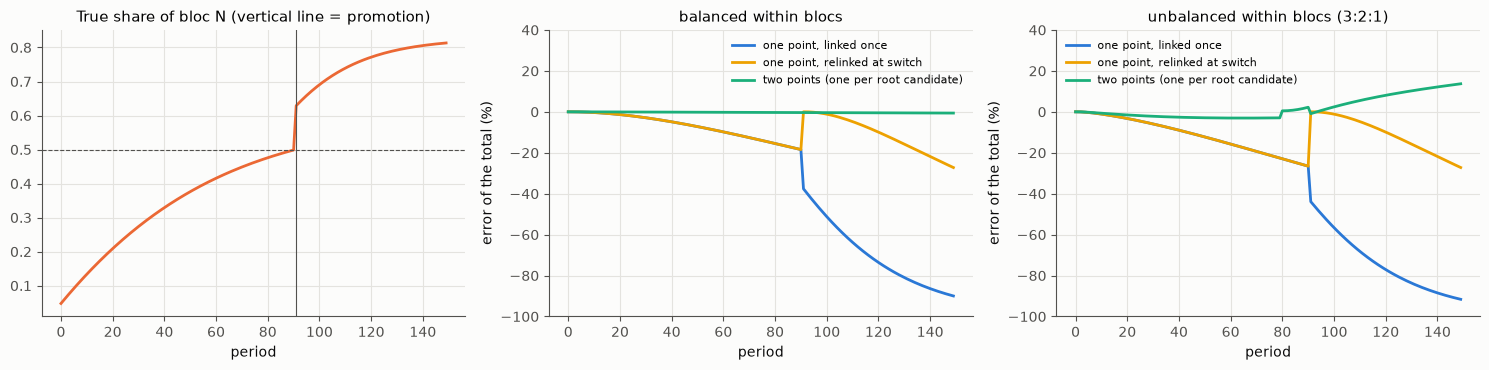

In [61]:
import hybrid
importlib.reload(hybrid)
X0S = {'balanced within blocs': (2, 2, 2, 0.1, 0.1, 0.1), 'unbalanced within blocs (3:2:1)': (3, 2, 1, 0.05, 0.1, 0.15)}
KIND = {'one': 'one point, linked once', 'one_relink': 'one point, relinked at switch', 'two': 'two points (one per root candidate)'}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for j, (lab, x0) in enumerate(X0S.items()):
    p = hybrid.params(x0=x0); X, Mo, sw = hybrid.simulate(p); tot = X.sum(1); tt = np.arange(p['T'])
    if j == 0:
        ax[0].plot(tt, X[:, 3:].sum(1) / tot, color=PAL[1]); ax[0].axhline(0.5, color=INK2, lw=0.8, ls='--')
        for s_ in sw:
            ax[0].axvline(s_, color=INK2, lw=0.8)
        ax[0].set(title='True share of bloc N (vertical line = promotion)', xlabel='period')
    print(f'{lab}: 本当の切り替え {sw}')
    for k, c in zip(KIND, (PAL[0], PAL[3], PAL[2])):
        r, swm = hybrid.reduced_path(p, X, Mo, sw, k); err = r / tot - 1
        ax[j + 1].plot(tt, 100 * err, color=c, label=KIND[k])
        print(f'   {KIND[k]:38s}: 切り替え {swm}、切り替え前のずれの最大 {100 * np.abs(err[:sw[0] - 1]).max():5.1f}%、最後の期のずれ {100 * err[-1]:+6.1f}%')
    ax[j + 1].axhline(0, color=INK2, lw=0.6, zorder=0)
    ax[j + 1].set(title=lab, xlabel='period', ylabel='error of the total (%)', ylim=(-100, 40)); ax[j + 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**一点(一度だけまとめる)**(青): 切り替えの前から、ずれが育つ。二つの塊の伸びが違い、塊のあいだのつながりが弱いので、塊のあいだの構成比が動き続けるからである(定理 C: 成長率のばらつき × 構成比の動き)。切り替えの瞬間には、跳びの倍率を、古い構成比で見積もるので、ずれがさらに跳ぶ。最後には、合計の値打ちを 9 割も見誤る。

**一点(まとめ直す)**(黄): 切り替えのたびに本当の状態からまとめ直すので、切り替えの直後は、ずれが 0 に戻る。しかし、次の区間でも構成比は動き続けるので、ずれはまた育つ。

**二点(根の候補ごと)**(緑):

- 塊の中が釣り合っている場合(中央)は、ずれは最後まで 1% 以下で、切り替えの時期も本当の経路とぴったり同じである。塊の中では物差しが一つなので、跳びは集計と可換になる。塊の中の構成比も動かないので、定理 A のとおり、区間の中でも縮約は厳密に近い。
- 塊の中が釣り合っていない場合(右)は、最初のうち、塊の中の構成比が動くことによる小さなずれが出る。塊の中の構成比は定理 B のとおり落ち着いていくので、毎期のずれは小さくなっていくが、それまでにたまったずれ(3% ほど)は残る。ところが、**その小さなずれのせいで、縮約したモデルの中では、N の割合が 1/2 を超えるのが、本当の経路より 11 期も早くなる**。早すぎる時期に跳びが起き、そのあとのモードの食い違いと構成比の違いから、ずれは育ち続け、最後には 14% になる。

最後の点は、ハイブリッド系に特有の、もう一つの壊れ方である。

5. **ガードの時期のずれ**: 引き金の近くでは、状態の小さなずれが、切り替えの時期のずれになり、跳びが違う時期に起きることで、大きなずれに育つ。

第 3 章のペニーオークションで、写像の傾きが 1 より大きい所では、わずかなずれが大きく増幅されることを見た。引き金の近くは、同じように、わずかなずれが大きな違いになる場所である。格上げの**時期**を予測することは、格上げの**仕組み**を理解することより、ずっと難しい。

### 8.5 まとめ: 縮約と格上げは、同じ問いの二つの面

| | 縮約(「信用の世界経済は一つか」) | 格上げ(このノート) |
|---|---|---|
| 扱うもの | モードの中の流れ | モードの切り替え(ガードとリセット) |
| 成り立つ条件 | つながりがあり、釣り合い経路の近くで、折れ目を越えず、収穫逓増が強すぎない | 跳びが保存を守ること |
| 壊れ方 | 折れ目、収穫逓増、遠く離れる | それらに加えて、評価の跳び、ガードの時期のずれ |
| 最小の描き方 | 一つの国 | 根の候補ごとに一点(その間の比を状態として持つ) |

2011 年の作者の直感「経済の一部としてバーチャルに動いている経済が、カタストロフィックに全体に格上げされる」は、縮約の言葉では、こう言える。**平時には、世界を一つの国として描く縮約がよく効く。その平時の縮約の中で、まとめて一点として見られていた部分(バーチャルな経済)が育ち、縮約の条件が少しずつ崩れ、最後に、物差しの跳びとともに、まとめ方そのものが入れ替わる**。縮約の定理は、遷移のない区間でだけ成り立ち、格上げはその区間の境目である。だから、縮約の定理を本当に使うには、境目がどこにあるか(どの引き金が、いつ引かれるか)を、別に見張っていなければならない。

### 8.6 Lean: 区間ごとの縮約

8.3 節の「区間ごとの縮約」を証明する。縮約の定理 A そのものは、リポジトリ credit_simulation_v6 の `CreditV6/` で証明してあり、このノートの Lean のプロジェクトからは読み込めない。そこで、定理 A の結論(一つのモードの中では、まとめる写像 agg が、世界の 1 期の写像 F と一国の 1 期の写像 f と可換: agg ∘ F = f ∘ agg)を**仮定**として置き、そこから先を示す。

- `contraction_iterate`: 一つのモードの中で 1 期が可換なら、何期続けても可換(区間の中では縮約は正しいまま)。
- `contraction_hybrid`: ハイブリッド系の一本の道を、予定表(モードと、それが続く期数)に従って流れ、区間の終わりごとにリセットする写像として書く。どのモードの流れも、リセットも、まとめる写像と可換なら、道全体が可換になる。
- `jump_depends_on_share`: 8.2 節の評価の跳びの倍率 (1 − s)/(1 + λ) + s(1 + λ) は、新しい経済の割合 s によって違う(s = 0 と s = 1 で等しいのは λ = 0 のときだけ)。
- `one_point_reset_not_commuting`: だから、一点へのまとめでは、まとめた値打ちだけからリセットのあとの値打ちを決める写像がない(リセットが可換でない)。切り替わりのたびに、本当の状態からまとめ直すしかない。
- `two_point_reset_commutes`: 根の候補ごとに一点(旧い塊と新しい塊の二点)にまとめれば、リセットは可換になる(塊の中の物差しが一つ、一物一価)。`contraction_hybrid` の仮定が満たされ、縮約は道全体で正しい。

8.4 節の数値(二点の縮約はずれ 0.4% 以下で、切り替えの時期も一致した)は、塊の中が釣り合っている場合、この定理の仮定がほぼ満たされることの確かめになっている。塊の中が釣り合っていないと(3:2:1)、塊の中で定理 A の仮定が崩れ、ガードの時期がずれた。

In [62]:
%%writefile -a embedded_economy.lean
/-! ## 第 8 章 ハイブリッド系としての経済: 区間ごとの縮約

縮約の定理 A(credit_simulation_v6 の CreditV6/ で証明)の結論、すなわち「一つのモードの中では、まとめる写像 agg が、
世界の 1 期の写像 F と一国の 1 期の写像 f と可換(agg ∘ F = f ∘ agg)」を仮定として置き、そこから先を証明する。 -/

section Hybrid
variable {X Y M : Type*}

/-- 区間ごとの縮約: 一つのモードの中で 1 期の写像が可換なら、何期続けても可換。 -/
theorem contraction_iterate (agg : X → Y) (F : X → X) (f : Y → Y) (h : ∀ x, agg (F x) = f (agg x)) :
    ∀ n x, agg (F^[n] x) = f^[n] (agg x) := by
  intro n
  induction n with
  | zero => intro x; rfl
  | succ n ih => intro x; rw [Function.iterate_succ_apply', Function.iterate_succ_apply', h, ih]

/-- ハイブリッド系の一本の道: 予定表(モード、そのモードが続く期数)の列に従って流れ、区間の終わりごとにリセットする。 -/
def run (F : M → X → X) (R : X → X) : List (M × ℕ) → X → X
  | [], x => x
  | (m, n) :: rest, x => run F R rest (R ((F m)^[n] x))

/-- どのモードの流れも、リセットも、まとめる写像と可換なら、道全体が可換(縮約はずっと正しい)。
リセットが可換でないとき(一点へのまとめ)は、切り替わりのたびに本当の状態からまとめ直す必要がある。 -/
theorem contraction_hybrid (agg : X → Y) (F : M → X → X) (f : M → Y → Y) (R : X → X) (r : Y → Y)
    (hF : ∀ m x, agg (F m x) = f m (agg x)) (hR : ∀ x, agg (R x) = r (agg x)) :
    ∀ (sched : List (M × ℕ)) (x : X), agg (run F R sched x) = run f r sched (agg x) := by
  intro sched
  induction sched with
  | nil => intro x; rfl
  | cons hd rest ih =>
    intro x
    obtain ⟨m, n⟩ := hd
    simp only [run]
    rw [ih, hR, contraction_iterate agg (F m) (f m) (hF m)]

end Hybrid

/-- 評価の跳び(8.2 節): 一点にまとめた値打ちの倍率 (1 − s)/(1 + λ) + s(1 + λ) は、新しい経済の割合 s によって違う。
s = 0 と s = 1 で倍率が等しいのは、λ = 0(跳びがない)のときに限る(Lean では λ を lam と書く)。 -/
theorem jump_depends_on_share {lam : ℝ} (h : 0 < 1 + lam) :
    (1 - 0) / (1 + lam) + 0 * (1 + lam) = (1 - 1) / (1 + lam) + 1 * (1 + lam) ↔ lam = 0 := by
  constructor
  · intro e
    have hne : (1 + lam) ≠ 0 := h.ne'
    field_simp at e
    nlinarith [e]
  · intro e; subst e; norm_num

/-- 一点へのまとめは、リセットと可換にならない: 旧い経済の値打ちを a 倍、新しい経済を b 倍にするリセットで、
a ≠ b なら、まとめた値打ち o + n だけからリセットのあとの値打ち a o + b n を決める写像 g はない。 -/
theorem one_point_reset_not_commuting {a b : ℝ} (hab : a ≠ b) : ¬ ∃ g : ℝ → ℝ, ∀ o n : ℝ, a * o + b * n = g (o + n) := by
  rintro ⟨g, hg⟩
  have h1 := hg 1 0
  have h2 := hg 0 1
  simp at h1 h2
  exact hab (h1.trans h2.symm)

/-- 根の候補ごとに一点(旧い塊と新しい塊の二点)にまとめれば、リセットは可換: 塊の中の物差しが一つ(一物一価)だから。 -/
theorem two_point_reset_commutes {ι : Type*} (O N : Finset ι) (x : ι → ℝ) (a b : ℝ) :
    (∑ i ∈ O, a * x i, ∑ i ∈ N, b * x i) = (a * ∑ i ∈ O, x i, b * ∑ i ∈ N, x i) := by
  rw [Finset.mul_sum, Finset.mul_sum]

Appending to embedded_economy.lean


## 第 9 章 まとめと、続くノートへ

### 9.1 問いへの答え

**問い 1: 2011 年のモデルは、何をしていたのか。どこが筋が良く、どこが足りなかったのか。**

- 筋が良かったのは、二つである。
  - 一つは、**お金を「マイナスの負債」として書いた**ことである。受け払いのたびに片方に足して片方から引くので、お金の総量は自動的に保存される。帳簿を付けてみると、数千の仕訳のどれも貸借が一致していた(第 4 章)。
  - もう一つは、**ルール(外作用)と戦術(内作用)を分けた**ことである。これは、ゲーム理論の「ゲームの形式」と「戦略」の区別そのもので、戦術にコピーを渡して許された操作だけを反映する作りは、戦略を安全に対戦させる仕組みとして正しい(2.4)。
- 足りなかったのは、四つである。
  - 文化(資産)が積み上がること自体は意図どおりだったが、積み上がった資産を買値のまま評価し、それが次の値付けを押し上げる回り方のために、値段が値段を呼ぶ泡の形で発散した(2.3)。
  - 最初の負債の貸し手が、モデルの中にいなかった(2.1)。
  - 戦術を比べる「良さ」(利得)の基準がなかった(2.4)。
  - 戦術を市場に反映する部分に誤りがあり、戦術は実際には効いていなかった(2.4)。直して正味資産を利得として試すと、得をする戦術は、安い競争相手に供給を減らさせて値をつり上げる、カルテルの戦術だった。真似されて全員に広がると、得は消え、社会全体は豊かにならない(2.5)。
- 価格の決め方(必需品のメリットオーダー、嗜好品のセカンドプライス型の競り)は、知られた仕組みの独自の再発明だった(2.2)。自分で作った嗜好品を自分で買う取引は、作者の意図した動きで、値を付けることそのものの力を映している(4.3)。

**問い 2: 「埋め込み」の中で、まったく違う経済が育つとは、どういうことか。モデル化できるのか。**

できる。小さな模型(第 6 章)で、次のことが起こせた。

- 新しい経済は、旧い経済の中に、まとめて一つの点として見られる部分(バーチャルな経済)として育つ。
- 格上げは、**根**(何で測るか、どこを細かく見てどこをまとめて見るか)の入れ替わりである。
- 格上げの引き金には、評価・規模・信頼の三つがある。評価が一番早く(ただし泡にだまされやすく)、信頼が一番遅い。
- 格上げの瞬間に、保存を守ったまま評価が跳び、誰も取引しないまま分け前が入れ替わる。2011 年に作者が書いた「資産減耗遷移」(資産の目減りは、少しずつではなく、枠組みの交代として一挙に起こる)が、この形で現れる。
- 根であることに得(上乗せ)があると、旧い根は新しい経済の成長を押しとどめ、新しい根はいったん定着すると戻りにくい(履歴現象、カタストロフィーの折り目)。

**問い 3: そのために要る最低限の経済原理は何か。それを書く抽象的な理論はあるか。**

- 最低限の原理は、**保存・評価・実現可能性・行動**の四つである(第 4 章)。保存は、どの枠組みでも、遷移をまたいでも守られなければならない。評価は、物差しによって変わり、遷移で跳ぶ。
- 抽象的な理論としては、**経済の圏**が使える(第 5 章)。勘定をまとめる写像(集計)は、保存を守る関手である。評価は、まとめる中で一物一価が成り立つときに限り、自然変換になる。根の入れ替えそのものは自然同型(単位の付け替え)で、分け前を変えるのは評価の跳びである。複式簿記は、差の群(パチョーリ群)という普遍的な構成として書ける。

**問い 4: それは「縮約」と、どういう関係にあるのか。**

- 縮約は、物差しが固定されたモードの中の理論で、格上げは、モードが切り替わる瞬間の理論である(第 8 章)。格上げは、縮約の壊れ方(折れ目、収穫逓増、遠く離れる)がすべてそろう場所で、さらに、評価の跳びと、引き金の時期のずれという、二つの壊れ方が加わる。
- 格上げのある世界の最小の縮約は、一つの国ではなく、**根の候補ごとに一点**である。
- 実は、2011 年の記事には、「埋め込み」が二つの意味で出てくる。本文の「集団の埋め込み」(複数のプレイヤーを統合して一人と見なせるか)は、のちの**縮約**の問いそのものである。2011 年 3 月 15 日のコメントの「資産減耗埋め込み」(埋め込まれた別の経済への遷移で、資産が一挙に目減りする)は、このノートの**格上げ**である。作者は 2011 年に、同じ言葉で、縮約と格上げの両方を思い描いていた。この二つが、同じ問いの二つの面だったことが、このノートの結論である。

**問い 5: ペニーオークションは、無尽講か。**

半分はそうである(第 3 章)。多くの人から少しずつ集めて、一人がまとめて受け取る形は、無尽講と同じである。しかし、ペニーオークションには胴元(売り手)がいて、入札料は全部そこに入る。危険中立の理論では、胴元の収入はちょうど品物の価値に等しく、参加者全体としては公平なくじに近い。データでは収入が品物の価値を大きく上回り、胴元の取り分のある賭けになっている。均衡はたくさんあり、どれが現れるかは、参加者の感じ方のばらつきと学び方で決まる。

作者が 2010 年に思い描いていたのは、競りで払う「利息」が仲間に回り、競り落とした者が機械を導入できる、**入札の無尽講**だった。模型では、入札の講は、くじの講より生産を 3 割近く大きくする(3.7)。ペニーオークションは、その利息が胴元に入り、競り落とす物が生産につながらない形である。仮想通貨の採掘は、利息にあたる費用が誰にも入らず燃える、第三の形である(3.8)。そして、無尽が相互銀行になったことは、仲間うちの金融が法によって制度に格上げされた、このノートの言葉での格上げの一つの例である(3.9)。

### 9.2 2011 年の発想を、どう発展させればよかったか

作者は、2011 年の発想を、どうすればよかったのかを知りたがっていた。このノートの結論から言えば、次の順に進めるのがよかった。

1. **帳簿を先に作る。** 全員の受け払いを仕訳として書き、外の貸し手(中央銀行・政府)を部門として置く。お金の保存は、2011 年のモデルがすでに満たしていたので、足すのは相手方の部門だけである。
2. **資産に、減耗と評価を入れる。** 文化資本を、買値ではなく時価で評価し、減耗を入れる。評価の変化を、取引とは別の勘定(再評価)に書く。
3. **戦術に利得を与えて、対戦させる。** 何を良しとするか(たとえば、一定期間の消費の効用)を決め、いろいろな戦術を対戦させ、得をした戦術が増えるようにする(Axelrod 型のトーナメントと、進化)。2.5 でその最初の一歩を試すと、勝つのはカルテルの戦術だった。だから、どの戦術を許すか(独占禁止)も、外作用(ルール)の設計に含めなければならない。
4. **仕組みだけのゲームで、出発点の問いに答える。** ペニーオークションのように、経済全体ではなく、その仕組みだけをゲームとして書く。
5. **埋め込みは、二つに分けて考える。** 集団の埋め込み(縮約)は、一物一価と構成比が落ち着くことが条件になる。資産減耗遷移(格上げ)は、根の入れ替えと評価の跳びとして書く。

### 9.3 続くノートへ

- **ノート 2(土地と知財と借金)**: 2011 年のモデルの資産は、減耗も収益もなく発散した。2019 年の「資産市場の簡易シミュレーション」は、土地(減価しない資産)と知的財産(減価する資産)の市場を作って、これを直そうとした。ノート 2 では、このノートの第 2・4 章(資産の発散、評価と保有利得)を出発点に、平時の資産の評価(減耗率 $\delta$、時価、担保としての土地)を扱い、このノートの格上げ(遷移のときの一挙の再評価)を、平時の定率の減耗とは別の「資産減耗遷移」として並べた(ノート 2 第 5 章)。
- **ノート I(必需品と贅沢品の宇宙的独立関係)**: 第 6 章の模型では、新しい技術は外から与えた。作者の「必需品と贅沢品の宇宙的独立関係」は、贅沢品を「何が当たるかわからない探索」と見る考えだった。ノート I では、新しい経済の芽がどこから来るかを、探索と活用、そして学習の問題として書いた(ノート I 第 6・8 章)。
- **ノート 3(シミュレーション仏教の経済)**と**ノート 4(2026年の経済モデル統合)**: 四つの原理(保存・評価・実現可能性・行動)を骨組みにした。ノート 4 は、帳簿の骨組み(ノート 4 第 2 章)から模型を組み、格上げを、新しい財の工房が育つ別枠の模型として試した(ノート 4 第 15 章。結論は「格上げならず」で、ブラウザの版では遊びの出来事として入れた)。

### 9.4 模型にできないもの: 弁証法とアレーテイア

作者は、格上げについて、もう一つの直感を持っていた。格上げには、ある種の**弁証法**、あるいは**アレーテイア**(哲学者の田島正樹がいう、驚きをもって真実が発見されること)のような面がある。根や圏で表せるものとは根本的に違う「何か」が、創造的に現れうる、という直感である。

このノートの模型は、その直感の全部を捉えたものではない。何が捉えられ、何が捉えられないかを、はっきりさせておく。

**捉えられたもの.** 格上げの前と後の、**構造**である。

- 新しい経済が、旧い経済の中で、一つの点としてまとめて見られる(バーチャル)。
- 格上げの後には、旧い経済が、新しい根の中で、一つの点としてまとめて見られる(第 5.4 節)。旧い経済は消えるのではなく、否定されつつ、新しい全体の一部として保存される。これは、ヘーゲルの**止揚**(否定し、保存し、高める)の形そのものである。
- 格上げの瞬間に、保存を守ったまま、評価が跳ぶ。

**捉えられなかったもの.** 新しいものが**現れること**そのものである。

- 第 6 章の模型では、新しい経済 N は、最初から候補として用意されていた。圏の言葉も、すでにある対象のあいだの関係を書くものである(第 5.6 節)。何が新しく現れるかは、模型の構造からは出てこない。
- 作者は、弁証法を「矛盾などを解消するために、理論のパラメータを一つ足す行為」と考えてきた(『宗教学雑考集』「コンピュータ定理証明における弁証法」、cocolog:95757823)。この見方に立つと、格上げのたびに、模型そのものに新しい次元(新しい財、新しい物差し、新しい根の候補)が一つ足される。足された次元の中での動きは模型にできるが、**どの次元が足されるか**は、模型の外から来る。それが、驚きとして発見されるもの(アレーテイア)である。

だから、このノートの模型は、創造的な出来事を、その前後の評価の構造として描いた、**巨視化**の一つと位置づけるのが正しい。現れるものの中身は描けないが、現れたあとで、それが旧い経済をどう組み替えるか(誰が得をし、誰が損をし、何が保存されるか)は描ける。

なお、何が現れるかの中身は描けなくても、**現れ方の頻度や分布**なら、模型にできる余地がある。新しい次元を探す活動(贅沢品、研究、投機)を、当たり外れのわからない探索として書けばよい。これが、続く「必需品と贅沢品の宇宙的独立関係」のノートの主題になる。

### 9.5 残る問い

- **政府と借金**: 通貨改革で最も大きく得をしたのは、模型にいない債務者(政府)だった(7.3)。入れ子の経済の模型に、政府と借金を入れる。
- **泡の費用**: 模型の泡には費用がなく、泡は大きいほど良く見えた(7.1)。泡の崩壊に、信用循環モデルの負債の重荷と金融危機をつなぐ。
- **根の上乗せはどこから来るか**: 模型では、根の上乗せ $\lambda$ を外から与えた。担保、決済、ネットワーク効果から、上乗せがどう生まれるかを、模型の中で決める。
- **入れ子を深くする**: 子の中の孫、いくつもの子の競争、作者の言う「埋め込まれた先に、元の経済が埋め込まれている」入れ子。
- **引き金を測る**: 規模・評価・信頼の三つを、現実のデータ(産業の生産の割合、時価総額の割合、貿易の請求に使われる通貨の割合や外貨準備の割合)で測り、どれが格上げを早く、確かに知らせるかを調べる。
- **Lean**: 集計が保存を守ることと、一物一価の命題(5.3)は v0.2 で、区間ごとの縮約(8.3)は v0.2.1 で、Lean で証明した(5.7 節、8.6 節)。区間ごとの縮約は、定理 A の結論を仮定として置いた形で、定理 A そのものとの結合(CreditV6/ の読み込み)は残る。

---

### 9.6 Lean による一括の確かめ

章ごとに書き足してきた `embedded_economy.lean` の最後に、名前空間を閉じる行を足し、Lean に一括して確かめさせる(Lean 4 v4.34.1 と Mathlib の入った lake のプロジェクトの場所を、このノートと同じディレクトリの `.leandir` に一行で書いておく)。

In [63]:
%%writefile -a embedded_economy.lean
end EmbeddedEconomy

Appending to embedded_economy.lean


In [64]:
import os, shutil, subprocess
LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if LEANDIR:
    lake = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
    env = dict(os.environ, PATH=os.path.dirname(lake) + ':' + os.environ.get('PATH', ''))
    path = os.path.abspath('embedded_economy.lean')
    r = subprocess.run([lake, 'env', 'lean', path], cwd=LEANDIR, capture_output=True, text=True, env=env)
    print(r.stdout[-3000:], r.stderr[-3000:])
    n_thm = sum(1 for line in open(path) if line.startswith('theorem '))
    print(f'=== embedded_economy.lean: {n_thm} 個の定理を確かめた。終了コード {r.returncode}(0 なら、すべての証明が通った) ===')
    assert r.returncode == 0
else:
    print('Lean のプロジェクトがない(.leandir がない)ので飛ばす。Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトの場所を .leandir に一行で書く')

 
=== embedded_economy.lean: 11 個の定理を確かめた。終了コード 0(0 なら、すべての証明が通った) ===


## 付録 A: 再現のために

### A.1 このノートが書き出すファイル

このノートは、実行すると、作業ディレクトリに次のファイルを書き出す。どれも `%%writefile` のセルの中身そのものである。

| ファイル | 中身 | 章 |
|---|---|---|
| `sm0_perl.py` | 2011 年の Perl のコードの取得(sha256 の確認)、ハッシュの順序を固定した実行、順序だけの直しと戦術の反映の直し | 1.2、2.4 |
| `sm0.py` | 2011 年のモデルの Python への移植(Perl とぴったり同じ計算)。価格の決め方と減耗を変えるオプション | 1.3、2.2、2.3 |
| `tactics.py` | 2011 年のモデルで戦術を取らせ、その得を比べる(一人だけの逸脱、トーナメント) | 2.5 |
| `penny.py` | ペニーオークションの理論(混合均衡、感じる費用のばらつきがある均衡、写像の傾き)、学習するエージェント、入札の無尽講 | 3 |
| `ledger.py` | パチョーリ群、仕訳帳と集計、2011 年のモデルに帳簿を付けた版、評価の比較 | 4 |
| `econ_cat.py` | 集計の関手性と見える受け払い、一物一価と粗い見方のずれ、根の見え方 | 5 |
| `nest.py` | 入れ子の経済の模型(泡、根の上乗せ、単位の採用、三つの引き金、政策、通貨改革、熱狂) | 6、7 |
| `hybrid.py` | 線形のハイブリッド系と、三通りの縮約 | 8 |
| `orig_cache/` | GitHub から取ってきた 2011 年のコードと、直した版 | 1.2 |

### A.2 実行環境

In [65]:
import sys, platform
print('Python', sys.version.split()[0], '/', platform.platform())
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__, '/ perl', perl_v)
print('2011 年のコード: JRF-2018/simple_market_0 commit', sm0_perl.COMMIT)
print('FAST =', FAST, '/ 並列', N_JOBS)

Python 3.14.4 / Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2 / perl v5.40.1
2011 年のコード: JRF-2018/simple_market_0 commit c03bbcb1f60ee6913a5f14ab54c68026371b20f4
FAST = False / 並列 8


2011 年のコードは、当時の Perl で書かれた。今の Perl(5.18 以降)はハッシュの順序を実行ごとに変えるので、このノートでは、環境変数 `PERL_HASH_SEED=0`、`PERL_PERTURB_KEYS=0` で順序を固定して走らせた(1.2)。さらに、Python 版とぴったり同じ計算をさせるために、繰り返しに使う `keys` を `sort keys` に替えた版を使った(1.3)。乱数は、Perl 5.20 以降の `rand` と同じ drand48 を Python で書いたものである。Perl の版が違うと、乱数の作り方が違い、数字は変わりうる。

## 付録 B: 用語集

| 用語 | 意味 |
|---|---|
| 外作用・内作用 | 作者の言葉。全員に同じように効く市場のルールと、プレイヤーがルールの中で取る戦術 |
| メリットオーダー | 費用の安い順に、必要量に達するまで売り手を使う決め方 |
| セカンドプライス(ヴィックリー)型の競り | 一番高い値を付けた人が、二番目の値で買う競り |
| 複式簿記・仕訳 | すべての取引を、借方と貸方に同じ額で書く方法。一つの取引の記録が仕訳 |
| T 勘定・パチョーリ群 | 借方と貸方の組 $[\,d\ //\ c\,]$。差だけが意味を持つとみなすと、群になる(Ellerman) |
| 差の群(グロタンディーク群) | 足し算だけの世界から、差を考えて、引き算のできる群を作る、ただ一つに決まった作り方 |
| 自己勘定の資本形成 | 自分で作って、自分で使う資本。国民経済計算では生産として数える |
| 仮装売買 | 自分で売って自分で買い、値を作ること。株式の市場では禁じられている |
| 保有利得・損失、再評価勘定 | 持っているあいだに値段が変わったことによる得や損。取引とは別の勘定に書く |
| 圏・対象・射 | 「もの」と「もののあいだの矢印」と、矢印のつなぎ方の組 |
| 関手 | 圏から圏への、合成を保つ写像 |
| 自然変換・可換図式 | 二つの関手のあいだの、どちらの道を通っても同じになる変換の族 |
| 一物一価 | 同じものには同じ値段が付くこと |
| 根 | このノートの言葉。どの経済の物差しで測り、どこを細かく見て、どこをまとめて見るかの基準 |
| バーチャルな経済 | このノートの言葉。外から一つの点としてまとめて見られ、中の取引が見えない経済 |
| 格上げ | このノートの言葉。バーチャルだった経済が根になること |
| 引き金(規模・評価・信頼) | 格上げを決める条件。実物の生産の割合、資産の値打ちの割合、その単位を使う人の割合 |
| 根の上乗せ・利便性の利回り | 根の経済の資産が、担保や決済に使えることで、高く評価される分 |
| 泡(バブル) | 資産の値打ちが、基礎的な価値を超えて膨らむこと |
| ライトの法則・作りながら学ぶ | 累計の生産(投資)が増えるほど、生産性が上がること |
| トービンの q | 資本の市場の値打ちと、作り直す費用の比。高いほど投資が増える |
| ネットワーク効果 | 使う人が多いほど、便利になること |
| 履歴現象・折り目(カタストロフィー) | 行きと帰りで道が違うこと。条件がゆっくり変わっても、落ち着き先の一方が消える点で状態が跳ぶこと |
| ハイブリッド系(モード・ガード・リセット) | 連続的な動きと、条件で起こる離散的な跳びを組み合わせた系 |
| 縮約 | いくつもの経済を、一つ(または少数)の経済として描くこと |
| 釣り合い経路 | どの部分も同じ率で伸び、構成比が変わらない経路 |
| 混合戦略均衡 | 参加者が、確率的に行動を選ぶ均衡 |
| レントの散逸 | 得られるはずの利益が、競争のための費用として使い果たされること |
| 純粋化(ハーサニ) | 一人一人の感じ方のばらつきを入れると、混合戦略均衡が、各自の決まった選択の集まりとして現れること |
| 仮想プレイ | 相手のこれまでの行動の頻度から、次の行動を予想して最善の手を選ぶ学び方 |
| 回転型貯蓄信用講(ROSCA)・無尽講・頼母子講 | 仲間が掛け金を出し合い、順番に一人がまとめて受け取る仕組み |
| 入札講(入札の無尽講) | 早く受け取りたい人が割引(利息)を申し出て競り、その利息をほかの仲間で分ける無尽講 |
| プルーフ・オブ・ワーク(採掘) | 計算の費用を払って暗号を当てた者が、新しい通貨を受け取る仕組み |
| 出し惜しみ | 売り手がわざと供給を減らして、市場の値をつり上げること |
| インデックス付き圏・グロタンディーク構成 | 土台の圏(ここではモード)の各対象に圏を載せたもの。それを一つの圏にまとめる、ただ一つに決まる作り方 |
| 止揚 | ヘーゲルの言葉。否定し、保存し、高めること |
| アレーテイア | ギリシア語で「隠れなさ」、真実。作者は、驚きをもって真実が発見されること、の意味で使う |

## 付録 C: 過去の議論

この文書の材料になった作者の記事と、その後の言及を、古い順に挙げる。ブログの記事 ID(cocolog:…)は、http://jrockford.s1010.xrea.com/cocolog_helper/id2url.cgi?q=cocolog:… で記事の URL に直せる。

- **2010 年 12 月 27 日**(aboutme:135109): 「入札料を取るネットオークションは、まともにやれば無尽や頼母子講の現代版になるのではないか」。長く伸ばせば、競りで利息を払い切った者が工作機械を導入できる、という入札講の構図と、今は競り落とす物が生産につながらず胴元だけが得をしている、という疑い(2.6、3.7)。
- **2011 年 1 月**: 「外作用的簡易経済シミュレーションのアイデアと Perl による実装」。外作用と内作用、マイナスの負債としての現金、必需品と嗜好品。本文の終わりに「集団の埋め込み」(複数の player を統合して一人と見なせるか)の構想。出発点の問いは「ペニーオークションは無尽講ではないか」。
- **2011 年 2 月**: 同記事のコメント欄。戦術(DesireGreedConvertTactics)の更新。
- **2011 年 3 月**: 同じ時期に、同じ Perl で、はてなポイントの分配プログラム(`calc_bonus_bookmark_point.pl`。基金の 1/3 支出、平方根のボーナス、1.05 乗の上限のペンション、ID 統合の待ち期間)と、BI が否認されたときに受け取ったポイントをどう返すかの計算(`point_back_with_rejected_bi.pl`)を書いていた。分配の記事は、外作用モデルを「投稿時期に近いころに Perl で書いていた別のシミュレーション」として挙げている。中央銀行モデルと並ぶ、制度の側のアイデアである(ノート P「ポイントと年金と信用」で扱った)。
- **2011 年 3 月 15 日**: 同記事のコメント欄。大震災の直後に、「資産減耗遷移(または資産減耗埋め込み)」「公共財遷移」「中央銀行モデル」の三つのアイデアを書き残した。このノートの格上げ(第 5〜8 章)は、一つ目を、中央銀行モデル(2.1、4.3 の外の貸し手)は、三つ目を受け継いでいる。
- **2012 年 12 月**: 同記事のバージョン 1.05(必需品の生産の誤りの修正)。このノートが使った版。
- **2018〜2020 年**: 「ミクロ経済学の我流シミュレーション」その1〜その5(ノート 1)。
- **2019 年 5 月**(cocolog:91037236): 「資産市場の簡易シミュレーション」。2011 年のモデル(simple_market_0)の後継として作られた。
- **2021〜2022 年**(cocolog:93150989): 我流シミュレーションの発展の構想(資本主義の基礎等式、知財 = 株価総額、担保としての土地)。
- **2025 年 1 月 12 日**(cocolog:95231675): 「ビットコインのような仮想通貨は、現代版の無尽や頼母子講になるのではないか。くじで当たった者に資金がいくのは、暗号を当てた者に権利がいく仕組みだ」(3.8、3.9)。
- **2025 年 1 月**(cocolog:95227325): AI と資本主義。「和や最大値による多目的最適化とは違う、システムや主体が切り換わる最適化」という問題意識。このノートの根の入れ替えは、「主体が切り換わる」ことの一つの書き方である。
- **2025 年 12 月**(cocolog:95757823): 弁証法を「矛盾などを解消するために、理論のパラメータを一つ足す行為」とする作者の考え(9.4)。
- **2026 年 9 月**: 「AI社会における再分配問題 ── アスモグルらの議論から」(misc_ipynb)。AI 経済と人間経済、接続口(7.5)。
- **2026 年 10 月**: 「信用創造はどこで止まるのか」「信用の世界経済は一つか」(credit_simulation_v6)。縮約の定理 A・B・C(第 8 章)。

---

## 参考文献

### 作者の記事・コード・ノート

- JRF「外作用的簡易経済シミュレーションのアイデアと Perl による実装」(2011 年 1 月、2012 年 12 月まで更新)、ブログ『JRF の私見:税・経済・法』: http://jrf.cocolog-nifty.com/society/2011/01/post.html
- JRF, simple_market_0(Perl のコード): https://github.com/JRF-2018/simple_market_0 (このノートは commit `c03bbcb` を使う)
- JRF「資産市場の簡易シミュレーション」(2019 年 5 月): http://jrf.cocolog-nifty.com/society/2019/05/post-9da6e7.html
- JRF「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(ノート 1、2026 年)。
- JRF「信用の世界経済は一つか」(2026 年)、https://github.com/JRF-2018/credit_simulation_v6
- JRF ほか「AI社会における再分配問題 ── アスモグルらの議論から」(2026 年): https://github.com/JRF-2018/misc_ipynb

### ペニーオークションと無尽講

- Augenblick, N. (2016), "The Sunk-Cost Fallacy in Penny Auctions", *Review of Economic Studies* 83(1), 58–86.
- Hinnosaar, T. (2016), "Penny Auctions", *International Journal of Industrial Organization* 48, 59–87.
- Platt, B. C., Price, J., and Tappen, H. (2013), "The Role of Risk Preferences in Pay-to-Bid Auctions", *Management Science* 59(9), 2117–2134.
- Harsanyi, J. C. (1973), "Games with Randomly Disturbed Payoffs: A New Rationale for Mixed-Strategy Equilibrium Points", *International Journal of Game Theory* 2(1), 1–23.
- Besley, T., Coate, S., and Loury, G. (1993), "The Economics of Rotating Savings and Credit Associations", *American Economic Review* 83(4), 792–810.
- Kovsted, J. and Lyk-Jensen, P. (1999), "Rotating Savings and Credit Associations: The Choice between Random and Bidding Allocation of Funds", *Journal of Development Economics* 60(1), 143–172.
- Budish, E. (2018), "The Economic Limits of Bitcoin and the Blockchain", NBER Working Paper 24717.
- Vickrey, W. (1961), "Counterspeculation, Auctions, and Competitive Sealed Tenders", *Journal of Finance* 16(1), 8–37.
- Borenstein, S., Bushnell, J. B., and Wolak, F. A. (2002), "Measuring Market Inefficiencies in California's Restructured Wholesale Electricity Market", *American Economic Review* 92(5), 1376–1405.
- 無尽業法(大正 4 年)、相互銀行法(昭和 26 年)。

### 簿記・国民経済計算・ストック・フロー一貫モデル

- Ellerman, D. P. (1985), "The Mathematics of Double Entry Bookkeeping", *Mathematics Magazine* 58(4), 226–233.
- European Commission, IMF, OECD, United Nations, and World Bank (2009), *System of National Accounts 2008*, New York.
- Godley, W. and Lavoie, M. (2007), *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.
- 金融商品取引法 第 159 条(相場操縦行為等の禁止)。

### 圏論・ハイブリッド系・カタストロフィー

- Mac Lane, S. (1971), *Categories for the Working Mathematician*, Springer.
- Lawvere, F. W. (1973), "Metric Spaces, Generalized Logic, and Closed Categories", *Rendiconti del Seminario Matematico e Fisico di Milano* 43, 135–166.
- Fong, B. and Spivak, D. I. (2019), *An Invitation to Applied Category Theory: Seven Sketches in Compositionality*, Cambridge University Press.
- van der Schaft, A. and Schumacher, H. (2000), *An Introduction to Hybrid Dynamical Systems*, Lecture Notes in Control and Information Sciences 251, Springer.
- Thom, R. (1972), *Stabilité structurelle et morphogenèse*, W. A. Benjamin.
- Zeeman, E. C. (1977), *Catastrophe Theory: Selected Papers, 1972–1977*, Addison-Wesley.
- Buchanan, M.(2000)、水谷淳訳『歴史は「べき乗則」で動く』ハヤカワ文庫 NF、2009 年(2011 年の記事が参照した、内作用と外作用の臨界の一致)。

### 技術革命・覇権・通貨

- Perez, C. (2002), *Technological Revolutions and Financial Capital: The Dynamics of Bubbles and Golden Ages*, Edward Elgar.
- Perez, C. (2009), "The Double Bubble at the Turn of the Century: Technological Roots and Structural Implications", *Cambridge Journal of Economics* 33(4), 779–805.
- Arrighi, G. (1994), *The Long Twentieth Century: Money, Power, and the Origins of Our Times*, Verso.
- Eichengreen, B. and Flandreau, M. (2009), "The Rise and Fall of the Dollar (or When Did the Dollar Replace Sterling as the Leading Reserve Currency?)", *European Review of Economic History* 13(3), 377–411.
- Krishnamurthy, A. and Vissing-Jorgensen, A. (2012), "The Aggregate Demand for Treasury Debt", *Journal of Political Economy* 120(2), 233–267.
- Dowd, K. and Greenaway, D. (1993), "Currency Competition, Network Externalities and Switching Costs: Towards an Alternative View of Optimum Currency Areas", *Economic Journal* 103(420), 1180–1189.
- Matsuyama, K., Kiyotaki, N., and Matsui, A. (1993), "Toward a Theory of International Currency", *Review of Economic Studies* 60(2), 283–307.
- Acemoglu, D. and Robinson, J. A. (2006), "Economic Backwardness in Political Perspective", *American Political Science Review* 100(1), 115–131.
- Castronova, E. (2001), "Virtual Worlds: A First-Hand Account of Market and Society on the Cyberian Frontier", CESifo Working Paper No. 618.

### 進化・ゲーム

- Maynard Smith, J. and Szathmáry, E. (1995), *The Major Transitions in Evolution*, W. H. Freeman.
- Axelrod, R. (1984), *The Evolution of Cooperation*, Basic Books.

### 哲学

- Hegel, G. W. F. (1812–1816), *Wissenschaft der Logik*(止揚)。
- JRF『宗教学雑考集』(JRF 電版)、「コンピュータ定理証明における弁証法 ── 私が作りたいシステム」。